# MMA3001 · PMSM temperature estimation

## Notebook 1: Development evidence and numerical investigations

**Author:** Fatah Idris Putra Daulay · Monash University · 2026

This revision preserves the supplied scientific procedures. Original input notebooks, all saved outputs and complete code changes are retained in `provenance/` and `docs/METHODOLOGY_DIFF.md`. See `docs/KNOWN_ISSUES.md` before interpreting a result. Citations use author–year consistently; full records are in the final bibliography and `references.bib`.

**Evidence status:** outputs attached to original cells are historical until a new execution replaces them. Metadata records each cell's original index. The execution reports identify exactly which cells ran, errors and resource limits.

## Fixed engineering objective and research questions

**Engineering objective:** estimate the permanent-magnet temperature (°C) of a PMSM using observable electrical, mechanical and thermal operating conditions.

**Research aim:** investigate accurate and computationally feasible regression methods using profile-disjoint validation and historical numerical experiments.

- **RQ1 — Leakage-safe time-series validation:** How should temporally correlated motor recordings be processed and assigned to folds without overlapping profiles or using future samples in causal features?
- **RQ2 — Baseline model accuracy–cost:** Under the original Bayesian optimisations, what accuracy and computational costs arise for OLS, k-NN, Random Forest, Extra Trees and MLP?
- **RQ3 — SVR feasibility:** How do exact RBF-SVR, matched-kernel Nyström approximations and direct LinearSVR compare as the number of training observations increases?
- **RQ4 — Numerical evidence:** How do numerical checks, grouped-fold variability, timing, convergence and regularisation sensitivity support or limit the development-stage conclusions?

## Execution contract

Install the pinned environment using the README, then run top to bottom. Set `PMSM_CSV_PATH` for the manual original-CSV route, or use public Kaggle version 3. Data are never repaired or silently changed. `full` executes all supplied experiments; this cannot recreate historical searches that are absent from the upload. `smoke` is a software check, never a scientific reproduction. Start a new output directory for each run.


**Delivered full-run evidence (25 October 2026).** All 67 code cells in this supplied development notebook completed, including the original eight-trial Bayesian OLS pilot and every supplied Stage 9 experiment through full-development LinearSVR. The historical long baseline Bayesian archive remains absent. The Stages 1–8 intermediate verification summary describes that earlier scope only; it precedes Stage 9.

Execution environment: Python 3.12.14, scikit-learn 1.6.1. See `../docs/reports/EXECUTION_REPORT.md` for actual run records, warnings, retrieval limits and timing boundaries. The archived originals preserve historical outputs separately.


**Navigation:** [README](../README.md) · [Methodology](../docs/METHODOLOGY.md) · [Known issues](../docs/KNOWN_ISSUES.md)



## Engineering purpose and scope

Rotor permanent-magnet temperature is difficult to measure directly in ordinary service because the rotor turns, while excessive temperature can limit motor performance and damage magnets. The experimental target is therefore a virtual temperature sensor, \(\hat T_{pm}\), calculated from observable electrical, mechanical and thermal conditions. It is a regression estimate of the recorded magnet surface temperature, not a certified protection system or a prediction of time to failure. The principal source is Kirchgässner, Wallscheid and Böcker (2021), whose test-bench telemetry supplies measured temperature labels.

This project's independent contribution lies in its own profile allocation, computational verification, sampled SVR comparisons and regularisation/scalability investigations. The twelve predictors and exponential thermal-memory construction are adapted from the benchmark. OLS, nearest neighbours, tree ensembles, MLP, support-vector regression, QR and Nyström are established methods, not new algorithms claimed by the student. The paper reports about 139 hours and a two-profile holdout; this CSV has about 184.84 sample-hours, 69 profiles and this project uses 14 held-out profiles. Its MLP implementation and optimisation budget also differ from the paper. Consequently the investigation is an adaptation on the public dataset, not an exact reproduction of the paper's numerical benchmark.

No new scientific hypothesis is attributed retrospectively to the student. The investigative purposes below explain the experiments that actually exist. Temperature thresholds, sensor noise distributions, safety acceptance criteria and transfer to other motor designs were not established by the supplied work.


# Development investigation: supplied Stages 1–9

Stages 1–8 in the supplied file reconstruct a restricted verification scope. Stage 9 contains additional executable sampled SVR experiments, numerical sensitivity checks and full-development LinearSVR training. A full run of **this supplied notebook** executes all of those procedures in order, retaining every scientific setting. Historical long baseline Bayesian searches are not present in the attachment and cannot be reconstructed from their winners. Their absence is a provenance limitation for RQ2, not permission to invent replacement experiments.

The final 14-profile evaluation belongs to Notebook 2.


### 1A · Computational environment and source

Set a single data source. By default KaggleHub downloads the public dataset automatically. For offline/local use only, change `LOCAL_CSV` to a `Path` pointing at your copy of `measures_v2.csv`. All generated artifacts are written to `OUTPUT_DIR`, not loaded from previous sessions.

The original project's dataset contained **1,330,816 rows and 69 recording profiles**, sampled at **2 Hz**. A SHA-256 checksum is used to detect changes to the raw file. This protects against silently reproducing experiments on a different version of the dataset.

In [1]:
# Portable repository bootstrap: run from the repository root or notebooks/.
import os, sys
from pathlib import Path
start = Path(os.environ.get('PMSM_PROJECT_ROOT', Path.cwd())).resolve()
PROJECT_ROOT = next((p for p in [start, *start.parents]
                     if (p / 'src' / 'pmsm_project').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Extract the complete project; set PMSM_PROJECT_ROOT to its root.')
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from pmsm_project.data import resolve_csv, file_sha256, validate_dataset
from pmsm_project.validation import allocate_profiles, assert_locked_partition
print('Project root:', PROJECT_ROOT)


from pathlib import Path
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import train_test_split

FS_HZ = 2.0
SPLIT_SEED = 42
TEST_FRACTION_BY_PROFILE = 0.20
DATASET_HANDLE = "wkirgsn/electric-motor-temperature"
EXPECTED_SHA256 = "78f3d150f0f2ad9c5dc7ff24dd12c00d386ad530f48c1589ad24fcd88867d3ad"
LOCAL_CSV = os.environ.get("PMSM_CSV_PATH", "").strip() or None

DEV_MODE = os.environ.get('PMSM_RUN_MODE', 'full').strip().lower()
if DEV_MODE not in {'full','smoke'}: raise ValueError('PMSM_RUN_MODE must be full or smoke')
OUTPUT_DIR = Path(os.environ.get('PMSM_OUTPUT_DIR', str(PROJECT_ROOT / 'results'))) / DEV_MODE / 'development'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
csv_path = resolve_csv(PROJECT_ROOT, LOCAL_CSV)

actual_sha256 = file_sha256(csv_path)
if actual_sha256 != EXPECTED_SHA256:
    raise ValueError(
        "Raw dataset checksum differs from the verified measures_v2.csv. "
        "Check the dataset version before proceeding. "
        f"Expected {EXPECTED_SHA256}; received {actual_sha256}"
    )

print("Source:", csv_path)
print("Raw CSV (MB):", round(csv_path.stat().st_size / 1e6, 2))
print("SHA-256 verified:", actual_sha256)

Project root: /workspace/scratch/0a8876c2681b/deliverables/mma3001_project
Source: /workspace/scratch/0a8876c2681b/project_sources/09-PMSM-Electric-Motor-Temperature-Measurement.csv
Raw CSV (MB): 300.06
SHA-256 verified: 78f3d150f0f2ad9c5dc7ff24dd12c00d386ad530f48c1589ad24fcd88867d3ad


### 1B · Data dictionary and engineering target

One row contains the electric motor's measured operating conditions at one time step; consecutive rows within one `profile_id` correspond to successive samples of that session. The dataset does **not** contain an explicit timestamp column, so relative elapsed time is inferred from the within-profile row order and the 2 Hz sampling rate.

- **Prediction target:** `pm` — permanent-magnet temperature (°C).
- **Potential raw inputs** include `ambient`, `coolant`, `motor_speed`, `torque`, `u_d`, `u_q`, `i_d`, `i_q`. The final predictor set will be defined in Stage 2 rather than assuming every CSV column is permissible.
- **Grouping key:** `profile_id` — identifier for an individual motor test session; **not** a physical predictor.
- **Other temperature columns** (`stator_winding`, `stator_tooth`, `stator_yoke`) are present in the raw dataset; their appropriateness as model inputs requires an explicit engineering justification before use.

Question to check your understanding: *If two rows are measured 0.5 s apart, do you expect their magnet temperatures to be statistically independent? Why not?*

In [2]:
df = pd.read_csv(csv_path)
EXPECTED_COLUMNS = {
    'u_q','coolant','stator_winding','u_d','stator_tooth','motor_speed',
    'i_d','i_q','pm','stator_yoke','ambient','torque','profile_id'
}
assert set(df.columns) == EXPECTED_COLUMNS, f"Unexpected columns: {list(df.columns)}"
assert len(df) == 1_330_816, f"Unexpected record count: {len(df)}"
assert df.profile_id.nunique() == 69, "Unexpected number of measurement profiles"
assert df.profile_id.notna().all()

print(f"Observations: {len(df):,}")
print(f"Variables: {len(df.columns)}")
print(f"Profiles: {df.profile_id.nunique()}")
print(f"Sampling interval: {1/FS_HZ} s")
print(f"Recorded sample-duration sum: {len(df)/(FS_HZ*3600):.2f} h")
display(df.head(3))
DATA_VALIDATION = validate_dataset(df)


Observations: 1,330,816
Variables: 13
Profiles: 69
Sampling interval: 0.5 s
Recorded sample-duration sum: 184.84 h


,u_q,coolant,stator_winding,u_d,stator_tooth,motor_speed,i_d,i_q,pm,stator_yoke,ambient,torque,profile_id
0,-0.450682,18.805172,19.08667,-0.350055,18.293219,0.002866,0.004419,0.000328,24.554214,18.316547,19.850691,0.187101,17
1,-0.325737,18.818571,19.09239,-0.305803,18.294807,0.000257,0.000606,-0.000785,24.538078,18.314955,19.850672,0.245417,17
2,-0.440864,18.828770,19.08938,-0.372503,18.294094,0.002355,0.001290,0.000386,24.544693,18.326307,19.850657,0.176615,17


### 1C · Basic data-quality verification

We check for **missing values**, **non-finite numerical entries**, **identical duplicate rows**, and **contiguous profile blocks**. These are necessary but not sufficient checks: a sensor can be physically wrong without being missing, duplicated, or infinite. This stage does not delete rows or invent replacement values.

A continuous profile means each profile identifier appears in exactly one uninterrupted block. This matters because the next stage will calculate historical moving features separately within each profile.

In [3]:
missing_by_column = df.isna().sum()
n_invalid = int((~np.isfinite(df.select_dtypes(include='number').to_numpy())).sum())
duplicate_rows = int(df.duplicated().sum())
profile_block_id = df['profile_id'].ne(df['profile_id'].shift()).cumsum()
number_of_blocks = int(profile_block_id.nunique())
number_of_profiles = int(df['profile_id'].nunique())

print('Missing values, total:', int(missing_by_column.sum()))
print('Non-finite numerical entries:', n_invalid)
print('Duplicate complete rows:', duplicate_rows)
print('Continuous blocks:', number_of_blocks)
print('Unique profiles:', number_of_profiles)

assert int(missing_by_column.sum()) == 0
assert n_invalid == 0
assert duplicate_rows == 0
assert number_of_blocks == number_of_profiles, 'At least one profile is disjoint in the raw ordering'

profile_summary = (
    df.groupby('profile_id', sort=True)
      .agg(observations=('pm', 'size'), pm_min=('pm','min'),
           pm_max=('pm','max'), pm_mean=('pm','mean'))
      .reset_index()
)
profile_summary['duration_hours'] = profile_summary['observations'] / (FS_HZ * 3600)
print('Checks passed. Profile summary (first five):')
display(profile_summary.head())

Missing values, total: 0
Non-finite numerical entries: 0
Duplicate complete rows: 0
Continuous blocks: 69
Unique profiles: 69
Checks passed. Profile summary (first five):


,profile_id,observations,pm_min,pm_max,pm_mean,duration_hours
0,2,19357,22.970417,45.985561,32.759597,2.688472
1,3,19248,22.751144,29.011612,26.285130,2.673333
2,4,33424,22.924950,99.396629,49.762076,4.642222
3,5,14788,25.889381,39.938965,33.213100,2.053889
4,6,40388,24.349821,93.512962,69.232339,5.609444


### 1D · Why a naive 80/20 row split is inappropriate

If the original table is cut at 80% of its rows, the cutoff falls **inside recording profile 65**, putting observations from the same session in both datasets. This undermines the intended claim that the model predicts *unseen recording sessions*; near-neighbouring samples can be very similar.

The next cell **only demonstrates** the problem. It does not create the retained split.

In [4]:
row_cut = int(len(df) * 0.80)
naive_dev = df.iloc[:row_cut]
naive_test = df.iloc[row_cut:]
naive_overlap = set(naive_dev.profile_id.unique()) & set(naive_test.profile_id.unique())

print('Naive 80% row cutoff:', row_cut)
print('Profiles shared between partitions:', sorted(naive_overlap))
assert naive_overlap == {65}, 'Expected demonstration changed; inspect row ordering'
del naive_dev, naive_test

Naive 80% row cutoff: 1064652
Profiles shared between partitions: [np.int64(65)]


### 1E · Stratified **grouped** development/test split

**Grouped** = assign entire recording profiles to one side of the partition. **Stratified** = preserve representation of low-, medium-, and high-temperature sessions. In the earlier code, each profile was assigned a temperature class using tertiles of its observed maximum `pm` value (`pd.qcut(..., q=3)`). `train_test_split` then allocated 20% **of profiles**, not necessarily 20% of rows, to the holdout, using random seed 42.

**Important caveat:** using profile-level maximum `pm` for initial stratification means test-target information was used when designing the split. This matches the approach already taken in the development notebook but is not the same as a completely target-blind prospective split. Keep this original allocation fixed and disclose the design; do not refine it based on subsequent test errors.

In [5]:
profile_table = profile_summary.copy()
profile_table['temperature_group'] = pd.qcut(
    profile_table['pm_max'], q=3, labels=['Low','Medium','High']
)

development_ids, test_ids = allocate_profiles(
    profile_table, test_fraction=TEST_FRACTION_BY_PROFILE, seed=SPLIT_SEED
)
development_ids = sorted(map(int, development_ids.tolist()))
test_ids = sorted(map(int, test_ids.tolist()))

# Lock the same held-out sessions used throughout your original investigation.
LOCKED_TEST_IDS = [13,16,23,24,29,42,44,47,53,56,62,67,71,78]
assert test_ids == LOCKED_TEST_IDS, 'Split changed: do not silently redefine your test set.'
assert set(development_ids).isdisjoint(test_ids)
assert set(development_ids) | set(test_ids) == set(map(int, df.profile_id.unique()))

profile_table['split'] = np.where(
    profile_table.profile_id.isin(test_ids), 'Final test', 'Development'
)
development_df = df.loc[df.profile_id.isin(development_ids)].copy()
heldout_df = df.loc[df.profile_id.isin(test_ids)].copy()
assert len(development_df) + len(heldout_df) == len(df)
assert set(development_df.profile_id).isdisjoint(set(heldout_df.profile_id))

print('Development:',len(development_ids),'profiles,',f'{len(development_df):,}','rows')
print('Final test:',len(test_ids),'profiles,',f'{len(heldout_df):,}','rows')
print('Proportions:',f'{len(development_df)/len(df):.2%}',f'{len(heldout_df)/len(df):.2%}')
print('Locked test profiles:',test_ids)
display(pd.crosstab(profile_table['split'], profile_table['temperature_group']))
assert_locked_partition(development_ids, test_ids)


Development: 55 profiles, 1,055,198 rows
Final test: 14 profiles, 275,618 rows
Proportions: 79.29% 20.71%
Locked test profiles: [13, 16, 23, 24, 29, 42, 44, 47, 53, 56, 62, 67, 71, 78]


temperature_group,Low,Medium,High
split,,,
Development,18,18,19
Final test,5,5,4


### 1F · Export audit evidence (not a dependency)

This stage writes an audit trail explaining the source and split. **These files are outputs, not prerequisites.** A fresh Run-All regenerates them.

The original test allocation is frozen for all subsequent research stages. Later model scaling, feature preprocessing, SVR computational constraints, hyperparameter tuning and resampling comparisons must use the **development** profiles only until final evaluation.

In [6]:
profile_table[['profile_id','observations','duration_hours','temperature_group','split']].to_csv(
    OUTPUT_DIR / 'profile_split.csv', index=False
)

audit = {
    'dataset_handle': DATASET_HANDLE,
    'input_file': csv_path.name,
    'sha256': actual_sha256,
    'sampling_hz': FS_HZ,
    'observations': int(len(df)),
    'columns': list(df.columns),
    'n_profiles': number_of_profiles,
    'missing_total': int(missing_by_column.sum()),
    'nonfinite_total': n_invalid,
    'duplicate_rows': duplicate_rows,
    'continuous_profile_blocks': number_of_blocks,
    'seed': SPLIT_SEED,
    'split_basis': 'complete profiles stratified by tertile of profile maximum pm',
    'development_ids': development_ids,
    'final_test_ids': test_ids,
    'development_rows': int(len(development_df)),
    'heldout_rows': int(len(heldout_df)),
    'software': {'python': platform.python_version(),
                 'pandas': pd.__version__, 'numpy':np.__version__,
                 'sklearn':sklearn.__version__}
}
(OUTPUT_DIR / 'data_audit.json').write_text(json.dumps(audit, indent=2))
print('Generated:', OUTPUT_DIR / 'profile_split.csv')
print('Generated:', OUTPUT_DIR / 'data_audit.json')

Generated: /workspace/scratch/0a8876c2681b/deliverables/mma3001_project/results/full/development/profile_split.csv
Generated: /workspace/scratch/0a8876c2681b/deliverables/mma3001_project/results/full/development/data_audit.json


### Stage 1 conclusions and reflection questions

**What we actually demonstrated:** the downloaded dataset passes basic integrity checks; the original row-based cutoff splits one operating profile; a profile-grouped, temperature-stratified partition produces **55 development profiles / 14 final test profiles** with **1,055,198 / 275,618 observations** respectively. The assignment is fixed for subsequent comparisons.

**What we have *not* demonstrated:** sensor calibration, physically admissible measurement ranges, absence of outliers, suitability of every raw variable for deployed prediction, generalisation to a different motor, or final model accuracy.

Before moving to Stage 2 (temporal feature engineering), be able to explain:

1. Why does the motor's thermal inertia make a naive row split misleading?
2. What is the difference between `test_size=0.2` applied to profiles versus rows?
3. Why do we use `profile_id` for grouping without passing it as a predictor?
4. What does fixing `random_state=42` guarantee, and what additional protection does locking the test ID list provide?
5. What limitation is introduced by stratifying profiles using measured `pm_max`?

**Next stage:** recreate 12 paper-inspired features and EWMA/EWMS within each profile. Only then develop train-only scaling, cross-validation and modelling. **Do not run final-test metrics yet.**


## RQ1 — Profile isolation, temporal memory and permitted information

A recording profile is one laboratory session. Adjacent 0.5-second measurements share a slowly evolving thermal state. Mixing rows from one session across fitting and evaluation allows the predictor to be tested on strongly related conditions. The supplied naive 80% row cutoff puts profile 65 on both sides. Assigning entire profiles prevents this specific overlap; it does not make all sessions statistically independent or establish future chronological forecasting (Roberts et al., 2017).

The retained split applies `train_test_split` to the sorted profile table, stratified by three `qcut` bins of each profile's maximum measured `pm`, with test fraction 0.20 and seed 42. It yields 55 development profiles / 1,055,198 rows and 14 final profiles / 275,618 rows. The 55 development profiles are then split using `StratifiedKFold(n_splits=3, shuffle=True, random_state=42)` on a newly computed development-only tertile label. Validation folds contain 19/18/18 profiles and 401,114/362,087/291,997 complete observations. These assignments must not change if a dependency update changes allocation behaviour.

This allocation is *retrospective and target-informed*: the final profiles' target maxima were used to form the allocation strata. After allocation, those targets are excluded from feature construction, scaling, hyperparameter selection and model fitting. A fully blind prospective test would be a different design; it is not silently substituted here. Final MLP training has an additional row-based internal stopping set drawn only from development rows. That stopping set is temporally correlated with its fit rows, so the internal early-stopping score cannot be called profile-disjoint validation.

For one scalar input \(x_t\), span \(s\) gives \(\alpha=2/(s+1)\), \(q=1-\alpha\), and normalised finite-history weights \(w_{t,k}=q^{t-k}\). The exact retained transformations are

\[
\mu_t=\frac{\sum_{k=0}^t w_{t,k}x_k}{\sum_{k=0}^t w_{t,k}},\qquad
\sigma_t=\sqrt{\frac{\sum_{k=0}^t w_{t,k}(x_k-\mu_t)^2}{\sum_{k=0}^t w_{t,k}}}.
\]

Pandas `adjust=True` and `.std(bias=True)` implement these normalised population moments (pandas development team, 2024). Thus \(\mu_0=x_0\), \(\sigma_0=0\). Both restart at each profile boundary. Current input is allowed because this is contemporaneous temperature estimation; future inputs and previous-profile state are not. Target temperatures never enter the 108 predictors. The supplied feature tests perturb future inputs and another profile to verify that earlier features remain unchanged.

The thermal analogy is a first-order low-pass response: \(\tau\dot z+z=x\). Backward-Euler discretisation gives \(z_t=(1-\alpha)z_{t-1}+\alpha x_t\) with \(\alpha=h/(\tau+h)\). Hence \(\tau=h(1-\alpha)/\alpha=h(s-1)/2\), for \(h=0.5\) s. This motivates several memory scales; it does **not** identify an actual motor thermal resistance or heat capacity. The fixed-gain recurrence is not identical to finite-history `adjust=True` near start-up; the retained implementation and explicit weighted formula govern this project.

With twelve instantaneous predictors, four spans and two moments per predictor, the model has \(12+12\cdot4\cdot2=108\) predictors. Spans are counts, not hard rectangular windows. Features are generated from the complete original history before selecting a regression sample. The nested 80/160/320/640/1280 budgets change the number of training observations, not the 2 Hz filter timestep. Sampling the raw signal first would change the method and is prohibited.


---
# Stage 2 · Physics-inspired predictors and temporal feature engineering
**Reconstructs original project notebook Cells 19–28.** The preceding Stage 1 cells load raw CSV, validate it, and lock an untouched final test partition. Everything below uses **development profiles only**.

**Learning outcomes:**
1. Derive 12 regression inputs from 7 available measurements, following Table I of Kirchgässner et al. (2021).
2. Explain why instantaneous readings alone do not describe the full thermal state of a motor.
3. Implement profile-aware exponentially weighted moving averages (EWMA) and standard deviations (EWMS).
4. Verify numerical formulas, time causality, profile boundaries, dimensions, and absence of missing results.
5. Explain why these calculations do **not** establish prediction accuracy yet.

> **Reproducibility:** A fresh **Run all** executes Stage 1 and Stage 2. No previously generated Drive files, cached feature tables, models, or checkpoints are read.


## 2A · Seven observed sensor quantities → twelve model inputs
The reference paper (Table I, PDF p. 3) specifies **seven observed variables**:

| CSV field | Feature name | Engineering meaning |
|---|---|---|
| `ambient` | `theta_a` | Ambient temperature (°C) |
| `coolant` | `theta_c` | Coolant temperature (°C) |
| `u_d`, `u_q` | `u_d`, `u_q` | d/q-axis voltage components (V) |
| `i_d`, `i_q` | `i_d`, `i_q` | d/q-axis current components (A) |
| `motor_speed` | `n_mech` | Mechanical shaft speed (rpm) |

Five further quantities are **derived mathematically**:

\[
u_s=\sqrt{u_d^2+u_q^2},\qquad i_s=\sqrt{i_d^2+i_q^2}
\]
\[
S_{\rm el}=1.5\,u_s i_s,\qquad \omega=\frac{2\pi n_{\rm mech}}{60}
\]
\[
i_s\omega,\qquad S_{\rm el}\omega.
\]

`S_el` is an **apparent-power-like proxy**; it is not necessarily true active electrical power. The two speed-interaction terms have compound units and serve as engineered regressors rather than new sensor measurements.

**Excluded from the input matrix:** `pm` (prediction target), `profile_id` (session key), and the other measured stator temperatures. `torque` is present in the CSV but is **not among the seven inputs listed in Table I**; reproducing this paper-inspired setup does not automatically use every raw CSV column.


In [7]:
from pmsm_project.features import make_paper_inputs


## 2B · Verify the derived quantities with known inputs
Before using real PMSM recordings, test the formulas with a small artificial example. If `u_d=3`, `u_q=4`, `i_d=6`, and `i_q=8`, then voltage/current magnitudes **must** equal 5 V and 10 A. A motor speed of 60 rpm corresponds to \(2\pi\) rad/s. These are independent analytical checks, not comparisons against another model's output.


In [8]:
toy_measurement = pd.DataFrame({
    'ambient':[20.], 'coolant':[25.],
    'u_d':[3.], 'u_q':[4.], 'i_d':[6.], 'i_q':[8.],
    'motor_speed':[60.]
})
check = make_paper_inputs(toy_measurement).iloc[0]
np.testing.assert_allclose(check['u_s'], 5.0)
np.testing.assert_allclose(check['i_s'], 10.0)
np.testing.assert_allclose(check['S_el'], 75.0)
np.testing.assert_allclose(check['i_s_omega'], 10 * 2*np.pi)
np.testing.assert_allclose(check['S_el_omega'], 75 * 2*np.pi)
print('PASS: Five engineered quantities agree with independent hand calculations.')


PASS: Five engineered quantities agree with independent hand calculations.


## 2C · Why temporal features are needed
The motor's temperature depends on heat accumulated from **earlier** operation. An instantaneous current reading cannot distinguish a motor that has just started operating from one that has already been running for a long time under similar electrical loading. For simple regressors such as OLS and SVR, one way to encode history is to supply exponentially weighted features.

For a single measured/derived signal \(x_t\), the **normalized finite-history** EWMA is
\[
\mu_t=\frac{\sum_{i=0}^{t}(1-\alpha)^i x_{t-i}}{\sum_{i=0}^{t}(1-\alpha)^i}, \qquad \alpha=\frac{2}{s+1},
\]
with smoothing *span* \(s\) (samples). A short span responds quickly to change; a long span gives substantial weight to older readings. This is **not** a fixed-size moving window.

Our exponentially weighted standard deviation uses
\[
\sigma_t = \sqrt{\frac{\sum_{i=0}^{t} w_i (x_{t-i}-\mu_t)^2}{\sum_{i=0}^{t} w_i}}, \qquad w_i=(1-\alpha)^i.
\]

**Implementation / paper distinction:** The paper's Eq. (4), PDF p. 4, prints \(\sigma_t\) without an outer square root even while naming a standard deviation. We implement the square-root **standard deviation**, not the printed variance-like right-hand side. Pandas `ewm(..., adjust=True).std(bias=True)` uses the normalized weighted **population** standard deviation. The reference paper also gives an exponential **recursive** EWMA (Eq. 5), which corresponds to a different initialization from Pandas `adjust=True` at the start of a profile; the two converge after sufficient samples.

**Critical constraint:** An EWMA/EWMS must be based on the current and **past readings from the same recording profile only**. We never smooth across independent profiles and never include future readings.


In [9]:
from pmsm_project.features import make_temporal_features


## 2D · Independent numerical tests
Original Cell 24 verified three properties; we retain and strengthen these tests:

1. A manually evaluated three-sample EWMA/EWMS agrees with Pandas.
2. Temporal memory **resets** when a new profile begins; the first EWMA equals the first signal value and EWMS is zero.
3. Altering future data does not alter past feature values (causality).

For \(x=(10,20,30)\) and \(s=3\), \(\alpha=0.5\) and normalized weights are proportional to \((0.25,0.5,1)\). The resulting hand-computed mean is **24.285714...**, and the weighted standard deviation is **7.284313...**.


In [10]:
signal = np.array([10., 20., 30.])
s = 3
alpha = 2/(s+1)
weights = (1-alpha)**np.arange(len(signal)-1, -1, -1)
manual_mu = np.sum(weights*signal)/np.sum(weights)
manual_sigma = np.sqrt(np.sum(weights*(signal-manual_mu)**2)/np.sum(weights))
pandas_ewm = pd.Series(signal).ewm(span=s, adjust=True)
np.testing.assert_allclose(pandas_ewm.mean().iloc[-1], manual_mu, rtol=1e-12)
np.testing.assert_allclose(pandas_ewm.std(bias=True).iloc[-1], manual_sigma, rtol=1e-12)
print(f'PASS: hand-computed EWMA={manual_mu:.9f}, EWMS={manual_sigma:.9f}')

# Two artificial profiles; new session is unrelated to preceding session.
toy_X = pd.DataFrame({'sensor': [10., 20., 30., 100., 100.]})
toy_ids = pd.Series([1, 1, 1, 2, 2], index=toy_X.index)
features = make_temporal_features(toy_X, toy_ids, spans=[3])
np.testing.assert_allclose(features.loc[3,'sensor_ewma_s3'],100.)
np.testing.assert_allclose(features.loc[3,'sensor_ewms_s3'],0.)
print('PASS: EWMA/EWMS are reset at every profile boundary')

modified_X = toy_X.copy()
modified_X.loc[2,'sensor'] = 100000.0  # change a FUTURE sample of Profile 1
changed = make_temporal_features(modified_X, toy_ids, spans=[3])
for suffix in ['ewma_s3','ewms_s3']:
    np.testing.assert_allclose(
        features.loc[:1,f'sensor_{suffix}'],
        changed.loc[:1,f'sensor_{suffix}']
    )
    # Changes in Profile 1 must not affect Profile 2 at all.
    np.testing.assert_allclose(
        features.loc[3:,f'sensor_{suffix}'],
        changed.loc[3:,f'sensor_{suffix}']
    )
print('PASS: No future-input leakage or across-profile contamination')


PASS: hand-computed EWMA=24.285714286, EWMS=7.284313591
PASS: EWMA/EWMS are reset at every profile boundary
PASS: No future-input leakage or across-profile contamination


## 2E · Run the pipeline on real development data
The earlier Cell 26 used **the first 300 samples from each of two development profiles** (IDs 2 and 3), producing **600 rows × 108 columns**. We reproduce this intentionally lightweight numerical verification instead of allocating RAM for all ~1.06 million development rows *before* tuning spans.

The spans \((10,50,200,1000)\) are for illustration. We will compare and optimise spans within development-only cross-validation in Stage 3. We don't precompute a single supposed 'best' full feature matrix here because the choice of spans is part of model selection.


In [11]:
demo_ids = development_ids[:2]  # expected [2, 3] for the locked split
assert demo_ids == [2, 3], 'Development profile allocation changed'
demo_df = (
    development_df.loc[development_df.profile_id.isin(demo_ids)]
    .groupby('profile_id', sort=False).head(300).copy()
)
assert len(demo_df) == 600 and demo_df.profile_id.nunique() == 2

X_demo = make_paper_inputs(demo_df)
DEMO_SPANS = (10, 50, 200, 1000)
X_temporal_demo = make_temporal_features(
    X_demo, demo_df['profile_id'], spans=DEMO_SPANS
)

assert X_demo.shape == (600,12)
assert X_temporal_demo.shape == (600,108)
assert X_temporal_demo.index.equals(demo_df.index)
assert X_temporal_demo.isna().sum().sum() == 0
assert np.isfinite(X_temporal_demo.to_numpy()).all()
assert not set(('pm','profile_id')).intersection(X_temporal_demo.columns)

# For each demo profile, first EWMA of a feature must equal its raw first reading.
for pid, part in demo_df.groupby('profile_id', sort=False):
    first_idx = part.index[0]
    for s in DEMO_SPANS:
        np.testing.assert_allclose(
            X_temporal_demo.loc[first_idx, f'i_q_ewma_s{s}'],
            X_temporal_demo.loc[first_idx, 'i_q']
        )
        np.testing.assert_allclose(
            X_temporal_demo.loc[first_idx, f'i_q_ewms_s{s}'], 0.
        )

print('Profiles used:', demo_ids)
print('Observations:', len(demo_df))
print('Input variables:', X_demo.shape[1])
print('Engineered total:', X_temporal_demo.shape[1])
print('Missing/nonfinite:', 0)
print('PASS: Real-data feature engineering dimensions and initial conditions')
display(X_temporal_demo.iloc[:5, :16])


Profiles used: [2, 3]
Observations: 600
Input variables: 12
Engineered total: 108
Missing/nonfinite: 0
PASS: Real-data feature engineering dimensions and initial conditions


,theta_a,theta_c,u_d,u_q,i_d,i_q,n_mech,u_s,i_s,S_el,i_s_omega,S_el_omega,theta_a_ewma_s10,theta_a_ewms_s10,theta_a_ewma_s50,theta_a_ewms_s50
90975,19.995035,15.717488,0.051183,4.921712,-0.000385,0.000221,99.964539,4.921979,0.000444,0.003276,0.004645,0.034295,19.995035,0.000000,19.995035,0.000000
90976,19.954098,15.890841,0.074807,4.948537,-0.002003,0.000886,100.017822,4.949102,0.002191,0.016263,0.022945,0.170339,19.972520,0.020366,19.974157,0.020465
90977,19.924765,15.992567,0.063648,4.941477,0.000156,-0.000046,99.999977,4.941887,0.000163,0.001208,0.001706,0.012647,19.953322,0.028218,19.957030,0.028744
90978,19.903748,16.135164,0.076738,4.921178,0.001466,-0.001133,99.980309,4.921776,0.001853,0.013676,0.019396,0.143191,19.936990,0.032816,19.942900,0.034063
90979,19.888687,16.165384,0.084553,4.924347,0.000682,0.003452,100.023392,4.925073,0.003519,0.025997,0.036859,0.272299,19.923123,0.035288,19.931173,0.037517


## 2F · Verify the effect of smoothing span visually
Plot a recorded q-axis motor-current sequence with four EWMAs from the same profile. At 2 Hz, the first 300 observations represent **150 seconds**. A span is a weighting setting in sample counts, *not* a hard moving-window length.

**Expected pattern:** short spans follow changes more closely, whereas long spans remain smooth and may react slowly to fast variations. A visually plausible curve is **supporting qualitative evidence only**; it does not prove prediction accuracy.


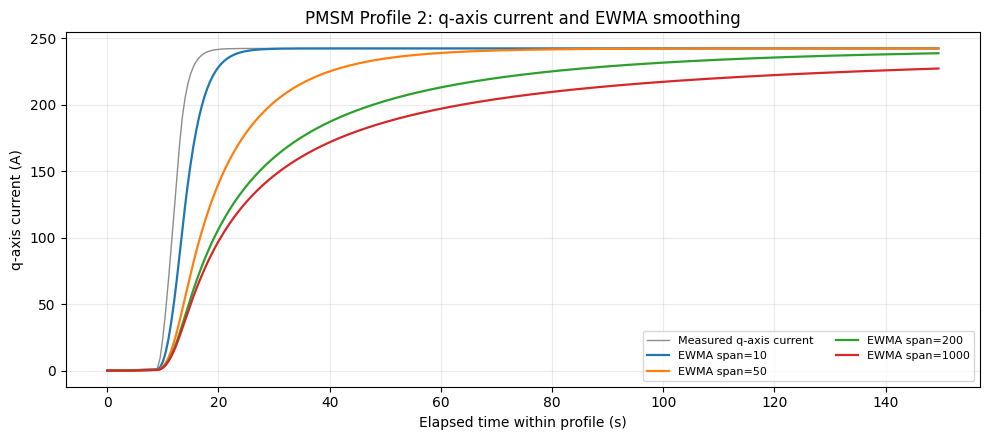

In [12]:
import matplotlib.pyplot as plt

pid = demo_ids[0]
mask = demo_df['profile_id'].eq(pid)
time_s = np.arange(int(mask.sum())) / FS_HZ

fig,ax=plt.subplots(figsize=(10,4.5))
ax.plot(time_s, X_temporal_demo.loc[mask,'i_q'].to_numpy(),
        label='Measured q-axis current', color='0.55', linewidth=1)
for s in DEMO_SPANS:
    ax.plot(time_s, X_temporal_demo.loc[mask,f'i_q_ewma_s{s}'].to_numpy(),
            label=f'EWMA span={s}', linewidth=1.6)
ax.set(xlabel='Elapsed time within profile (s)', ylabel='q-axis current (A)',
       title=f'PMSM Profile {pid}: q-axis current and EWMA smoothing')
ax.grid(alpha=.25)
ax.legend(ncol=2, fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/'ewma_real_profile.png', dpi=160)
plt.show()


## 2G · Export documentation evidence (not a cache)
Save a small **audit summary** and feature schema. These files are created from scratch every run and are not used as prerequisites. In Stage 3 the same feature functions will be called inside the model-training procedure with candidate smoothing spans; train-fitted standardization must be performed using *only the training profiles of each cross-validation fold*.


In [13]:
feature_audit = {
    'original_notebook_cells': '19–28',
    'source_paper': 'Kirchgässner et al. (2021), Table I and Sec. III-A',
    'development_demo_profiles': list(map(int,demo_ids)),
    'demo_rows': int(len(demo_df)),
    'source_sensor_count': 7,
    'derived_feature_count': 5,
    'illustrative_spans_samples': list(DEMO_SPANS),
    'sampling_hz': FS_HZ,
    'feature_count': int(X_temporal_demo.shape[1]),
    'feature_names': list(X_temporal_demo.columns),
    'ewma_convention': 'pandas ewm(span=s, adjust=True).mean()',
    'ewms_convention': 'pandas ewm(span=s, adjust=True).std(bias=True)',
    'model_training_performed': False,
    'final_test_evaluation_performed': False,
}
(OUTPUT_DIR/'stage2_feature_audit.json').write_text(json.dumps(feature_audit,indent=2))
pd.DataFrame({'feature_name':list(X_temporal_demo.columns)}).to_csv(
    OUTPUT_DIR/'stage2_feature_schema.csv',index=False
)
print('Generated: stage2_feature_audit.json, stage2_feature_schema.csv, ewma_real_profile.png')
print('No existing intermediate files were read. Final held-out profiles were not used.')


Generated: stage2_feature_audit.json, stage2_feature_schema.csv, ewma_real_profile.png
No existing intermediate files were read. Final held-out profiles were not used.


## Stage 2 conclusions and report notes

**What we demonstrated:** Seven original electrical/thermal/speed measurements were converted into twelve current-state predictors. For four illustrative spans, EWMA and EWMS added 96 causal, profile-specific history descriptors, producing a verified **600 × 108** demonstration matrix. Independent tests established agreement with the chosen weighted formulas, correct profile reset, correct feature dimensions, finite values, and no look-ahead on the tested sequences.

**What we have *not* established:** that four illustrative spans are optimal, that the 108 columns improve prediction, that the model generalizes to a new motor, or that the smoothing is sufficiently accurate for onboard thermal monitoring. These are empirical questions for cross-validation and later evaluation.

**Important experimental distinction:** Kirchgässner et al. optimise model-specific smoothing spans and train their regression models after standardizing using training data. Stage 3 must treat smoothing spans as model-selection parameters and fit any train-dependent scaler separately inside each cross-validation fold.

**Quick oral-check questions:**
1. What information does EWMA add that is missing from the instantaneous value?
2. How does EWMS differ from EWMA, and why could it help?
3. Why should smoothing restart at each `profile_id` boundary?
4. Why is `std(bias=True)` not identical to the printed right-hand side of Equation (4)?
5. Why should we not declare the 108-feature matrix better before testing a model?

**Next: Stage 3** — grouped three-fold cross-validation, train-only scaling, and fair regression-model comparison. Do not evaluate the locked final test profiles yet.


---
# Stage 3 · Grouped cross-validation, six-model smoke test, and OLS error diagnosis

**Reconstructs original 131-cell notebook Cells 29–45**. The stages above download raw data, check its integrity, reproduce the locked development/test split, and define feature-engineering functions.

This stage deliberately **does not** perform model optimisation or use the 14 held-out test profiles. It checks that fixed CV assignments and training pipelines function and studies a surprising OLS error. Small-sample results are **provisional** and should not be reported as final benchmark accuracy.

**Research trail:**

- Original Cells 29–34: stratified grouped three-fold CV from the 55 development profiles
- Cells 35–38: six regression pipelines on an 80-sample-per-profile demonstration set
- Cells 39–44: investigate an extreme OLS validation prediction
- Cell 45: interpret the results and prepare for Bayesian optimisation


## 3A · Why cross-validation must be grouped

Stage 1 reserved **14 complete profiles** for the final test. Here we further divide the remaining **55 complete development profiles** into three folds for model development. Each iteration trains on two folds and validates on the third; no recording session appears on both sides of the same iteration.

We stratify the *profiles*, not the individual 2 Hz observations, by tertiles of their **maximum measured magnet temperature**. The grouping helps balance lower- and higher-temperature sessions. It does not force equal observation counts because recording sessions differ in duration.

For a given model configuration, the later model-selection objective is

$$\mathrm{CV\,MSE}=\frac{1}{3}\sum_{k=1}^3\frac{1}{n_k}\sum_{i\in V_k}(y_i-\hat{y}_i)^2.$$

Each fold receives equal weight in this formula, **even when fold sizes differ**. These fold assignments will remain fixed for the forthcoming Bayesian optimisation. The final held-out set is not used for choosing models or hyperparameters.


In [14]:
from sklearn.model_selection import StratifiedKFold

# Rebuild fold assignments from Stage 1's *development* profiles only.
# The original notebook used random_state=42 on this sorted profile table.
profile_cv = (
    development_df.groupby('profile_id',sort=True)['pm']
    .agg(observations='size', pm_min='min', pm_max='max')
    .reset_index().sort_values('profile_id').reset_index(drop=True)
)
profile_cv['temperature_group'] = pd.qcut(
    profile_cv['pm_max'], q=3, labels=['Low','Medium','High']
)
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
profile_cv['cv_fold'] = -1
for fold_num, (_, val_idx) in enumerate(
    skf.split(profile_cv[['pm_max']], profile_cv['temperature_group']),start=1
):
    profile_cv.loc[val_idx,'cv_fold'] = fold_num

assert len(profile_cv)==55
assert profile_cv['cv_fold'].isin([1,2,3]).all()
assert set(profile_cv.profile_id).isdisjoint(test_ids)
assert profile_cv['profile_id'].is_unique

fold_train_val = {}
for fold_num in (1,2,3):
    val_ids = set(profile_cv.loc[profile_cv.cv_fold.eq(fold_num),'profile_id'].astype(int))
    train_ids = set(development_ids)-val_ids
    assert train_ids.isdisjoint(val_ids)
    assert val_ids.isdisjoint(test_ids)
    assert train_ids|val_ids==set(development_ids)
    fold_train_val[fold_num] = (sorted(train_ids),sorted(val_ids))

fold_summary = profile_cv.groupby('cv_fold',observed=True).agg(
    profiles=('profile_id','size'),observations=('observations','sum'),
    low_pm=('pm_min','min'),high_pm=('pm_max','max')
)
fold_summary['hours'] = fold_summary.observations / (FS_HZ*3600)
assert fold_summary.observations.sum() == len(development_df)
print('Temperature strata by fold:')
display(pd.crosstab(profile_cv.cv_fold,profile_cv.temperature_group))
print('Fold observation counts:')
display(fold_summary)
print('PASS: 55 development profiles assigned once each; final test remains excluded.')


Temperature strata by fold:
Fold observation counts:
PASS: 55 development profiles assigned once each; final test remains excluded.


temperature_group,Low,Medium,High
cv_fold,,,
1,7,6,6
2,6,5,7
3,6,6,6


,profiles,observations,low_pm,high_pm,hours
cv_fold,,,,,
1,19,401114,21.213623,109.333847,55.710278
2,18,362087,20.856956,105.948723,50.289861
3,18,291997,22.888792,99.396629,40.555139


### Interpret the fold summary

The original saved experiment gave **19/18/18 validation profiles**, with **401,114 / 362,087 / 291,997 observations** respectively. The difference in row counts is not an error: entire profiles must be kept together.

**Verification objective:** Can we reproduce the same exact split and confirm zero overlap? No prediction has been made yet.


## 3B · Build a small, physically consistent model-training demonstration

We select **80 evenly spaced observations from each of the 55 development profiles**, for a total of **4,400** rows. To avoid destroying the temporal meaning of EWMA/EWMS, we first generate features from **every original 2 Hz observation in each profile**, *then* select the demonstration positions.

**Important:** the 80 selected rows are not adjacent in time; their spacing differs with profile length. We retain `raw_position` and `elapsed_seconds` to diagnose where each selected observation really occurred. This sample is for **pipeline verification**, not the complete model benchmark.

The feature matrix has 12 original/derived predictors plus EWMA and EWMS at each of four *illustrative* spans `[10,50,200,1000]`, giving **108 features**. Final spans are chosen later by CV optimisation.


In [15]:
SMOKE_SPANS=(10,50,200,1000)
SAMPLES_PER_PROFILE=80

def make_pipeline_test_data(data, spans=SMOKE_SPANS, samples_per_profile=80):
    """Create a profile-balanced modelling sample without damaging 2 Hz feature history.

    The full sequential profile is transformed first; only then are a fixed
    number of time positions selected. Includes audit-only raw position/time.
    """
    parts=[]
    for pid, profile in data.groupby('profile_id',sort=False):
        X_raw=make_paper_inputs(profile)
        X_all=make_temporal_features(X_raw,profile['profile_id'],spans)
        count=min(samples_per_profile,len(profile))
        positions=np.linspace(0,len(profile)-1,count,dtype=int)
        sampled=X_all.iloc[positions].copy()
        sampled['pm_target']=profile['pm'].iloc[positions].to_numpy()
        sampled['profile_id']=int(pid)
        sampled['raw_position']=positions
        sampled['elapsed_seconds']=positions/FS_HZ
        parts.append(sampled)
    return pd.concat(parts,ignore_index=True)

smoke_df=make_pipeline_test_data(development_df,SMOKE_SPANS,SAMPLES_PER_PROFILE)
feature_cols=[c for c in smoke_df.columns if c not in
              ('pm_target','profile_id','raw_position','elapsed_seconds')]
assert len(smoke_df)==4_400 and smoke_df.profile_id.nunique()==55
assert len(feature_cols)==108
assert 'pm' not in feature_cols and 'profile_id' not in feature_cols
assert smoke_df[feature_cols].notna().all().all()
assert np.isfinite(smoke_df[feature_cols].to_numpy()).all()
assert (smoke_df.groupby('profile_id').raw_position.first()==0).all()
print('PASS:',len(smoke_df),'rows ×',len(feature_cols),'predictors across',
      smoke_df.profile_id.nunique(),'profiles')


PASS: 4400 rows × 108 predictors across 55 profiles


## 3C · Preliminary regression smoke test on **Fold 1 only**

Six model families are tested to confirm that the engineered features can be accepted by their training interfaces:

- **OLS:** ordinary least squares, linear regression
- **SVR:** nonlinear kernel regression, here RBF, `C=1`, `epsilon=0.1`
- **k-NN:** predicts using nearby examples in scaled feature space
- **Random Forest / Extra Trees:** ensembles of regression trees
- **MLP:** one-hidden-layer feed-forward neural network

A `Pipeline(StandardScaler(), model)` fits the scaling transformation **only on the current training fold**, then applies the same transformation to validation features. For tree ensembles this scaling is not necessary, but we retain it here to closely reconstruct the original experiment.

All six use *provisional parameters*, not tuned settings. Training and inference times will vary by hardware and library version. The MLP may report a convergence warning because the 150-iteration budget is intentionally small.


In [16]:
import time
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

train_profile_ids,val_profile_ids=fold_train_val[1]
train_sample=smoke_df.loc[smoke_df.profile_id.isin(train_profile_ids)].copy()
val_sample=smoke_df.loc[smoke_df.profile_id.isin(val_profile_ids)].copy()
assert set(train_sample.profile_id).isdisjoint(val_sample.profile_id)
assert len(train_sample)==36*80 and len(val_sample)==19*80

X_train=train_sample[feature_cols]
y_train=train_sample['pm_target']
X_val=val_sample[feature_cols]
y_val=val_sample['pm_target']

models={
    'OLS': LinearRegression(),
    'SVR': SVR(kernel='rbf',C=1.0,epsilon=0.1),
    'k-NN': KNeighborsRegressor(n_neighbors=10,weights='distance'),
    'Random Forest': RandomForestRegressor(n_estimators=20,max_depth=12,
                                          random_state=42,n_jobs=2),
    'Extra Trees': ExtraTreesRegressor(n_estimators=20,max_depth=12,
                                       random_state=42,n_jobs=2),
    'MLP': MLPRegressor(hidden_layer_sizes=(32,),max_iter=150,random_state=42)
}

results=[]
ols_pipeline=None
ols_predictions=None
for name, estimator in models.items():
    pipeline=Pipeline([('scaler',StandardScaler()),('model',estimator)])
    t0=time.perf_counter();pipeline.fit(X_train,y_train)
    fit_time=time.perf_counter()-t0
    t0=time.perf_counter();pred=pipeline.predict(X_val)
    predict_time=time.perf_counter()-t0
    errors=y_val.to_numpy()-pred
    results.append({
        'Model':name,
        'MSE (C^2)':mean_squared_error(y_val,pred),
        'RMSE (C)':np.sqrt(mean_squared_error(y_val,pred)),
        'MAE (C)':mean_absolute_error(y_val,pred),
        'R2':r2_score(y_val,pred),
        'Max absolute error (C)':np.abs(errors).max(),
        'Training time (s)':fit_time,
        'Inference time (s)':predict_time
    })
    if name=='OLS':
        ols_pipeline=pipeline
        ols_predictions=pred.copy()
    print('PASS:',name)

results_df=pd.DataFrame(results)
assert len(results_df)==6
assert np.isfinite(results_df.select_dtypes('number').to_numpy()).all()
print('Fold 1 only; exploratory pipeline smoke test (NOT final benchmark):')
display(results_df.round(4))


PASS: OLS
PASS: SVR
PASS: k-NN
PASS: Random Forest
PASS: Extra Trees
PASS: MLP
Fold 1 only; exploratory pipeline smoke test (NOT final benchmark):


/workspace/scratch/0a8876c2681b/work_env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(


,Model,MSE (C^2),RMSE (C),MAE (C),R2,Max absolute error (C),Training time (s),Inference time (s)
0,OLS,88.6563,9.4157,6.3003,0.7667,213.7320,0.0122,0.0016
1,SVR,84.9066,9.2145,6.7282,0.7766,41.8656,0.4126,0.3484
2,k-NN,87.2593,9.3413,7.0180,0.7704,45.0894,0.0038,0.0382
3,Random Forest,94.2754,9.7096,7.5968,0.7520,42.8915,1.7382,0.0134
4,Extra Trees,57.5839,7.5884,5.7671,0.8485,35.3301,0.3001,0.0138
5,MLP,86.6788,9.3101,7.1344,0.7719,50.7575,0.5077,0.0021


### What do the metrics mean?

For measured temperature $y_i$ and prediction $\hat y_i$:

$$\mathrm{MSE}=\frac{1}{n}\sum_i (y_i-\hat y_i)^2, \qquad \mathrm{RMSE}=\sqrt{\mathrm{MSE}}$$
$$\mathrm{MAE}=\frac{1}{n}\sum_i|y_i-\hat y_i|, \qquad \mathrm{MaxAE}=\max_i |y_i-\hat y_i|.$$

- **MSE** penalises large errors quadratically; the units are °C².
- **RMSE** expresses that penalty back in °C.
- **MAE** gives an average error magnitude in °C, less dominated by a single extreme point.
- **Maximum absolute error** reveals whether an otherwise good model makes a dangerously bad prediction.
- **R²** describes improvement relative to predicting the validation mean; it can be negative.

The original saved Fold 1 pilot results were approximately: **OLS MSE 88.66**, **SVR 84.91**, **k-NN 87.26**, **Random Forest 94.28**, **Extra Trees 57.58**, and **MLP 86.68 °C²**. Small differences across software versions are not necessarily evidence of a methodological change. Crucially, this is one fold with untuned settings, so it is **not** a six-algorithm ranking for the final report.


## 3D · Investigate the surprising OLS prediction, without removing data

The original pilot produced an OLS prediction of approximately **239.77 °C** for one observation whose measured magnet temperature was approximately **26.04 °C** (recording **profile 65**). That is an absolute error of about **213.73 °C**.

Before changing the algorithm, investigate:

1. Which measured point had the greatest error?
2. Was it near the *real* beginning of a profile?
3. How much of total MSE was caused by just that one prediction?
4. Do the first observations of other profiles show the same behaviour?

**Subtle correction to the original notebook:** Original Cell 42 used `groupby(...).cumcount()` on *already subsampled* observations. That counts the position **within the 80-point sample**, not the true position within the original 2 Hz recording. In this rebuilt workflow, `raw_position` and `elapsed_seconds` preserve the true position/time from the original profile. In particular, `raw_position=0` is an actual profile-start measurement; the next selected sample may be many seconds later.


In [17]:
ols_diagnostics=val_sample[['profile_id','pm_target','raw_position',
                                'elapsed_seconds']].copy().reset_index(drop=True)
ols_diagnostics=ols_diagnostics.rename(columns={'pm_target':'actual_pm'})
ols_diagnostics['predicted_pm']=ols_predictions
ols_diagnostics['absolute_error']=(
    ols_diagnostics['actual_pm']-ols_diagnostics['predicted_pm']).abs()
ols_diagnostics['squared_error']=ols_diagnostics['absolute_error']**2

print('Largest OLS prediction errors:')
display(ols_diagnostics.nlargest(10,'absolute_error'))
worst=ols_diagnostics.loc[ols_diagnostics['squared_error'].idxmax()]
print('Worst prediction in profile',int(worst.profile_id),
      'at original sample',int(worst.raw_position),
      'elapsed time',round(float(worst.elapsed_seconds),2),'s')

first=ols_diagnostics.loc[ols_diagnostics.raw_position.eq(0)]
later=ols_diagnostics.loc[ols_diagnostics.raw_position.gt(0)]
assert len(first)==len(val_profile_ids)==19
print('Mean absolute error at actual first recorded samples:',
      first.absolute_error.mean())
print('Mean absolute error at later *selected* samples:',
      later.absolute_error.mean())

print('Profile 65 first five *selected* examples (not adjacent 0.5-s samples):')
display(ols_diagnostics.loc[ols_diagnostics.profile_id.eq(65)].head(5))


Largest OLS prediction errors:
Worst prediction in profile 65 at original sample 0 elapsed time 0.0 s
Mean absolute error at actual first recorded samples: 18.515433952689584
Mean absolute error at later *selected* samples: 6.14567749400461
Profile 65 first five *selected* examples (not adjacent 0.5-s samples):


,profile_id,actual_pm,raw_position,elapsed_seconds,predicted_pm,absolute_error,squared_error
1280,65,26.037928,0,0.0,239.769930,213.732002,45681.368552
1201,72,41.780465,193,96.5,79.972030,38.191565,1458.595641
641,15,31.670839,229,114.5,63.268627,31.597788,998.420185
642,15,41.445896,458,229.0,67.217468,25.771572,664.173933
474,27,75.651138,33122,16561.0,50.344875,25.306263,640.406969
473,27,82.210464,32674,16337.0,57.981359,24.229105,587.049537
1122,69,29.539304,388,194.0,53.191581,23.652277,559.430205
475,27,70.167656,33569,16784.5,46.599690,23.567966,555.449009
869,75,68.704834,11765,5882.5,46.433088,22.271746,496.030664
1121,69,27.300511,194,97.0,49.327319,22.026808,485.180262


,profile_id,actual_pm,raw_position,elapsed_seconds,predicted_pm,absolute_error,squared_error
1280,65,26.037928,0,0.0,239.769930,213.732002,45681.368552
1281,65,35.643693,507,253.5,49.005254,13.361560,178.531289
1282,65,40.722855,1015,507.5,47.186275,6.463419,41.775790
1283,65,53.522017,1522,761.0,62.603549,9.081532,82.474221
1284,65,61.693861,2030,1015.0,67.202789,5.508929,30.348296


## 3E · Quantify why a single extreme error matters

Squared-error metrics give disproportionate weight to rare large errors. To diagnose the sensitivity, compute the portion of total squared error attributable to the single worst prediction:

$$\mathrm{Influence\ percentage}=\frac{(y_j-\hat y_j)^2}{\sum_i(y_i-\hat y_i)^2}\times100\%$$

Compute the MSE again *without that one error* only as a **sensitivity diagnostic**. **Do not remove this valid observation from the official evaluation or subsequent development set** unless there is independent evidence that it is invalid.


In [18]:
err2=ols_diagnostics.squared_error
worst_idx=err2.idxmax()
influence_pct=100*err2.loc[worst_idx]/err2.sum()
full_mse=err2.mean()
illustrative_mse_wo_one=err2.drop(worst_idx).mean()

print('Largest-error share of squared-error sum:',round(influence_pct,2),'%')
print('Observed validation MSE, all 1520 points:',round(full_mse,4),'C^2')
print('Diagnostic-only MSE excluding largest error:',
      round(illustrative_mse_wo_one,4),'C^2')

if int(worst.profile_id)==65:
    print('Raw first five measured rows of profile 65:')
    display(development_df.loc[development_df.profile_id.eq(65)].head(5))

# Preservation and numerical check: original data remains untouched.
assert len(ols_diagnostics)==len(val_sample)==1520
assert np.isclose(full_mse,results_df.loc[results_df.Model.eq('OLS'),'MSE (C^2)'].iloc[0])
print('PASS: anomaly investigated with full data retained.')


Largest-error share of squared-error sum: 33.9 %
Observed validation MSE, all 1520 points: 88.6563 C^2
Diagnostic-only MSE excluding largest error: 58.6413 C^2
Raw first five measured rows of profile 65:
PASS: anomaly investigated with full data retained.


,u_q,coolant,stator_winding,u_d,stator_tooth,motor_speed,i_d,i_q,pm,stator_yoke,ambient,torque,profile_id
1042494,-0.060301,24.572270,25.328268,-0.044640,24.759084,3028.577653,-16.682717,-22.554878,26.037928,23.902619,25.156664,-5.036988,65
1042495,-0.098472,24.549411,25.332084,-0.087538,24.771273,3277.195135,-32.674103,-36.837572,26.171841,23.906777,25.158406,7.594919,65
1042496,-0.134579,24.529792,25.289755,-0.137843,24.780007,3526.252702,-51.436325,-50.341317,25.995341,23.909756,25.159215,19.732400,65
1042497,-0.163837,24.506268,25.284230,-0.188305,24.786265,3775.622429,-70.247635,-61.302441,25.900132,23.910191,25.157646,27.199507,65
1042498,-0.185884,24.494794,25.343128,-0.235406,24.790749,4025.182345,-87.820645,-69.577852,25.862153,23.911742,25.156261,30.220038,65


## 3F · Save reproducible evidence and explicitly stop before optimisation

These generated CSV/JSON files document what happened; the next execution of **Run all** regenerates them from the original raw dataset. They are *not* input dependencies for Stage 3.


In [19]:
profile_cv.to_csv(OUTPUT_DIR/'profile_cv_assignments.csv',index=False)
results_df.to_csv(OUTPUT_DIR/'stage3_fold1_smoke_models.csv',index=False)
ols_diagnostics.to_csv(OUTPUT_DIR/'stage3_ols_validation_diagnostics.csv',index=False)

stage3_audit={
 'source_notebook_cells':'29-45',
 'fixed_seed':42,
 'development_profiles':int(len(profile_cv)),
 'heldout_test_profiles_unused':len(test_ids),
 'folds':{str(k):{'train_profiles':len(v[0]),'validation_profiles':len(v[1])}
          for k,v in fold_train_val.items()},
 'smoke_spans':list(SMOKE_SPANS),
 'smoke_total_observations':int(len(smoke_df)),
 'smoke_sample_per_profile':SAMPLES_PER_PROFILE,
 'predictor_count':len(feature_cols),
 'fold1_validation_observations':len(val_sample),
 'results_are_final_benchmark':False,
 'worst_ols_profile':int(worst.profile_id),
 'worst_ols_raw_position':int(worst.raw_position),
 'worst_ols_absolute_error_C':float(worst.absolute_error),
 'worst_ols_error_contribution_percent':float(influence_pct),
 'final_test_evaluated':False,
 'bayesian_optimisation_performed':False,
}
(OUTPUT_DIR/'stage3_audit.json').write_text(json.dumps(stage3_audit,indent=2))
print('Generated: profile_cv_assignments.csv, stage3_fold1_smoke_models.csv,')
print('stage3_ols_validation_diagnostics.csv, stage3_audit.json')


Generated: profile_cv_assignments.csv, stage3_fold1_smoke_models.csv,
stage3_ols_validation_diagnostics.csv, stage3_audit.json


## Stage 3 conclusions and report notes

**What the original and rebuilt Stage 3 verify:**

- The profile-grouped, temperature-stratified three-fold scheme excludes the held-out final test set.
- A small *fixed-span, one-fold* pilot confirms that six regression implementations can consume the 108 engineered features.
- An extreme prediction from one linear model is diagnosed, not silently discarded.
- The pilot illustrates why it is insufficient to report only average MSE: inspect MAE, maximum deviation and individual failure modes.

**What this stage does NOT establish:** a best algorithm, optimised spans, representative full-development accuracy, or generalisation error on the 14 unseen final-test profiles. Those belong to later stages.

**Possible report paragraph (adapt to your actual rerun and cite source code/results):**

> To establish a leakage-resistant training and validation strategy, the 55 development sessions were partitioned into three temperature-stratified folds at the profile level. Preliminary implementations of six regressors were checked with 4,400 sampled observations whose temporal features were calculated from complete 2 Hz histories. A pronounced OLS prediction error in profile 65 motivated an error-influence study. The affected observation was retained because the evidence did not establish a sensor fault. These results motivated more systematic optimisation and robustness evaluation rather than premature model selection.

**Self-check before Stage 4:** (i) Why stratify by *profile* rather than row? (ii) Why standardize using the fold's training observations only? (iii) Why generate temporal features before sampling? (iv) Why is 57.58 °C² for Extra Trees *not* a final performance claim? (v) Why might MSE and MAE tell different stories for OLS?

**Next:** Stage 4 (original Cells 46–67), Bayesian optimisation of EWMA/EWMS spans and model hyperparameters using these fixed folds. No final-test data should influence that process.



## RQ2 — Baseline accuracy, optimisation and computational cost

The baseline purpose is to compare credible regression families on the same engineering target rather than infer that complexity alone improves accuracy. For feature row \(x_i\in\mathbb R^{108}\), OLS predicts \(\hat y_i=b+x_i^T\beta\). It minimises \(\sum_i(y_i-b-x_i^T\beta)^2\), uses 109 fitted unknowns including the intercept, and is inexpensive at inference. Linear coefficients remain associations between correlated thermal-memory predictors, not causal motor parameters.

Nearest-neighbour regression predicts a distance-weighted average of 54 nearby training vectors in the frozen final configuration. It retains the training observations, so a small fit time can coexist with costly inference and large persistent storage. Scaling is necessary for meaningful distances between mixed-unit predictors. Random Forest averages bootstrap-trained, feature-randomised trees; Extra Trees adds random split thresholds (Breiman, 2001; Geurts et al., 2006). Both retain this project's `max_features='sqrt'` and selected bootstrap setting. Their finite partition representation can be fast to evaluate, but does not justify extrapolation outside observed operating conditions.

The final MLP has one hidden layer of four ReLU units and a scalar linear output, trained with Adam. Backpropagation supplies the gradient through the differentiable network (Rumelhart et al., 1986; Kingma and Ba, 2015). It can represent nonlinear relationships using far fewer retained observations than k-NN, but is stochastic and sensitive to conditioning and stopping. The supplied development factory (`max_iter=200`, no early stopping), Stage 3 smoke MLP (`max_iter=150`), and final MLP (`max_iter=400`, 10% row-based early stopping, patience 15) are distinct experiments. Their settings are retained and their results must not be treated as identical optimisation protocols.

### The executable Bayesian investigation and the missing provenance

The supplied executable search is an **eight-evaluation OLS pilot** over integer spans \([5,30],[31,150],[151,700],[701,3000]\). `gp_minimize` uses four initial random points, expected improvement (`acq_func='EI'`) and seed 42. Each candidate rebuilds full-history features, selects the same 80 evenly spaced observations per development profile (4,400 rows), fits train-only input scaling and OLS in each of three fixed grouped folds, and returns their *unweighted mean MSE*. The objective is in °C². No target scaler is used for this OLS pilot. The Gaussian-process surrogate balances exploring uncertain candidates with exploiting likely improvements (Snoek et al., 2012; scikit-optimize developers, 2024). Neither a Gaussian-process surrogate nor a finite trial budget guarantees a global optimum.

The uploaded saved pilot's best spans are (30,150,652,3000), mean CV MSE 45.64670386344714 °C², compared with 64.639936 °C² for spans (10,50,200,1000). These are historical source outputs; a new execution is reported separately. A boundary winner suggests restricted search coverage, not a mathematical proof that larger bounds will improve generalisation. The supplied code also defines an expanded cumulative-gap encoding with bounds [5,100], [1,400], [1,1500], [1,6000] and model-specific search spaces. Encoding verification and defining an objective do not constitute executing a search.

**Critical limit:** Stages 1–8 explicitly state that the historical long Bayesian searches, 12-trial five-model searches and later refinement were omitted from this upload. Their complete trial traces, objective implementations at their original budgets and acquisition settings are not recoverable from the provided files. The final five baseline configurations are therefore retained as *historical frozen inputs*, not outputs of the eight-trial OLS pilot. In particular final OLS spans (67,97,693,3339) cannot be obtained from that pilot's bounds. The exact historical RQ2 optimisation-to-selection chain remains incomplete. No synthetic reconstruction or substitute search is supplied under the original experiment's name.

### Interpreting costs

OLS's final `fit_seconds` includes feature construction, profile QR, moment aggregation and the solve. Other final model fit timers start after their feature matrices are built. Stage 9 screening timers exclude already completed standardisation; Nyström fit/predict timers include their mapping. The final inference timer begins **after joblib loading**, and includes the model-file checksum, feature construction, prediction and checkpoint I/O. The source Markdown's claim that it includes deserialisation is inaccurate. These are retained timer boundaries; compare them with this caveat instead of claiming a hardware-independent speedup. Runtime repetitions in Stage 5 equal one; between-fold variation is not repeat timing uncertainty.


---
# Stage 4 — Confirm the three-fold OLS objective and run the eight-candidate Bayesian pilot

Use 4,400 development observations for each candidate, with 108 features, the same three grouped validation folds, and the same row selections. This verifies the optimisation mechanism **without repeating the archived 28-trial OLS and five-model searches**. Those historical searches remain in the original notebook.

**Provenance qualification:** references here to an earlier research archive describe historical work reported by the supplied notebook. That fuller archive/trial history is not attached; this package preserves the available evidence without certifying unavailable searches.


In [20]:
import json, time, warnings
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

N_OLS_PILOT_TRIALS = 8
OPTIMISATION_SEED = 42

STAGE4_DIR = OUTPUT_DIR / 'stage4'
STAGE4_DIR.mkdir(parents=True, exist_ok=True)

# The CV fold assignments were fixed during Stage 3.
fold_lookup = profile_cv.set_index('profile_id')['cv_fold']
assert len(fold_lookup) == 55 and set(fold_lookup.unique()) == {1, 2, 3}
assert set(fold_lookup.index).isdisjoint(set(test_ids))


def build_candidate_features(spans):
    """Build 108 causal features from raw development profiles.

    EWMAs/EWMSs use *all* preceding 2 Hz readings in each profile.
    Only after that do we retain 80 evenly spaced observations/profile.
    Different trial spans keep the identical row positions and CV folds.
    """
    spans = tuple(int(s) for s in spans)
    if len(spans) != 4 or not all(a < b for a,b in zip(spans,spans[1:])):
        raise ValueError('Exactly four distinct increasing spans required')
    feature_blocks, target_blocks, id_blocks = [], [], []
    for pid, profile in development_df.groupby('profile_id',sort=False):
        raw = make_paper_inputs(profile)
        temporal = make_temporal_features(raw,profile['profile_id'],spans)
        loc = np.linspace(0,len(profile)-1,SAMPLES_PER_PROFILE,dtype=int)
        feature_blocks.append(temporal.iloc[loc].to_numpy(dtype=np.float64))
        target_blocks.append(profile['pm'].iloc[loc].to_numpy(dtype=np.float64))
        id_blocks.append(np.full(len(loc),int(pid),dtype=int))
    X = np.vstack(feature_blocks)
    y = np.concatenate(target_blocks)
    ids = np.concatenate(id_blocks)
    assert X.shape == (4400,108) and y.shape == (4400,) and len(ids) == 4400
    assert np.isfinite(X).all() and np.isfinite(y).all()
    assert not np.isin(ids,test_ids).any()
    return X,y,ids


def evaluate_ols_cv(spans):
    """Calculate reproducible, 3-fold grouped validation errors for OLS."""
    X,y,ids = build_candidate_features(spans)
    folds = pd.Series(ids).map(fold_lookup).to_numpy(dtype=int)
    errors = []
    for fold in (1,2,3):
        tr,va = folds != fold,folds == fold
        assert set(ids[tr]).isdisjoint(set(ids[va]))
        pipeline = Pipeline([
            ('standardise_train_only',StandardScaler()),
            ('linear_regression',LinearRegression())
        ])
        pipeline.fit(X[tr],y[tr])
        prediction = pipeline.predict(X[va])
        errors.append(float(mean_squared_error(y[va],prediction)))
    return float(np.mean(errors)),errors

print('Stage 4 objective defined; final held-out profiles are untouched.')

Stage 4 objective defined; final held-out profiles are untouched.


## 4B · Numerically verify the unoptimised reference

The original pilot tested spans **(10, 50, 200, 1000)** using all three folds (not just the Fold 1 smoke test from Stage 3).

Original saved reference: Fold 1 = 88.6563; Fold 2 = 54.8137; Fold 3 = 50.4498; mean = **64.6399 °C²**. The assertion checks that our rebuild implements the same objective and partitions to the stated tolerance.

In [21]:
baseline_spans = (10,50,200,1000)
baseline_mse, baseline_folds = evaluate_ols_cv(baseline_spans)
for k,score in enumerate(baseline_folds,start=1):
    print(f'Fold {k} MSE = {score:.6f} °C²')
print(f'Baseline mean CV MSE = {baseline_mse:.6f} °C²')
np.testing.assert_allclose(baseline_mse,64.6399,rtol=0.001)
assert np.isclose(np.mean(baseline_folds),baseline_mse)
print('PASS: Baseline objective matches the original saved calculation')

Fold 1 MSE = 88.656261 °C²
Fold 2 MSE = 54.813706 °C²
Fold 3 MSE = 50.449841 °C²
Baseline mean CV MSE = 64.639936 °C²
PASS: Baseline objective matches the original saved calculation


### Eight-candidate Bayesian verification

`scikit-optimize` proposes four ordered spans, then the objective regenerates features and calculates the mean of three grouped-fold MSE values. This repeats only the original **pilot budget**. The best candidate may vary slightly with software versions.


In [22]:
from skopt import gp_minimize
from skopt.space import Integer, Real, Categorical


In [23]:
ols_search_space = [
    Integer(5,30,name='span_1'),
    Integer(31,150,name='span_2'),
    Integer(151,700,name='span_3'),
    Integer(701,3000,name='span_4')
]
ols_pilot_records=[]

def ols_pilot_objective(candidate):
    spans = tuple(map(int,candidate))
    start = time.perf_counter()
    avg,fold_scores = evaluate_ols_cv(spans)
    ols_pilot_records.append({
        'trial':len(ols_pilot_records)+1,
        **{f's{i}':v for i,v in enumerate(spans,start=1)},
        **{f'fold{i}_mse':float(v) for i,v in enumerate(fold_scores,start=1)},
        'mean_cv_mse':avg,
        'runtime_s':time.perf_counter()-start
    })
    print(f'OLS pilot {len(ols_pilot_records):2}/{N_OLS_PILOT_TRIALS}: '
          f'spans={spans}, CV MSE={avg:.4f} °C²',flush=True)
    return avg

ols_pilot_result = gp_minimize(
    ols_pilot_objective,
    dimensions=ols_search_space,
    n_calls=N_OLS_PILOT_TRIALS,
    n_initial_points=4,
    acq_func='EI',
    random_state=OPTIMISATION_SEED
)
ols_pilot_df=pd.DataFrame(ols_pilot_records)
ols_pilot_df.to_csv(STAGE4_DIR/'ols_eight_trial_pilot.csv',index=False)
assert len(ols_pilot_df)==8
assert np.isfinite(ols_pilot_df[['fold1_mse','fold2_mse','fold3_mse','mean_cv_mse']].to_numpy()).all()
np.testing.assert_allclose(ols_pilot_df[['fold1_mse','fold2_mse','fold3_mse']].mean(axis=1),
                           ols_pilot_df['mean_cv_mse'])
print('Best eight-trial OLS spans:',list(map(int,ols_pilot_result.x)))
print('Best eight-trial CV MSE:',float(ols_pilot_result.fun))
display(ols_pilot_df.sort_values('mean_cv_mse').head(8).round(4))

OLS pilot  1/8: spans=(25, 53, 579, 2073), CV MSE=48.3574 °C²
OLS pilot  2/8: spans=(16, 43, 403, 1468), CV MSE=53.7103 °C²
OLS pilot  3/8: spans=(9, 108, 182, 2361), CV MSE=48.6122 °C²
OLS pilot  4/8: spans=(28, 31, 696, 2121), CV MSE=47.8367 °C²
OLS pilot  5/8: spans=(30, 31, 700, 2347), CV MSE=47.1058 °C²
OLS pilot  6/8: spans=(30, 31, 700, 3000), CV MSE=45.9508 °C²
OLS pilot  7/8: spans=(30, 150, 652, 3000), CV MSE=45.6467 °C²
OLS pilot  8/8: spans=(5, 150, 700, 3000), CV MSE=45.7540 °C²
Best eight-trial OLS spans: [30, 150, 652, 3000]
Best eight-trial CV MSE: 45.64670386344712


,trial,s1,s2,s3,s4,fold1_mse,fold2_mse,fold3_mse,mean_cv_mse,runtime_s
6,7,30,150,652,3000,65.8372,37.5159,33.5870,45.6467,3.3980
7,8,5,150,700,3000,65.9788,36.9979,34.2855,45.7540,3.2907
5,6,30,31,700,3000,66.1333,37.6906,34.0287,45.9508,3.6816
4,5,30,31,700,2347,67.9360,38.8915,34.4900,47.1058,3.3988
3,4,28,31,696,2121,68.9513,39.5925,34.9663,47.8367,3.3816
0,1,25,53,579,2073,69.7459,40.1931,35.1333,48.3574,3.4556
2,3,9,108,182,2361,70.0873,40.4242,35.3250,48.6122,3.6289
1,2,16,43,403,1468,76.3572,44.9916,39.7820,53.7103,3.3420


## 4D · Inspect objective progress and search-boundary effects

The expected reduction in prediction error is **empirical**, not a guarantee of generalisation. Examine whether the best spans land against their search boundaries; if they do, that motivates investigating a wider parameter domain. The best-so-far curve is non-increasing, but the individual candidate errors may go up or down.

Relative MSE reduction from baseline: 29.38%


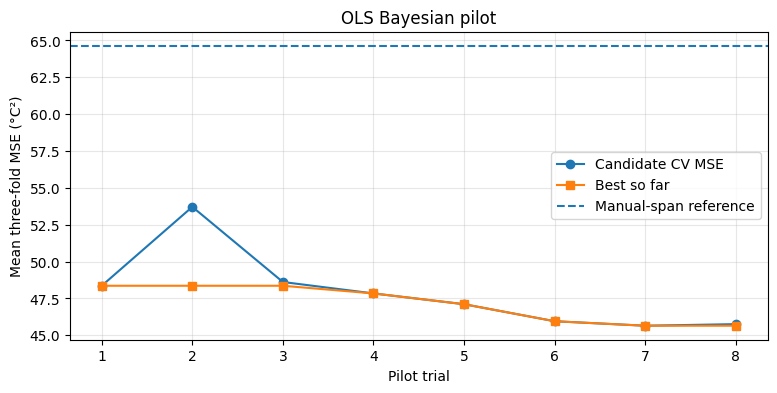

In [24]:
import matplotlib.pyplot as plt
history=ols_pilot_df.copy()
history['best_so_far']=history.mean_cv_mse.cummin()
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(history.trial,history.mean_cv_mse,'o-',label='Candidate CV MSE')
ax.plot(history.trial,history.best_so_far,'s-',label='Best so far')
ax.axhline(baseline_mse,ls='--',label='Manual-span reference')
ax.set(xlabel='Pilot trial',ylabel='Mean three-fold MSE (°C²)',title='OLS Bayesian pilot')
ax.grid(alpha=0.3);ax.legend();plt.show()
print(f'Relative MSE reduction from baseline: '
      f'{100*(baseline_mse-ols_pilot_df.mean_cv_mse.min())/baseline_mse:.2f}%')

### Verify that the expanded parameterisation can represent ordered spans

The archive subsequently searched a much larger range. Here we check the encoding and decoding only; we do **not** rerun its extra evaluations.


In [25]:
expanded_space = [
    Integer(5,100,name='s1'),
    Integer(1,400,name='gap_2'),
    Integer(1,1500,name='gap_3'),
    Integer(1,6000,name='gap_4')
]

def decode_spans(parameters):
    a,d2,d3,d4=map(int,parameters)
    return [a,a+d2,a+d2+d3,a+d2+d3+d4]

def encode_spans(spans):
    a,b,c,d=map(int,spans)
    if not (a<b<c<d):
        raise ValueError('Expected strictly increasing spans')
    return [a,b-a,c-b,d-c]

for example in [(10,50,200,1000),(30,150,652,3000),(89,265,622,3829)]:
    assert decode_spans(encode_spans(example)) == list(example)
for _,row in ols_pilot_df.iterrows():
    params=encode_spans([row[f's{i}'] for i in range(1,5)])
    assert all(dim.low <= val <= dim.high for dim,val in zip(expanded_space,params))
print('PASS: Ordered-span encoding is invertible and pilot trials fit enlarged space')

print('PASS: Expanded ordered-span parameterisation verified; no extended search performed.')


PASS: Ordered-span encoding is invertible and pilot trials fit enlarged space
PASS: Expanded ordered-span parameterisation verified; no extended search performed.


### Define alternative model implementations (not a new five-model search)

The regression factories are used in later checks. The historical 8- and 12-evaluation searches are documented in the original notebook, not replayed here.

**Provenance qualification:** references here to an earlier research archive describe historical work reported by the supplied notebook. That fuller archive/trial history is not attached; this package preserves the available evidence without certifying unavailable searches.


In [26]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor,ExtraTreesRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.exceptions import ConvergenceWarning

MODEL_SPACES = {
    'SVR': [Real(1e-3,10,prior='log-uniform',name='C'),
            Real(1e-2,0.3,prior='log-uniform',name='epsilon')],
    'k-NN': [Integer(1,512,name='n_neighbors'),
              Categorical(['uniform','distance'],name='weights')],
    'Random Forest': [Integer(20,100,name='n_estimators'),
                      Integer(5,30,name='max_depth'),
                      Integer(2,20,name='min_samples_split'),
                      Integer(1,10,name='min_samples_leaf'),
                      Categorical(['yes','no'],name='bootstrap')],
    'Extra Trees': [Integer(20,100,name='n_estimators'),
                    Integer(5,30,name='max_depth'),
                    Integer(2,20,name='min_samples_split'),
                    Integer(1,10,name='min_samples_leaf'),
                    Categorical(['yes','no'],name='bootstrap')],
    'MLP': [Integer(1,3,name='n_layers'),
            Integer(4,32,name='n_units'),
            Real(1e-7,1e-2,prior='log-uniform',name='alpha'),
            Real(1e-4,1e-2,prior='log-uniform',name='learning_rate_init')]
}

from pmsm_project.models import make_regressor


def evaluate_model_cv(model_name,candidate):
    spans=decode_spans(candidate[:4])
    hp={dim.name:(val.item() if isinstance(val,np.generic) else val)
        for dim,val in zip(MODEL_SPACES[model_name],candidate[4:])}
    X,y,ids=build_candidate_features(spans)
    folds=pd.Series(ids).map(fold_lookup).to_numpy(dtype=int)
    errors=[];convergence_warnings=0
    for k in (1,2,3):
        tr,va=folds!=k,folds==k
        assert set(ids[tr]).isdisjoint(set(ids[va]))
        pipe=TransformedTargetRegressor(
            regressor=Pipeline([('scaler',StandardScaler()),
                                ('model',make_regressor(model_name,hp))]),
            transformer=StandardScaler()
        )
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always',ConvergenceWarning)
            pipe.fit(X[tr],y[tr])
        convergence_warnings+=sum(
            issubclass(w.category,ConvergenceWarning) for w in caught)
        y_hat=pipe.predict(X[va])
        assert np.isfinite(y_hat).all()
        errors.append(float(mean_squared_error(y[va],y_hat)))
    return {'spans':spans,'hyperparameters':hp,
            'fold_scores':errors,'mean_cv_mse':float(np.mean(errors)),
            'convergence_warnings':convergence_warnings}

print('PASS: Five model-specific search spaces and CV objectives defined')

PASS: Five model-specific search spaces and CV objectives defined


**Stage 4 checkpoint:** The three-fold objective and eight-trial OLS pilot can be regenerated. Optimisation quality beyond that pilot remains supported by the **original saved research outputs**, not by the present Run All.

**Provenance qualification:** references here to an earlier research archive describe historical work reported by the supplied notebook. That fuller archive/trial history is not attached; this package preserves the available evidence without certifying unavailable searches.



## RQ3 — Exact SVR, matched-kernel approximations and linear feasibility

Support-vector regression minimises an epsilon-insensitive empirical loss with quadratic weight regularisation (Smola and Schölkopf, 2004):

\[
\min_{w,b}\frac12\lVert w\rVert_2^2+C\sum_{i=1}^N\max(0,|y_i-w^T\phi(x_i)-b|-\epsilon).
\]

Predictors and target are standardised on training rows only; predicted temperature is inverse-transformed to °C. Consequently epsilon is a dimensionless tolerance in standardised target units, whose Celsius equivalent depends on the training target standard deviation. C balances the weight penalty against summed sample losses. OLS pilot errors and all reported evaluation MSEs nevertheless remain in °C².

Exact RBF-SVR uses \(K(x,z)=\exp(-\gamma\|x-z\|^2)\). Stage 9 computes the `gamma='scale'` equivalent \(\gamma=1/(p\operatorname{Var}(X_{train,scaled}))\), with p=108, and supplies that identical gamma to exact SVR and Nyström. When all 108 columns have unit population variance and zero mean, gamma is about 1/108. Reusing a numeric gamma prevents a default-kernel-width difference from masquerading as an approximation effect.

Nyström selects m training basis observations, constructs \(W=K(B,B)\) and \(C_B=K(X,B)\), and uses approximately \(Z=C_B W^{\dagger/2}\), so \(ZZ^T\) approximates the full Gram matrix (Williams and Seeger, 2001; scikit-learn developers, 2025). Stage 9 checks relative Frobenius reconstruction error on a 192-row *training* probe at 24/64/128/192 components, then screens 128/256 components and separately investigates 512. Full-basis reconstruction on the same probe verifies implementation; it does not prove out-of-sample regression accuracy or monotonic improvement for every component count.

Direct LinearSVR applies the same epsilon-insensitive loss family directly in the 108 engineered dimensions, with no RBF mapping. It is not exact RBF-SVR solved faster. Even matched-kernel Nyström plus LinearSVR is not an identical finite-sample optimisation: LIBLINEAR regularises its synthetic intercept feature, unlike the standard LIBSVM intercept treatment, and solver termination differs. All retained intercept/solver defaults are documented rather than silently equalised (scikit-learn developers, 2025).

The experiment sequence is preserved: Stage 5 nested budgets 80/160 with fixed 640/profile validation, then Stage 9 640/profile common data; four-method Fold 1 screening; a 27-profile/9-profile inner grouped split for C sensitivity; Nyström-512 capacity; Fold 1 confirmation; three outer development folds with inner two-fold GroupKFold for direct-linear C; a five-value development C grid; doubling training to 1280/profile with validation fixed to the original 640; halving C; complete development reconstruction; and full-development LinearSVR fitting/persistence. Exact full-data RBF fitting stopped at a historical 1,800-second guard according to an embedded status table; that historical attempt is not executable from this upload.

The supplied Stage 9D results show exact RBF MSE 37.162851 °C², Nyström-128 57.334756, Nyström-256 55.429879, and direct linear 37.536246 with a convergence warning. Later sensitivity and grouped checks investigate that warning rather than certify the first linear fit. The reported exact three-fold MSEs (37.1629,28.6819,37.6394) and nested linear MSEs (41.8858,47.6117,45.1415) support a speed/accuracy compromise in that sampled setting, not dominance of the linear method. New execution comparisons are maintained in the reports.

For \(\tfrac12\|w\|^2+C\sum L_i\), dividing the objective by \(CN\) produces \(\tfrac{1}{2CN}\|w\|^2+\tfrac1N\sum L_i\). Keeping CN fixed approximately retains the regularisation coefficient against *mean* loss. The source therefore scales C by sample-count ratio. Stage 9K selects a converged candidate and Stage 9M uses

\[
C_{full}=C_{ref}\,\bar N_{fold}/N_{full}.
\]

Historically \(C_{ref}=0.02469342895102852\), \(\bar N_{fold}=46933.333333333336\), \(N_{full}=1055198\), giving \(C_{full}=0.0010983198718170478\). This is a **heuristic**, not a guarantee of equal optimum: sampled operating distributions, autocorrelation, and training-derived scalers change. The final notebook freezes this value before test predictions, and does not select it using test performance.


---
# Stage 5 — SVR sample-size verification

Build causal features from complete 2-Hz histories, choose nested development samples, and measure two manageable training budgets (80 and 160 rows per profile) across all three folds. The original 320/640 budgets and repeated timing experiments are **historical results**, not rerun in this verification notebook.


In [27]:
import os, json, heapq, time, platform
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

STAGE5_DIR = OUTPUT_DIR / 'stage5'
STAGE5_DIR.mkdir(parents=True, exist_ok=True)

STAGE5_SAMPLE_SIZES = (80, 160, 320, 640)  # Nested sample construction and audit
STAGE5_MAX_SAMPLES = max(STAGE5_SAMPLE_SIZES)
STAGE5_EVALUATED_SIZES = (80, 160)  # Fixed verification scope
STAGE5_REPEATS = 1  # One fit per grouped fold (6 fits in total)

# Original Stage 4 pilot's saved winner (fixed here, not silently loaded from Drive).
STAGE5_SPANS = (47, 301, 1799, 6668)
STAGE5_SVR_HP = {
    'C': 1.573090181238779,
    'epsilon': 0.18308574912799475,
    'gamma': 'scale',
    'kernel': 'rbf'
}
STAGE5_CONFIG_SOURCE = 'original Stage 4 eight-evaluation SVR pilot (fixed recorded winner)'

assert len(STAGE5_SPANS) == 4 and list(STAGE5_SPANS) == sorted(STAGE5_SPANS)
assert set(development_df.profile_id).isdisjoint(test_ids)
assert len(development_df) == 1_055_198 and development_df.profile_id.nunique() == 55
assert STAGE5_REPEATS in (1,3)

print('Frozen SVR spans:', STAGE5_SPANS)
print('Frozen SVR hyperparameters:', STAGE5_SVR_HP)
print('Stage 5 model-fit budgets:', STAGE5_EVALUATED_SIZES)
print('Stage 5 repetitions per size/fold:',STAGE5_REPEATS)
print('No final-test profiles used.')

Frozen SVR spans: (47, 301, 1799, 6668)
Frozen SVR hyperparameters: {'C': 1.573090181238779, 'epsilon': 0.18308574912799475, 'gamma': 'scale', 'kernel': 'rbf'}
Stage 5 model-fit budgets: (80, 160)
Stage 5 repetitions per size/fold: 1
No final-test profiles used.


## 5B · Why nested samples are a stronger experimental design

We want a sequence of training subsets $A_{80}\subset A_{160}\subset A_{320}\subset A_{640}$ **within each profile**. The original implementation begins with the first and last observation, then repeatedly bisects the *largest remaining interval*. Each refinement adds observations; it does not replace old observations.

At 2 Hz, an EWMA span of 6668 retains a long history. We therefore calculate temporal features from **each complete original profile** before selecting any rows. Selecting first and smoothing second would incorrectly treat widely separated observations as adjacent in time.

For any training fold with $p$ training profiles, the number of training rows is $p\times n$, where $n$ is 80, 160, 320 or 640. All validation folds use **the same 640 observations per validation profile at every training size**.

In [28]:
from pmsm_project.sampling import nested_sample_order

# Independent low-cost verification before transforming the 1.05M-row dataset.
example_order = nested_sample_order(2500, 640)
for n in STAGE5_SAMPLE_SIZES:
    assert len(set(example_order[:n])) == n
for low,high in zip(STAGE5_SAMPLE_SIZES[:-1],STAGE5_SAMPLE_SIZES[1:]):
    assert set(example_order[:low]).issubset(set(example_order[:high]))
assert example_order[:2] == [0, 2499]
print('PASS: Nesting and boundary tests on an independent 2,500-row example')

PASS: Nesting and boundary tests on an independent 2,500-row example


## 5C · Generate all 108 features from complete profile histories

For each of the 55 development profiles:

1. Convert the original sensors to twelve instantaneous engineering predictors.
2. Generate EWMA/EWMS using the **frozen** four spans, with profile history never crossing recording boundaries.
3. Select a maximum of 640 observations, preserving a `nest_rank` that indicates at which training budget each observation becomes available.
4. Reassemble one 35,200-row sampled development table, with 108 predictor columns and separate `pm_target`/`profile_id`/`nest_rank` metadata.

The large sampled matrix is *regenerated* and does not need to be stored in GitHub or Google Drive to run the experiment.

**Implementation improvement:** Stage 5 uses 12-column vectorised Pandas EWM calculations and checks them against the original Stage 2 definition. This avoids 96 separate per-column calls while preserving identical causal features.


In [29]:
from pmsm_project.features import vectorised_temporal_sample

# Confirm vectorised and original implementations agree on real data.
_check_profile = next(iter(development_df.groupby('profile_id',sort=False)))[1].iloc[:450]
_check_raw = make_paper_inputs(_check_profile)
_check_positions = np.array([0,1,2,6,42,123,449])
_check_orig = make_temporal_features(_check_raw, _check_profile['profile_id'], STAGE5_SPANS)
_check_fast = vectorised_temporal_sample(_check_raw, _check_positions, STAGE5_SPANS)
np.testing.assert_allclose(
    _check_fast[_check_orig.columns].to_numpy(),
    _check_orig.iloc[_check_positions].to_numpy(),
    rtol=1e-9, atol=1e-9
)
print('PASS: Vectorised filters agree with Stage 2 reference on original sensor values')

started_features = time.perf_counter()
nested_parts = []

for profile_count, (profile_id, profile) in enumerate(
    development_df.groupby('profile_id', sort=False), start=1
):
    if not profile.index.is_monotonic_increasing:
        raise ValueError('Profile rows must be ordered chronologically')
    selection_order = nested_sample_order(len(profile), STAGE5_MAX_SAMPLES)
    positions = np.sort(np.asarray(selection_order, dtype=int))
    rank = {pos: i for i, pos in enumerate(selection_order)}

    X_original = make_paper_inputs(profile)
    sample = vectorised_temporal_sample(X_original, positions, STAGE5_SPANS)
    sample['pm_target'] = profile['pm'].iloc[positions].to_numpy(dtype=float)
    sample['profile_id'] = int(profile_id)
    sample['nest_rank'] = [rank[int(pos)] for pos in positions]
    nested_parts.append(sample)
    if profile_count % 10 == 0 or profile_count == 55:
        print(f'Processed {profile_count}/55 profiles',flush=True)

stage5_data = pd.concat(nested_parts, ignore_index=True)
stage5_feature_time_s = time.perf_counter() - started_features
stage5_feature_cols = [c for c in stage5_data.columns
    if c not in ('pm_target','profile_id','nest_rank')]
assert stage5_data.shape[0] == 55 * STAGE5_MAX_SAMPLES == 35_200
assert len(stage5_feature_cols) == 108
assert stage5_data.profile_id.nunique() == 55
assert stage5_data.nest_rank.between(0,STAGE5_MAX_SAMPLES-1).all()
assert np.isfinite(stage5_data[stage5_feature_cols+['pm_target']].to_numpy()).all()
assert set(stage5_data.profile_id).isdisjoint(test_ids)
for n in STAGE5_SAMPLE_SIZES:
    sample_counts = stage5_data.loc[stage5_data.nest_rank < n].groupby('profile_id').size()
    assert len(sample_counts) == 55 and sample_counts.eq(n).all()
    print(f'PASS: {n} per profile -> {55*n:,} selected development rows')
print(f'Feature preparation took {stage5_feature_time_s:.2f} s on this runtime')


PASS: Vectorised filters agree with Stage 2 reference on original sensor values
Processed 10/55 profiles
Processed 20/55 profiles
Processed 30/55 profiles
Processed 40/55 profiles
Processed 50/55 profiles
Processed 55/55 profiles
PASS: 80 per profile -> 4,400 selected development rows
PASS: 160 per profile -> 8,800 selected development rows
PASS: 320 per profile -> 17,600 selected development rows
PASS: 640 per profile -> 35,200 selected development rows
Feature preparation took 1.37 s on this runtime


## 5D · Controlled grouped three-fold SVR scalability experiment

For each training budget and fold:

- Train on profiles **outside** the fold, using `nest_rank < n`.
- Validate on profiles **inside** the fold, using **all 640 sampled validation observations per profile** regardless of training size.
- Fit the feature and target `StandardScaler`s using the **training fold only**.
- Measure wall-clock training time, prediction time, validation MSE in °C², and number of fitted support vectors.

For each budget we evaluate folds 1–3. If `STAGE5_REPEATS=3`, we repeat each fixed size/fold configuration three times to obtain more stable timing estimates. These repetitions **are not independent test splits**.

| Validation fold | Training profiles | Validation profiles | Constant validation rows |
|---|---:|---:|---:|
| 1 | 36 | 19 | 12,160 |
| 2 | 37 | 18 | 11,520 |
| 3 | 37 | 18 | 11,520 |

`Stage 5` uses only saved pilot settings; it does not run a new Bayesian optimisation or compare against the final 14 untouched test profiles.

**Verification scope:** This Run-All notebook evaluates **80 and 160 training observations per profile only**, with **one fit per grouped fold**. It constructs the larger 320/640 nested samples for feature verification and validation consistency but **does not fit SVR at those training sizes**. The original four-budget, three-repetition experiment is retained as historical evidence in Section 5E, not reproduced here. Therefore, any 'best' training budget found below is best **only among 80 and 160**, not best across the original four budgets. No additional execution-mode switch is needed.


In [30]:
stage5_fold_lookup = profile_cv.set_index('profile_id')['cv_fold'].astype(int)
stage5_data['cv_fold'] = stage5_data.profile_id.map(stage5_fold_lookup)
assert stage5_data.cv_fold.isin([1,2,3]).all()
assert set(stage5_data.profile_id).isdisjoint(test_ids)

stage5_records=[]
for n in STAGE5_EVALUATED_SIZES:
    for fold in (1,2,3):
        is_train = stage5_data.cv_fold.ne(fold) & stage5_data.nest_rank.lt(n)
        is_validation = stage5_data.cv_fold.eq(fold)
        tr = stage5_data.loc[is_train]
        va = stage5_data.loc[is_validation]
        assert set(tr.profile_id).isdisjoint(set(va.profile_id))
        assert len(tr) == tr.profile_id.nunique()*n
        # Crucial: Validation observations remain fixed as training size varies.
        assert len(va) == va.profile_id.nunique()*STAGE5_MAX_SAMPLES

        X_tr = tr[stage5_feature_cols].to_numpy(dtype=np.float64)
        y_tr = tr.pm_target.to_numpy(dtype=np.float64)
        X_va = va[stage5_feature_cols].to_numpy(dtype=np.float64)
        y_va = va.pm_target.to_numpy(dtype=np.float64)

        for repeat in range(1,STAGE5_REPEATS+1):
            estimator=TransformedTargetRegressor(
                regressor=Pipeline([
                    ('scaler',StandardScaler()),
                    ('svr',SVR(**STAGE5_SVR_HP))
                ]),
                transformer=StandardScaler()
            )
            start=time.perf_counter()
            estimator.fit(X_tr,y_tr)
            train_s=time.perf_counter()-start
            start=time.perf_counter()
            prediction=estimator.predict(X_va)
            inference_s=time.perf_counter()-start
            mse=float(mean_squared_error(y_va,prediction))
            fitted_svr=estimator.regressor_.named_steps['svr']
            stage5_records.append({
                'Samples_per_Profile':n,'Fold':fold,'Repeat':repeat,
                'Training_Rows':len(tr),'Validation_Rows':len(va),
                'Training_Time_s':train_s,'Inference_Time_s':inference_s,
                'MSE':mse,'Support_Vectors':len(fitted_svr.support_),
                'Input_Matrix_MB':(X_tr.nbytes+X_va.nbytes)/1e6
            })
            print(f'n={n:>3}, fold={fold}, repeat={repeat}: '
                  f'MSE={mse:.4f} °C²; fit={train_s:.2f}s',flush=True)

stage5_results=pd.DataFrame(stage5_records)
assert len(stage5_results)==len(STAGE5_EVALUATED_SIZES)*3*STAGE5_REPEATS
assert np.isfinite(stage5_results[['MSE','Training_Time_s','Inference_Time_s']].to_numpy()).all()
stage5_results.to_csv(STAGE5_DIR/'svr_nested_scalability.csv',index=False)
print(f'PASS: {len(stage5_results)} full training/validation fits completed')

n= 80, fold=1, repeat=1: MSE=41.1305 °C²; fit=0.11s
n= 80, fold=2, repeat=1: MSE=31.8229 °C²; fit=0.12s
n= 80, fold=3, repeat=1: MSE=36.1783 °C²; fit=0.11s
n=160, fold=1, repeat=1: MSE=38.2014 °C²; fit=0.37s
n=160, fold=2, repeat=1: MSE=31.3518 °C²; fit=0.32s
n=160, fold=3, repeat=1: MSE=39.7700 °C²; fit=0.31s
PASS: 6 full training/validation fits completed


## 5E · Summarise accuracy and runtime without conflating repetitions and CV folds

Take the **median runtime across repetitions within each fold**. Then compute each training-size configuration's **arithmetic mean of the three fold MSEs**. Between-fold SD describes variation across different validation profiles; repeating the same deterministic fit does not constitute independent CV evidence.

**Original saved benchmark (Cell 78):** at sample budgets 80, 160, 320, 640, the mean three-fold CV MSE values were 36.3772, 36.4411, 36.0818, and 38.3040 °C². The total three-fold fit times in the displayed saved output were 0.7437, 1.9688, 5.3700, and 13.9876 seconds. Treat timings as hardware- and environment-specific; do not assert exact timing equality across runtimes.

Note: the original notebook's narrative Cell 77 reported slightly different fit times than its saved output Cell 78; our audit uses measured outputs from **this** run and keeps the recorded saved outputs as the historical benchmark.

In [31]:
stage5_by_fold=(stage5_results.groupby(['Samples_per_Profile','Fold'],as_index=False)
    .agg(MSE=('MSE','mean'),
         Training_Rows=('Training_Rows','first'),
         Validation_Rows=('Validation_Rows','first'),
         Training_Time_s=('Training_Time_s','median'),
         Inference_Time_s=('Inference_Time_s','median'),
         Support_Vectors=('Support_Vectors','median'),
         Input_Matrix_MB=('Input_Matrix_MB','first')))
stage5_summary=(stage5_by_fold.groupby('Samples_per_Profile',as_index=False)
    .agg(Mean_CV_MSE=('MSE','mean'),
         Between_Fold_MSE_SD=('MSE','std'),
         Total_3Fold_Training_s=('Training_Time_s','sum'),
         Total_3Fold_Inference_s=('Inference_Time_s','sum'),
         Mean_Support_Vectors=('Support_Vectors','mean')))
assert len(stage5_summary)==len(STAGE5_EVALUATED_SIZES)
assert stage5_by_fold.groupby('Samples_per_Profile').size().eq(3).all()
stage5_by_fold.to_csv(STAGE5_DIR/'svr_scalability_by_fold.csv',index=False)
stage5_summary.to_csv(STAGE5_DIR/'svr_scalability_summary.csv',index=False)
print('Per-fold data:')
display(stage5_by_fold.round(4))
print('Three-fold summary:')
display(stage5_summary.round(4))

Per-fold data:
Three-fold summary:


,Samples_per_Profile,Fold,MSE,Training_Rows,Validation_Rows,Training_Time_s,Inference_Time_s,Support_Vectors,Input_Matrix_MB
0,80,1,41.1305,2880,12160,0.1110,0.6219,689.0,12.9946
1,80,2,31.8229,2960,11520,0.1195,0.5683,687.0,12.5107
2,80,3,36.1783,2960,11520,0.1110,0.5820,627.0,12.5107
3,160,1,38.2014,5760,12160,0.3681,0.8875,997.0,15.4829
4,160,2,31.3518,5920,11520,0.3249,0.8497,950.0,15.0682
5,160,3,39.7700,5920,11520,0.3051,0.7699,911.0,15.0682


,Samples_per_Profile,Mean_CV_MSE,Between_Fold_MSE_SD,Total_3Fold_Training_s,Total_3Fold_Inference_s,Mean_Support_Vectors
0,80,36.3772,4.6570,0.3415,1.7722,667.6667
1,160,36.4411,4.4767,0.9981,2.5071,952.6667


## 5F · Make the accuracy–computation trade-off visible

The two plots below are generated from the **current Run-All verification's 80- and 160-observations-per-profile results only**. A lower MSE is better, whereas rising training time indicates greater computational cost. A two-point verification plot cannot establish an optimal sampling budget or predict full-data SVR feasibility for all 1.05 million development observations.

**Historical comparison, not recomputed here:** In the original four-budget experiment, increasing from 320 to 640 observations per profile raised foldwise validation MSE by **+3.1633**, **+0.3136** and **+3.1895 °C²** for folds 1–3. The recorded four-budget mean CV MSE was lowest at **320 observations/profile (36.0818 °C²)**; that historical result should not be confused with the best of the two budgets evaluated in this verification run.

Verification scope: 80 and 160 training observations/profile only.
Historical 320-versus-640 comparison: not rerun; see Sections 5E–5F.
Lowest mean CV MSE among verification budgets (NOT the historical four-budget optimum): 80


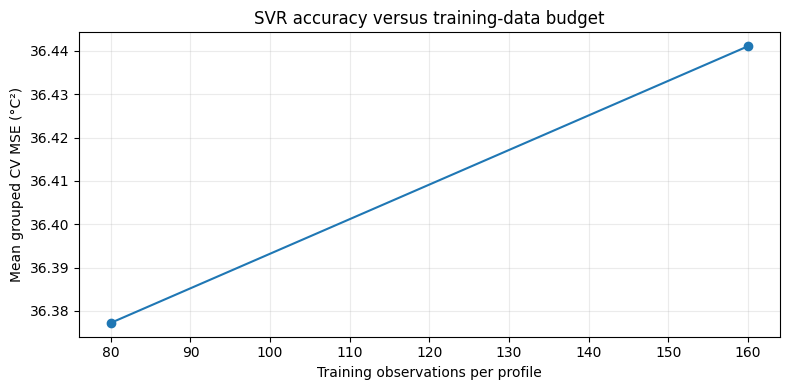

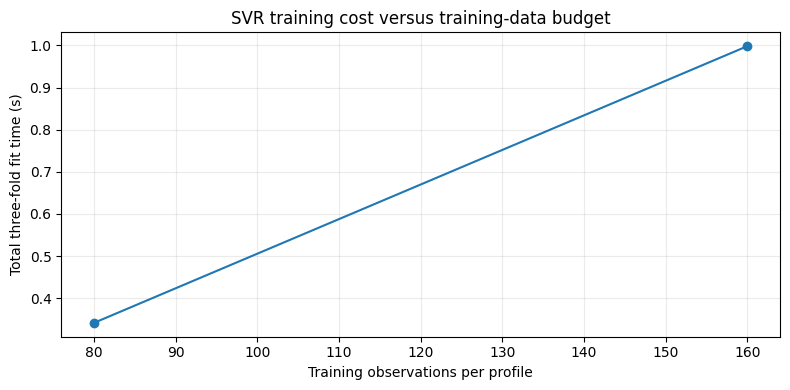

In [32]:
import matplotlib.pyplot as plt
fig, ax=plt.subplots(figsize=(8,4))
ax.plot(stage5_summary.Samples_per_Profile,stage5_summary.Mean_CV_MSE,'o-')
ax.set(xlabel='Training observations per profile',ylabel='Mean grouped CV MSE (°C²)',
       title='SVR accuracy versus training-data budget')
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(STAGE5_DIR/'svr_accuracy_vs_budget.png',dpi=180)
plt.show()

fig, ax=plt.subplots(figsize=(8,4))
ax.plot(stage5_summary.Samples_per_Profile,stage5_summary.Total_3Fold_Training_s,'o-')
ax.set(xlabel='Training observations per profile',ylabel='Total three-fold fit time (s)',
       title='SVR training cost versus training-data budget')
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(STAGE5_DIR/'svr_fit_time_vs_budget.png',dpi=180)
plt.show()

# This verification run evaluates only the two explicitly declared training budgets.
assert set(stage5_summary['Samples_per_Profile']) == {80, 160}
print('Verification scope: 80 and 160 training observations/profile only.')
print('Historical 320-versus-640 comparison: not rerun; see Sections 5E–5F.')
print('Lowest mean CV MSE among verification budgets (NOT the historical four-budget optimum):',
      int(stage5_summary.loc[stage5_summary.Mean_CV_MSE.idxmin(),'Samples_per_Profile']))

## 5G · Export a reproducibility and engineering audit

The audit records the frozen settings, exact raw dataset checksum, software versions, training budgets and summary. The CSV and figures are **generated outputs**, never prerequisites for Run All.

In [33]:
stage5_audit={
  'original_notebook_cells':'68–79',
  'experiment':'nested grouped three-fold SVR training-data scalability',
  'source_csv_sha256':actual_sha256,
  'development_profiles':len(development_ids),
  'final_test_profiles_excluded':len(test_ids),
  'sensor_sampling_hz':FS_HZ,
  'span_configuration':list(STAGE5_SPANS),
  'svr_hyperparameters':STAGE5_SVR_HP,
  'configuration_provenance':STAGE5_CONFIG_SOURCE,
  'nested_sample_sizes_constructed':list(STAGE5_SAMPLE_SIZES),
  'training_samples_per_profile_evaluated':list(STAGE5_EVALUATED_SIZES),
  'execution_scope':'verification: 80 and 160 samples/profile, one fit per fold',
  'validation_samples_per_profile':STAGE5_MAX_SAMPLES,
  'repeats_per_fold':STAGE5_REPEATS,
  'feature_count':len(stage5_feature_cols),
  'feature_generation_time_s':stage5_feature_time_s,
  'python_version':platform.python_version(),
  'numpy_version':np.__version__,
  'pandas_version':pd.__version__,
  'scikit_learn_version':sklearn.__version__,
  'summary':stage5_summary.to_dict(orient='records')
}
(STAGE5_DIR/'stage5_audit.json').write_text(json.dumps(stage5_audit,indent=2))
print('PASS: Stage 5 audit saved at',STAGE5_DIR)

PASS: Stage 5 audit saved at /workspace/scratch/0a8876c2681b/deliverables/mma3001_project/results/full/development/stage5


**Stage 5 checkpoint:** This run measures sampled SVR behaviour under fixed pilot hyperparameters at **80 and 160 observations/profile**. Of those two verified budgets, 80 has the lower mean three-fold MSE; this **does not overturn** the original four-budget experiment, whose lowest recorded mean MSE occurred at **320 observations/profile**. Timings are environment-dependent. Neither experiment establishes a full-development-data SVR training limit.



## RQ4 — Numerical credibility, convergence and limits of evidence

A 108-column float64 full-development matrix alone occupies 911,691,072 bytes (about 0.849 GiB); scalers, model structures, solver copies, raw data and QR workspaces require additional memory. A conceptual dense N-by-N float64 kernel at N=1,055,198 would need about 8.91 TB. LIBSVM uses a bounded kernel cache rather than necessarily allocating that dense matrix; this estimate explains scaling pressure, not observed allocation or a universal exact runtime law.

For OLS, set \(A_j=[\mathbf1,X_j,y_j]\) for profile j and factor \(A_j=Q_jR_j\). Orthogonality gives \(\|A_jv\|_2^2=\|R_jv\|_2^2\) for any compatible v. Summing over profiles preserves the total least-squares objective when their R factors are stacked. Profile moments are combined by

\[
\mu=\frac{\sum_jn_j\mu_j}{N},\qquad
v=\frac{\sum_jn_j[v_j+(\mu_j-\mu)^2]}{N}.
\]

The between-profile term is essential: averaging variances alone loses shifts in means. For a compressed augmented factor, standardisation is effected by \(R_X^{scaled}=(R_X-R_1\mu^T)/d\), with population scales \(d_k=\sqrt{v_k}\) and zero scales replaced by one. `lstsq(..., lapack_driver='gelsd')` solves the transformed system; raw-space coefficients are recovered as \(\beta_k=w_k/d_k\), \(b=w_0-\mu^T\beta\). These are the original numerical operations (SciPy developers, 2025). They avoid explicitly forming \((X^TX)^{-1}\), which can amplify conditioning problems.

Verification checks direct versus compressed residual norms on real profile data, independently computed weighted moments, full-history versus sampled features, train-only moment aggregation, QR versus scikit-learn predictions on the same 4,400-row sample, and train-save-reload-predict invariance. Historical QR/sklearn maximum prediction difference is about 1.471e-12 °C. Tolerances assess floating-point agreement (not physical sensor accuracy). Test fixtures use rtol 1e-11 for a residual identity; the original real-data experiments retain their own tolerances. Nearly collinear synthetic features are assessed by predictions rather than unstable individual coefficient values. The full OLS code retains its rank-109 assertion and does not silently change rank thresholds.

Stage 3's historical OLS estimate of 239.77 °C for profile 65 at its initial sample is retained. Its largest error contributes about 33.9% of that sample's SSE. Removing it only for an explicitly labelled influence diagnostic is not an improved model result; all fitting and official metrics retain the point. Plausible insufficient initial-state information is an interpretation, not a proven physical cause. No clipping, replacement, burn-in deletion or alternative estimator is introduced.

A `ConvergenceWarning` is retained as numerical evidence. No warning means the solver's configured stopping test was met, not proof of globally optimal engineering performance. Full final training aborts on a convergence warning as the source requires; it does not silently increase `max_iter` or change a solver. Stage 9 records unsuccessful/nonconverged candidates and excludes warned candidates from the specified selection steps.

Fold SD reflects changes in validation sessions and overlapping training sets. Three folds are not independent repetitions and do not support a claimed 95% confidence interval. Stage 9H nests C selection only: its spans and epsilon were fixed from prior development work, so it is not fully nested assessment of the entire feature/hyperparameter search. Stage 9I selects and reports on the same development folds and therefore supports selection, not an unbiased final generalisation estimate. Repeated manual inspection of Fold 1 can also make its screening estimates optimistic.

Historical timing and RSS are hardware/process-specific. RSS polling at 0.05 or 0.1 seconds can miss brief peaks, includes interpreter/kernel and retained arrays, and is not isolated estimator allocation. A single timing is descriptive. These qualifications preserve the unsuccessful experiments and provide engineering limits to positive findings.


---
# Stage 6 — QR-compressed OLS numerical verification

The archival experiment implemented profile-wise QR compression and evaluated full-development-data OLS. This verification notebook **checks the algebra and reproduces a small-scale solver comparison only**. It does not train the 1,055,198-row final OLS model.


In [34]:
from scipy.linalg import qr, lstsq
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd
import time, json, platform

STAGE6_DIR = OUTPUT_DIR / 'stage6'
STAGE6_DIR.mkdir(parents=True, exist_ok=True)
STAGE6_SEED_SPANS = (89, 265, 622, 3829)
STAGE6_QR_CHUNK_ROWS = 4096
STAGE6_EXPECTED_DEV_ROWS = 1_055_198
STAGE6_FEATURE_NAMES = [*make_paper_inputs(development_df.iloc[:2]).columns]
STAGE6_FEATURE_NAMES = STAGE6_FEATURE_NAMES + [
    name for col in STAGE6_FEATURE_NAMES for span in STAGE6_SEED_SPANS
    for name in (f'{col}_ewma_s{span}', f'{col}_ewms_s{span}')
]
assert len(STAGE6_FEATURE_NAMES) == 108
assert len(development_df) == STAGE6_EXPECTED_DEV_ROWS
assert development_df.profile_id.nunique() == 55
assert set(development_df.profile_id).isdisjoint(test_ids)
assert set(profile_cv.cv_fold.unique()) == {1, 2, 3}
print('PASS: Stage 6 settings verified; final test remains excluded.')


PASS: Stage 6 settings verified; final test remains excluded.


## 6B · QR block compression with profile-level statistics

Compute all 108 predictors using each profile's original chronological data. The vectorised transform from Stage 5 is equivalent to the checked Pandas EWM transform in Stage 2. We align columns to Stage 2's definition so the numerical verification uses the same design matrix.

The small per-profile statistics `(n, mean, variance)` allow standardisation to be calculated **using training profiles only** in each fold. Each profile's compressed `R` factor includes a target column, so the validation residual norm can also be evaluated without storing its original `X` rows.

In [35]:
from pmsm_project.features import stage6_feature_names


from pmsm_project.numerics import compress_profile_ols

print('PASS: Profile QR compressor defined.')

PASS: Profile QR compressor defined.


## 6C · Two independent numerical verification tests

**Test A** checks that the sum of squared residuals from the compressed factor agrees with direct calculations on a 300-row profile.

**Test B** compares QR-based OLS fitted on the same sampled 4,400-observation dataset with Scikit-learn's `LinearRegression`. This is an **implementation verification**, not evidence that OLS has small predictive error. We do not access the final test set.

In [36]:
# A — Verify the QR residual identity, using data not manufactured by the formula.
_demo_pid = int(profile_cv.iloc[0].profile_id)
_demo = development_df.loc[development_df.profile_id.eq(_demo_pid)].head(300).copy()
_demo_X = make_temporal_features(make_paper_inputs(_demo), _demo.profile_id,
                                STAGE6_SEED_SPANS).to_numpy(dtype=np.float64)
_demo_y = _demo.pm.to_numpy(dtype=np.float64)
_demo_qr = compress_profile_ols(_demo, STAGE6_SEED_SPANS, chunk_size=128)

_w = np.zeros(110, dtype=np.float64)
_w[0], _w[1], _w[-1] = 25.0, 0.01, -1.0
_direct_sse = float(np.sum((25 + 0.01*_demo_X[:,0] - _demo_y)**2))
_qr_sse = float(np.linalg.norm(_demo_qr['R'] @ _w)**2)
np.testing.assert_allclose(_qr_sse, _direct_sse, rtol=1e-8, atol=1e-8)
assert _demo_qr['R'].shape == (110,110)
print(f'PASS: Direct SSE={_direct_sse:.12f}; QR SSE={_qr_sse:.12f}')

# B — Confirm vectorised Stage 5 feature generation matches Stage 2 precisely.
_compare_raw = make_paper_inputs(_demo)
_fast = vectorised_temporal_sample(_compare_raw, np.arange(len(_demo)),
                                   STAGE6_SEED_SPANS)
_slow = make_temporal_features(_compare_raw, _demo.profile_id,
                               STAGE6_SEED_SPANS)
np.testing.assert_allclose(_fast[_slow.columns].to_numpy(),_slow.to_numpy(),
                           rtol=1e-9,atol=1e-9)
print('PASS: Vectorised feature ordering and values match Stage 2.')

PASS: Direct SSE=1080.946939569945; QR SSE=1080.946939569973
PASS: Vectorised feature ordering and values match Stage 2.


In [37]:
# C — Compare independent solvers on the same original 4,400-row Stage 3 dataset.
_verify_features = [c for c in smoke_df.columns
                    if c not in ('profile_id','pm_target','raw_position','elapsed_seconds')]
assert len(_verify_features) == 108
_fold1_ids = set(profile_cv.loc[profile_cv.cv_fold.eq(1), 'profile_id'].astype(int))
_tr = smoke_df.loc[~smoke_df.profile_id.isin(_fold1_ids)]
_va = smoke_df.loc[smoke_df.profile_id.isin(_fold1_ids)]
Xtr, ytr = _tr[_verify_features].to_numpy(), _tr.pm_target.to_numpy()
Xva, yva = _va[_verify_features].to_numpy(), _va.pm_target.to_numpy()
_sc = StandardScaler().fit(Xtr)
_sk = LinearRegression().fit(_sc.transform(Xtr), ytr)
_pred_sklearn = _sk.predict(_sc.transform(Xva))

_Rs, _profile_moments = [], []
for _pid, _part in _tr.groupby('profile_id',sort=False):
    _Xp = _part[_verify_features].to_numpy(dtype=np.float64)
    _yp = _part.pm_target.to_numpy(dtype=np.float64)
    _A = np.column_stack([np.ones(len(_Xp)), _Xp, _yp])
    _Rs.append(qr(_A,mode='r',check_finite=False)[0])
    _profile_moments.append((len(_Xp),_Xp.mean(axis=0),_Xp.var(axis=0)))

_n = sum(item[0] for item in _profile_moments)
_mu = sum(n*mu for n,mu,v in _profile_moments)/_n
_var = sum(n*(v+(mu-_mu)**2) for n,mu,v in _profile_moments)/_n
_scales = np.sqrt(np.maximum(_var,0)); _scales[_scales==0]=1
np.testing.assert_allclose(_mu,_sc.mean_,rtol=1e-9,atol=1e-9)
np.testing.assert_allclose(_scales,_sc.scale_,rtol=1e-9,atol=1e-9)
_Rtrain = np.vstack(_Rs)
_Rscaled = _Rtrain.copy()
_Rscaled[:,1:-1] = (_Rscaled[:,1:-1]-_Rscaled[:,[0]]*_mu)/_scales
_coef,_,_rank,_ = lstsq(_Rscaled[:,:-1],_Rscaled[:,-1],lapack_driver='gelsd')
_beta = _coef[1:]/_scales
_intercept = _coef[0]-_mu@_beta
_pred_qr = Xva@_beta+_intercept
_abs_diff = float(np.max(np.abs(_pred_sklearn-_pred_qr)))
_mse_sk = float(mean_squared_error(yva,_pred_sklearn))
_mse_qr = float(mean_squared_error(yva,_pred_qr))
np.testing.assert_allclose(_pred_qr,_pred_sklearn,rtol=1e-8,atol=1e-6)
np.testing.assert_allclose(_mse_qr,_mse_sk,rtol=1e-8)
print(f'PASS: QR / Scikit-learn match; rank={_rank}; max difference={_abs_diff:.3e} °C')
print(f'Validation MSE (QR={_mse_qr:.8f}, Sklearn={_mse_sk:.8f}) °C²')

PASS: QR / Scikit-learn match; rank=109; max difference=1.748e-12 °C
Validation MSE (QR=88.65626138, Sklearn=88.65626138) °C²


**Stage 6 checkpoint:** The exact same residual calculation is recovered by QR compression, and the QR-based OLS predictions match Scikit-learn's least-squares predictions on the verified sample. Historical full-data CV MSE figures should be cited from the original notebook, not presented as newly measured here.


---
# Stage 7 — Check the model-training budget and validation boundary

The original research contains 12-evaluation Bayesian searches and a later 15-fit training/memory-feasibility campaign. This Run-All edition validates the **one-fold diagnostic pipeline only** (11,520 training rows and 12,160 development-validation rows for the fixed SVR pilot). The original full results are not rerun.

**Provenance qualification:** references here to an earlier research archive describe historical work reported by the supplied notebook. That fuller archive/trial history is not attached; this package preserves the available evidence without certifying unavailable searches.


In [38]:
import os, gc, json, time, warnings, platform
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_squared_error
from sklearn.exceptions import ConvergenceWarning

STAGE7_DIR = OUTPUT_DIR / 'stage7'
STAGE7_DIR.mkdir(parents=True,exist_ok=True)
STAGE7_SEARCH_DIR = STAGE7_DIR / 'scaled_model_bayesian'
STAGE7_SEARCH_DIR.mkdir(parents=True,exist_ok=True)
STAGE7_FEASIBILITY_DIR = STAGE7_DIR / 'training_feasibility'
STAGE7_FEASIBILITY_DIR.mkdir(parents=True,exist_ok=True)

STAGE7_TRIALS = 12
STAGE7_MODELS = ['SVR','k-NN','Random Forest','Extra Trees','MLP']
STAGE7_TRAIN_PER_PROFILE = {'SVR':320,'k-NN':640,'Random Forest':640,
                            'Extra Trees':640,'MLP':640}
STAGE7_VALIDATION_PER_PROFILE = 640
STAGE7_SEED = 42
STAGE7_FOLD_MAP = profile_cv.set_index('profile_id')['cv_fold'].astype(int).to_dict()

assert len(development_df) == 1_055_198 and len(STAGE7_FOLD_MAP)==55
assert set(development_df.profile_id)==set(STAGE7_FOLD_MAP)
assert set(development_df.profile_id).isdisjoint(set(heldout_df.profile_id))
assert set(STAGE7_MODELS)==set(STAGE7_TRAIN_PER_PROFILE)==set(MODEL_SPACES)
assert stage5_data.profile_id.nunique()==55
print('PASS: Stage 7 training budgets, fixed grouped folds and untouched test boundary.')


PASS: Stage 7 training budgets, fixed grouped folds and untouched test boundary.


## 7B · Numerical smoke check using the existing Stage 5 features

Stage 5 already computed the **exact** Stage 4 pilot SVR temporal features for all 55 development profiles. We can use those to verify Stage 7's planned 320-training/640-validation design on *Fold 1*. This is a **single-fold diagnostic**, **not** a new 12-trial optimisation result and not a full CV score. This makes the default Run-All behaviour independently useful without triggering the costly search.

In [39]:
_stage7_tr = (stage5_data.cv_fold.ne(1) & stage5_data.nest_rank.lt(320))
_stage7_va = stage5_data.cv_fold.eq(1) & stage5_data.nest_rank.lt(640)
assert _stage7_tr.sum()==36*320 and _stage7_va.sum()==19*640
assert set(stage5_data.loc[_stage7_tr,'profile_id']).isdisjoint(
       set(stage5_data.loc[_stage7_va,'profile_id']))

quick_Xtr=stage5_data.loc[_stage7_tr,stage5_feature_cols].to_numpy(dtype=np.float64)
quick_ytr=stage5_data.loc[_stage7_tr,'pm_target'].to_numpy(dtype=np.float64)
quick_Xva=stage5_data.loc[_stage7_va,stage5_feature_cols].to_numpy(dtype=np.float64)
quick_yva=stage5_data.loc[_stage7_va,'pm_target'].to_numpy(dtype=np.float64)

quick_model=TransformedTargetRegressor(
    regressor=Pipeline([('scaler',StandardScaler()),
                        ('model',make_regressor('SVR',STAGE5_SVR_HP))]),
    transformer=StandardScaler())
_t=time.perf_counter(); quick_model.fit(quick_Xtr,quick_ytr)
quick_fit_s=time.perf_counter()-_t
_t=time.perf_counter(); quick_pred=quick_model.predict(quick_Xva)
quick_predict_s=time.perf_counter()-_t
quick_mse=float(mean_squared_error(quick_yva,quick_pred))
assert np.isfinite(quick_pred).all() and np.isfinite(quick_mse)
quick_result={'model':'SVR','fold':1,'training_rows':len(quick_ytr),
              'validation_rows':len(quick_yva),'train_samples_per_profile':320,
              'validation_samples_per_profile':640,'mse':quick_mse,
              'fit_time_s':quick_fit_s,'predict_time_s':quick_predict_s,
              'n_support_vectors':int(len(quick_model.regressor_.named_steps['model'].support_))}
(STAGE7_DIR/'quick_fold1_diagnostic.json').write_text(json.dumps(quick_result,indent=2))
print('PASS: Stage 7 one-fold SVR diagnostic (not a complete three-fold model result)')
print(json.dumps(quick_result,indent=2))
del quick_model,quick_Xtr,quick_Xva,quick_ytr,quick_yva,quick_pred

PASS: Stage 7 one-fold SVR diagnostic (not a complete three-fold model result)
{
  "model": "SVR",
  "fold": 1,
  "training_rows": 11520,
  "validation_rows": 12160,
  "train_samples_per_profile": 320,
  "validation_samples_per_profile": 640,
  "mse": 35.05651641782601,
  "fit_time_s": 1.0553971430001639,
  "predict_time_s": 1.4843992799999342,
  "n_support_vectors": 1401
}


**Stage 7 checkpoint:** One-fold training and prediction complete with the test profiles excluded. This is **not** the full Stage 7 12-trial five-model comparison or memory-scaling experiment.


---
# Stage 8 — Verification of model serialisation and provenance

The updated **original research notebook** reports full-development-data training of OLS, k-NN, Random Forest, Extra Trees and MLP, and an SVR attempt stopped by a 30-minute fitting budget. This section **does not reproduce those full-data fits**. Instead, it verifies that an independent development-only model can be fitted, saved and reloaded without changing predictions.

**Provenance qualification:** references here to an earlier research archive describe historical work reported by the supplied notebook. That fuller archive/trial history is not attached; this package preserves the available evidence without certifying unavailable searches.


In [40]:
# 8A — Retain historical evidence separately from new calculations.
from pathlib import Path
import json, time, hashlib, platform, warnings, gc
import joblib
from sklearn.metrics import mean_squared_error

STAGE8_DIR = OUTPUT_DIR / 'stage8'
STAGE8_DIR.mkdir(parents=True, exist_ok=True)
STAGE8_MODELS_DIR = STAGE8_DIR / 'models'
STAGE8_MODELS_DIR.mkdir(parents=True, exist_ok=True)
STAGE8_HISTORY = pd.DataFrame([
    {'Model':'OLS','Full_data_status':'SUCCESS','Full_rows':1055198,'Fit_s':None,'Reason':'QR-based model already saved'},
    {'Model':'k-NN','Full_data_status':'SUCCESS','Full_rows':1055198,'Fit_s':2.470573,'Reason':''},
    {'Model':'Extra Trees','Full_data_status':'SUCCESS','Full_rows':1055198,'Fit_s':224.482728,'Reason':''},
    {'Model':'MLP','Full_data_status':'SUCCESS','Full_rows':1055198,'Fit_s':145.966348,'Reason':''},
    {'Model':'Random Forest','Full_data_status':'SUCCESS','Full_rows':1055198,'Fit_s':1961.768229,'Reason':''},
    {'Model':'SVR','Full_data_status':'STOPPED','Full_rows':None,'Fit_s':None,'Reason':'1800-second time guard; 1801.8 seconds elapsed'}
])
STAGE8_HISTORY.to_csv(STAGE8_DIR/'historical_stage8_full_data_status.csv',index=False)
assert len(STAGE8_HISTORY)==6
assert set(STAGE8_HISTORY.Model)==set(['OLS']+STAGE7_MODELS)
assert set(development_df.profile_id).isdisjoint(set(test_ids))
assert len(development_df)==1055198 and development_df.profile_id.nunique()==55
print('HISTORICAL NOTEBOOK RESULTS (not freshly fitted by this cell):')
display(STAGE8_HISTORY)
print('PASS: 55-development / 14-test profile boundary preserved.')

HISTORICAL NOTEBOOK RESULTS (not freshly fitted by this cell):
PASS: 55-development / 14-test profile boundary preserved.


,Model,Full_data_status,Full_rows,Fit_s,Reason
0,OLS,SUCCESS,1055198.0,NaN,QR-based model already saved
1,k-NN,SUCCESS,1055198.0,2.470573,
2,Extra Trees,SUCCESS,1055198.0,224.482728,
3,MLP,SUCCESS,1055198.0,145.966348,
4,Random Forest,SUCCESS,1055198.0,1961.768229,
5,SVR,STOPPED,NaN,NaN,1800-second time guard; 1801.8 seconds elapsed


### Development-only train → save → reload → predict test

This produces a 240-row **smoke-test artifact only**—it is not an optimised final-model artifact and must not be used for your final test-set evaluation.


In [41]:
# 8C — Truly executed cheap persistence test (NOT a final SVR fit).
_smoke_spans=STAGE5_SPANS
_smoke_hp=STAGE5_SVR_HP
_smoke_raw=[];_smoke_y=[];_smoke_pids=[]
for _pid,_profile in list(development_df.groupby('profile_id',sort=False))[:3]:
    _positions=np.sort(np.asarray(nested_sample_order(len(_profile),80)))
    _base=make_paper_inputs(_profile)
    _ff=vectorised_temporal_sample(_base,_positions,_smoke_spans)
    _order=stage6_feature_names(_base.columns,_smoke_spans)
    _smoke_raw.append(_ff.loc[:,_order].to_numpy(dtype=np.float64))
    _smoke_y.append(_profile.pm.iloc[_positions].to_numpy(dtype=np.float64))
    _smoke_pids.append(int(_pid))
_Xcheck=np.vstack(_smoke_raw);_ycheck=np.concatenate(_smoke_y)
assert _Xcheck.shape==(240,108) and set(_smoke_pids).isdisjoint(test_ids)
_smoke_model=TransformedTargetRegressor(
    regressor=Pipeline([('scaler',StandardScaler()),('model',SVR(**_smoke_hp))]),
    transformer=StandardScaler())
_smoke_model.fit(_Xcheck,_ycheck)
_prediction_before=_smoke_model.predict(_Xcheck[:12])
_smoke_file=STAGE8_MODELS_DIR/'development_only_persistence_smoke.joblib'
joblib.dump({'estimator':_smoke_model,'features':_order,
             'profiles':_smoke_pids,'scope':'ONLY A 240-ROW SMOKE TEST'},_smoke_file)
_smoke_loaded=joblib.load(_smoke_file)
_prediction_after=_smoke_loaded['estimator'].predict(_Xcheck[:12])
np.testing.assert_allclose(_prediction_before,_prediction_after,atol=1e-10,rtol=1e-12)
print('PASS: Development-only model train→joblib→reload→predict')
print('Rows:',len(_Xcheck),'Features:',_Xcheck.shape[1],
      'File:',_smoke_file.name)
del _smoke_model,_smoke_loaded,_smoke_raw,_smoke_y,_Xcheck,_ycheck

PASS: Development-only model train→joblib→reload→predict
Rows: 240 Features: 108 File: development_only_persistence_smoke.joblib


In [42]:
# Final audit: check that the verification work is self-contained and excludes final-test learning.
verification_summary = {
    'purpose': 'Stages 1–8 methodology verification / retracing, not complete research replay',
    'dataset_sha256': actual_sha256,
    'total_profiles': int(df.profile_id.nunique()),
    'development_profiles': len(development_ids),
    'untouched_test_profiles': len(test_ids),
    'feature_count': len(stage5_feature_cols),
    'ols_bayesian_pilot_trials_executed': len(ols_pilot_df),
    'stage5_svr_fits_executed': len(stage5_results),
    'qr_and_sklearn_max_difference_celsius': _abs_diff,
    'stage7_smoke_training_rows': quick_result['training_rows'],
    'stage8_persistence_verified': True,
    'full_historical_searches_replayed': False,
    'full_data_models_retrained': False,
    'final_holdout_evaluated': False
}
assert verification_summary['total_profiles'] == 69
assert verification_summary['development_profiles'] == 55
assert verification_summary['untouched_test_profiles'] == 14
assert verification_summary['feature_count'] == 108
assert verification_summary['ols_bayesian_pilot_trials_executed'] == 8
assert verification_summary['stage5_svr_fits_executed'] == 6
assert verification_summary['stage7_smoke_training_rows'] == 11520
assert set(development_df.profile_id).isdisjoint(test_ids)
(OUTPUT_DIR/'verification_run_summary.json').write_text(json.dumps(verification_summary, indent=2))
print('PASS: Stages 1–8 verification completed without test-set modelling.')
print(json.dumps(verification_summary, indent=2))


PASS: Stages 1–8 verification completed without test-set modelling.
{
  "purpose": "Stages 1\u20138 methodology verification / retracing, not complete research replay",
  "dataset_sha256": "78f3d150f0f2ad9c5dc7ff24dd12c00d386ad530f48c1589ad24fcd88867d3ad",
  "total_profiles": 69,
  "development_profiles": 55,
  "untouched_test_profiles": 14,
  "feature_count": 108,
  "ols_bayesian_pilot_trials_executed": 8,
  "stage5_svr_fits_executed": 6,
  "qr_and_sklearn_max_difference_celsius": 1.7479351299698465e-12,
  "stage7_smoke_training_rows": 11520,
  "stage8_persistence_verified": true,
  "full_historical_searches_replayed": false,
  "full_data_models_retrained": false,
  "final_holdout_evaluated": false
}


---

# Stage 9 — Computationally Efficient Support Vector Regression

## 9A. Experimental Configuration and Methodological Controls

### Objective

Previous computational experiments demonstrated that conventional
RBF-SVR becomes expensive as the number of training observations
increases. A full-development-data fit was not completed within
the imposed 30-minute computational budget.

This investigation evaluates whether alternative computational
formulations can improve the trade-off between prediction accuracy,
training time, inference time and memory consumption.

### Approaches to investigate

1. Exact RBF-SVR with computationally bounded training observations.
2. Nyström-approximated RBF features followed by LinearSVR.
3. Direct LinearSVR as a computational reference.

### Experimental controls

- Retain the original 55 development profiles.
- Preserve the existing three-fold grouped cross-validation.
- Exclude all 14 held-out test profiles from model selection.
- Retain the validated causal EWMA/EWMS feature calculations.
- Use identical training and validation observations when comparing methods.
- Record all fitting configurations and numerical results.

### Reference configuration

The later historical Bayesian optimisation selected:

- SVR penalty: C = 0.1561749574579009
- Epsilon: 0.08676795206949453
- EWMA/EWMS spans: (91, 358, 1712, 7591)

These hyperparameters serve as the reference configuration for
exact RBF-SVR. They are not automatically optimal for LinearSVR
or Nyström-based alternatives.

### Initial experiment

Use Fold 1 and 640 training observations per training profile.

The initial experiment will compare methods using 23,040 training
observations and 12,160 validation observations.

This is a controlled screening experiment, not the final
model-selection or full-development-data training experiment.

In [43]:
# ============================================================
# STAGE 9A — Experimental configuration and invariants
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

# Later historical Bayesian-optimised SVR configuration
STAGE9_SPANS = (91, 358, 1712, 7591)

STAGE9_SVR_HP = {
    "C": 0.1561749574579009,
    "epsilon": 0.08676795206949453,
    "kernel": "rbf",
    "gamma": "scale"
}

STAGE9_SEED = 42

# Initial computational budget
STAGE9_SAMPLES_PER_PROFILE = 640
STAGE9_SCREENING_FOLD = 1

# Output directory
STAGE9_DIR = OUTPUT_DIR / "stage9_efficient_svr"
STAGE9_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Verify the original dataset and partition are unchanged
# ------------------------------------------------------------

assert len(development_df) == 1_055_198
assert len(development_ids) == 55
assert len(test_ids) == 14

assert sorted(test_ids) == LOCKED_TEST_IDS

assert set(development_ids).isdisjoint(set(test_ids))

assert set(profile_cv["profile_id"]) == set(development_ids)

assert set(profile_cv["cv_fold"]) == {1, 2, 3}

# Retrieve original fixed Fold 1 profile allocations
train_ids, val_ids = fold_train_val[STAGE9_SCREENING_FOLD]

assert len(train_ids) == 36
assert len(val_ids) == 19

assert set(train_ids).isdisjoint(val_ids)
assert set(train_ids).isdisjoint(test_ids)
assert set(val_ids).isdisjoint(test_ids)

expected_train_rows = len(train_ids) * STAGE9_SAMPLES_PER_PROFILE
expected_val_rows = len(val_ids) * STAGE9_SAMPLES_PER_PROFILE

# ------------------------------------------------------------
# Print methodological verification
# ------------------------------------------------------------

print("STAGE 9A — CONFIGURATION CHECK")
print("=" * 50)

print("Development profiles:", len(development_ids))
print("Held-out test profiles:", len(test_ids))

print("\nCross-validation:")
print("Screening fold:", STAGE9_SCREENING_FOLD)
print("Training profiles:", len(train_ids))
print("Validation profiles:", len(val_ids))

print("\nPlanned screening observations:")
print("Training:", expected_train_rows)
print("Validation:", expected_val_rows)

print("\nFrozen reference SVR:")
print("C:", STAGE9_SVR_HP["C"])
print("Epsilon:", STAGE9_SVR_HP["epsilon"])
print("Temporal spans:", STAGE9_SPANS)

print("\nPASS: Stage 9A configuration verified.")

STAGE 9A — CONFIGURATION CHECK
Development profiles: 55
Held-out test profiles: 14

Cross-validation:
Screening fold: 1
Training profiles: 36
Validation profiles: 19

Planned screening observations:
Training: 23040
Validation: 12160

Frozen reference SVR:
C: 0.1561749574579009
Epsilon: 0.08676795206949453
Temporal spans: (91, 358, 1712, 7591)

PASS: Stage 9A configuration verified.



## 9B — Construction of a Common Training and Validation Dataset

### Objective

Construct a common feature representation and a fixed
development-only train-validation split for the four
computational SVR approaches.

### Methodology

For each of the 55 development profiles:

1. Preserve the original chronological recording order.
2. Construct the 12 instantaneous electrical and thermal predictors.
3. Calculate EWMA and EWMS over the complete profile using
   the later Bayesian-optimised spans (91, 358, 1712, 7591).
4. Select 640 observations using the existing nested
   interval-bisection sampling algorithm.
5. Preserve original row positions, nested sampling ranks,
   target measurements and grouped cross-validation assignments.

Each selected observation has 108 predictors:

- 12 instantaneous features
- 48 EWMA features
- 48 EWMS features

### Fixed Fold 1 screening dataset

- Training: 36 profiles × 640 = 23,040 observations.
- Validation: 19 profiles × 640 = 12,160 observations.

All computational approaches will receive exactly these
same training and validation observations.

### Leakage prevention

- No held-out test profiles are accessed.
- Temporal features use only historical observations
  from their own motor profiles.
- Scaling parameters will be fitted on Fold 1 training
  observations only, in the following experiment.
- The validation set will not influence kernel basis
  selection, model fitting or hyperparameter selection.

This stage prepares and verifies data. No estimator is fitted.


In [44]:

# ============================================================
# STAGE 9B.1 — Regenerate optimised temporal features
# ============================================================

import time
import numpy as np
import pandas as pd

start_time = time.perf_counter()

STAGE9_MAX_SAMPLES = STAGE9_SAMPLES_PER_PROFILE

# Original development-only fold assignments
stage9_fold_map = (
    profile_cv.set_index("profile_id")["cv_fold"]
    .astype(int)
    .to_dict()
)

stage9_parts = []

# ------------------------------------------------------------
# Process each complete chronological development profile
# ------------------------------------------------------------

for count, (pid, profile) in enumerate(
    development_df.groupby("profile_id", sort=False),
    start=1
):

    # Verify chronological order within the recording
    assert profile.index.is_monotonic_increasing

    # Reuse the validated nested sampling procedure
    selection_order = nested_sample_order(
        len(profile),
        STAGE9_MAX_SAMPLES
    )

    positions = np.sort(
        np.asarray(selection_order, dtype=int)
    )

    # Rank describes the order in which each sample
    # was added by the nested sampling algorithm
    rank_lookup = {
        int(position): rank
        for rank, position in enumerate(selection_order)
    }

    # Step 1: Construct instantaneous engineering predictors
    X_base = make_paper_inputs(profile)

    # Step 2: Generate temporal features from complete history,
    # then retrieve the selected rows
    X_sample = vectorised_temporal_sample(
        X_base,
        positions,
        STAGE9_SPANS
    )

    # Ensure consistent 108-column ordering
    ordered_features = stage6_feature_names(
        X_base.columns,
        STAGE9_SPANS
    )

    X_sample = X_sample.loc[:, ordered_features].copy()

    # Step 3: Attach target and audit metadata
    X_sample["pm_target"] = (
        profile["pm"].iloc[positions].to_numpy(dtype=np.float64)
    )

    X_sample["profile_id"] = int(pid)
    X_sample["raw_position"] = positions
    X_sample["source_row"] = X_sample.index.to_numpy()

    X_sample["nest_rank"] = [
        rank_lookup[int(position)]
        for position in positions
    ]

    X_sample["cv_fold"] = stage9_fold_map[int(pid)]

    stage9_parts.append(X_sample)

    if count % 10 == 0 or count == 55:
        print(f"Processed {count}/55 development profiles")

# ------------------------------------------------------------
# Combine the selected observations
# ------------------------------------------------------------

stage9_data = pd.concat(
    stage9_parts,
    ignore_index=True
)

stage9_feature_cols = stage6_feature_names(
    make_paper_inputs(development_df.iloc[:2]).columns,
    STAGE9_SPANS
)

stage9_feature_time = time.perf_counter() - start_time

print("\nSTAGE 9B — FEATURE CONSTRUCTION")
print("=" * 50)
print("Observations:", f"{len(stage9_data):,}")
print("Profiles:", stage9_data.profile_id.nunique())
print("Predictors:", len(stage9_feature_cols))
print("Temporal spans:", STAGE9_SPANS)
print("Construction time:", round(stage9_feature_time, 2), "s")


Processed 10/55 development profiles
Processed 20/55 development profiles
Processed 30/55 development profiles
Processed 40/55 development profiles
Processed 50/55 development profiles
Processed 55/55 development profiles

STAGE 9B — FEATURE CONSTRUCTION
Observations: 35,200
Profiles: 55
Predictors: 108
Temporal spans: (91, 358, 1712, 7591)
Construction time: 1.53 s


In [45]:

# ============================================================
# STAGE 9B.2 — Numerical and methodological verification
# ============================================================

# 1. Feature dimensions and finite values
assert len(stage9_data) == 55 * 640
assert len(stage9_feature_cols) == 108

assert stage9_feature_cols == list(stage9_data.columns[:108])

assert np.isfinite(
    stage9_data[stage9_feature_cols + ["pm_target"]]
    .to_numpy(dtype=np.float64)
).all()

# 2. No leakage from held-out test profiles
assert set(stage9_data.profile_id).isdisjoint(test_ids)

# 3. Exactly 640 unique sampling ranks per profile
assert stage9_data.groupby("profile_id").size().eq(640).all()

assert (
    stage9_data.groupby("profile_id")
    .nest_rank.nunique()
    .eq(640)
    .all()
)

assert stage9_data["source_row"].is_unique

# 4. Verify original targets and sample positions
source_rows = stage9_data["source_row"].to_numpy(dtype=int)

np.testing.assert_allclose(
    stage9_data["pm_target"].to_numpy(),
    development_df.loc[source_rows, "pm"].to_numpy(),
    rtol=0,
    atol=0
)

# 5. Confirm identical sampling ranks and profile assignments
#    against Version 1.0 Stage 5.
comparison_cols = ["profile_id", "nest_rank", "cv_fold"]

assert stage9_data[comparison_cols].equals(
    stage5_data[comparison_cols]
), "Stage 9 sampling does not match the verified Stage 5."

# Verify the 12 instantaneous predictors are unchanged
base_cols = list(make_paper_inputs(development_df.iloc[:2]).columns)

np.testing.assert_allclose(
    stage9_data[base_cols].to_numpy(),
    stage5_data[base_cols].to_numpy(),
    rtol=0,
    atol=1e-12
)

# 6. Independent first-observation boundary condition
first_rows = stage9_data.groupby("profile_id", sort=False).head(1)

assert first_rows["raw_position"].eq(0).all()

for span in STAGE9_SPANS:
    np.testing.assert_allclose(
        first_rows[f"i_q_ewma_s{span}"],
        first_rows["i_q"],
        rtol=0,
        atol=1e-12
    )
    np.testing.assert_allclose(
        first_rows[f"i_q_ewms_s{span}"],
        0.0,
        rtol=0,
        atol=1e-12
    )

print("PASS: Features, sampled positions and targets verified")

# ------------------------------------------------------------
# 7. Prepare the original fixed Fold 1
# ------------------------------------------------------------

stage9_train_mask = (
    stage9_data["cv_fold"].ne(STAGE9_SCREENING_FOLD)
)

stage9_val_mask = (
    stage9_data["cv_fold"].eq(STAGE9_SCREENING_FOLD)
)

stage9_train = stage9_data.loc[stage9_train_mask]
stage9_val = stage9_data.loc[stage9_val_mask]

# Ensure the intended grouped split
assert stage9_train.profile_id.nunique() == 36
assert stage9_val.profile_id.nunique() == 19

assert len(stage9_train) == 23_040
assert len(stage9_val) == 12_160

assert set(stage9_train.profile_id).isdisjoint(
    set(stage9_val.profile_id)
)

# ------------------------------------------------------------
# 8. Establish common model input arrays
# ------------------------------------------------------------

X9_train = stage9_train[
    stage9_feature_cols
].to_numpy(dtype=np.float64)

y9_train = stage9_train[
    "pm_target"
].to_numpy(dtype=np.float64)

X9_val = stage9_val[
    stage9_feature_cols
].to_numpy(dtype=np.float64)

y9_val = stage9_val[
    "pm_target"
].to_numpy(dtype=np.float64)

assert X9_train.shape == (23_040, 108)
assert X9_val.shape == (12_160, 108)

assert y9_train.shape == (23_040,)
assert y9_val.shape == (12_160,)

print("\nSTAGE 9B — FINAL VERIFICATION")
print("=" * 50)

print("Training:")
print("  Profiles:", stage9_train.profile_id.nunique())
print("  X shape:", X9_train.shape)
print("  y shape:", y9_train.shape)

print("\nValidation:")
print("  Profiles:", stage9_val.profile_id.nunique())
print("  X shape:", X9_val.shape)
print("  y shape:", y9_val.shape)

print("\nPASS: Stage 9B completed.")
print("No estimators fitted; held-out test profiles untouched.")


PASS: Features, sampled positions and targets verified

STAGE 9B — FINAL VERIFICATION
Training:
  Profiles: 36
  X shape: (23040, 108)
  y shape: (23040,)

Validation:
  Profiles: 19
  X shape: (12160, 108)
  y shape: (12160,)

PASS: Stage 9B completed.
No estimators fitted; held-out test profiles untouched.



## 9C — Training-Only Standardisation and Kernel Verification

### 9C.1 Objective

Verify the numerical representation used by exact RBF-SVR
and Nyström-approximated SVR before model fitting.

### Input standardisation

The 108 motor predictors have different physical units
and numerical magnitudes. StandardScaler is fitted only
on the Fold 1 training observations.

The same fitted transformation is applied to validation
observations without updating its parameters.

### Target standardisation

Permanent-magnet temperature is also standardised using
the training-set mean and standard deviation.

Predicted values will be inverse-transformed into °C
before calculating validation errors.

### Common RBF kernel parameter

For Scikit-learn SVR, gamma="scale" corresponds to:

    gamma = 1 / (n_features * X_scaled.var())

We explicitly calculate this parameter from the scaled
training matrix and use it in both exact RBF-SVR and
Nyström approximation.

### Nyström numerical verification

For a small development-training subset, calculate:

1. The exact RBF kernel matrix K.
2. The approximate kernel matrix K_approx = Z @ Z.T.
3. Their relative Frobenius error:

    E_K = ||K - K_approx||_F / ||K||_F

Increasing the number of basis components should generally
improve approximation quality, although independently
selected basis subsets need not produce monotonically
decreasing errors.

When every probe observation is included in the basis,
the approximation should reconstruct the original kernel
up to numerical precision.

No regression model is trained and no held-out test
observations are accessed in this stage.


In [46]:

# ============================================================
# STAGE 9C.1 — Standardisation and shared RBF gamma
# ============================================================

import numpy as np

from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# 1. Fit input scaler on training observations ONLY
# ------------------------------------------------------------

stage9_x_scaler = StandardScaler()

X9_train_scaled = stage9_x_scaler.fit_transform(
    X9_train
)

X9_val_scaled = stage9_x_scaler.transform(
    X9_val
)

# ------------------------------------------------------------
# 2. Fit target scaler on training temperatures ONLY
# ------------------------------------------------------------

stage9_y_scaler = StandardScaler()

y9_train_scaled = (
    stage9_y_scaler.fit_transform(
        y9_train.reshape(-1, 1)
    ).ravel()
)

# The validation targets remain in physical units (°C).
# They are not used to fit any scaler.

# ------------------------------------------------------------
# 3. Verify shapes, finite values and transformations
# ------------------------------------------------------------

assert X9_train_scaled.shape == (23_040, 108)
assert X9_val_scaled.shape == (12_160, 108)

assert y9_train_scaled.shape == (23_040,)

assert np.isfinite(X9_train_scaled).all()
assert np.isfinite(X9_val_scaled).all()
assert np.isfinite(y9_train_scaled).all()

# Training input means should be approximately zero.
np.testing.assert_allclose(
    X9_train_scaled.mean(axis=0),
    np.zeros(108),
    atol=1e-9
)

# The standardised target should have zero mean
# and unit population standard deviation.
np.testing.assert_allclose(
    y9_train_scaled.mean(),
    0.0,
    atol=1e-10
)

np.testing.assert_allclose(
    y9_train_scaled.std(),
    1.0,
    atol=1e-10
)

# Verify that the target scaling is reversible.
reconstructed_y = (
    stage9_y_scaler.inverse_transform(
        y9_train_scaled.reshape(-1, 1)
    ).ravel()
)

np.testing.assert_allclose(
    reconstructed_y,
    y9_train,
    rtol=1e-12,
    atol=1e-9
)

# ------------------------------------------------------------
# 4. Compute the reference RBF kernel parameter
# ------------------------------------------------------------

assert STAGE9_SVR_HP["gamma"] == "scale"

STAGE9_GAMMA = 1.0 / (
    X9_train_scaled.shape[1] *
    X9_train_scaled.var()
)

assert np.isfinite(STAGE9_GAMMA)
assert STAGE9_GAMMA > 0

# For all nonconstant features successfully standardised,
# gamma should be close to 1/108.
constant_features = int(
    np.sum(stage9_x_scaler.var_ == 0)
)

# ------------------------------------------------------------
# 5. Report results
# ------------------------------------------------------------

print("STAGE 9C.1 — STANDARDISATION VERIFICATION")
print("=" * 55)

print("Training X:", X9_train_scaled.shape)
print("Validation X:", X9_val_scaled.shape)

print("\nTarget scaling:")
print("Training mean (°C):", stage9_y_scaler.mean_[0])
print("Training std (°C):", stage9_y_scaler.scale_[0])

print("\nRBF kernel:")
print("Reference gamma:", STAGE9_GAMMA)
print("1 / 108:", 1 / 108)
print("Constant input features:", constant_features)

print("\nPASS: Training-only standardisation verified.")


STAGE 9C.1 — STANDARDISATION VERIFICATION
Training X: (23040, 108)
Validation X: (12160, 108)

Target scaling:
Training mean (°C): 60.414991680632674
Training std (°C): 18.0320163001532

RBF kernel:
Reference gamma: 0.009259259259259255
1 / 108: 0.009259259259259259
Constant input features: 0

PASS: Training-only standardisation verified.


In [47]:

# ============================================================
# STAGE 9C.2 — Verify Nyström kernel approximation
# ============================================================

import numpy as np
import pandas as pd

from sklearn.kernel_approximation import Nystroem
from sklearn.metrics.pairwise import rbf_kernel

# ------------------------------------------------------------
# 1. Select a small reproducible training-only probe
# ------------------------------------------------------------

rng = np.random.default_rng(STAGE9_SEED)

probe_indices = rng.choice(
    len(X9_train_scaled),
    size=192,
    replace=False
)

X9_probe = X9_train_scaled[probe_indices]

assert X9_probe.shape == (192, 108)

# ------------------------------------------------------------
# 2. Calculate the exact RBF kernel
# ------------------------------------------------------------

K_exact = rbf_kernel(
    X9_probe,
    X9_probe,
    gamma=STAGE9_GAMMA
)

assert K_exact.shape == (192, 192)

np.testing.assert_allclose(
    K_exact,
    K_exact.T,
    atol=1e-12
)

# ------------------------------------------------------------
# 3. Test different Nyström component counts
# ------------------------------------------------------------

component_counts = (24, 64, 128, 192)

kernel_records = []

for m in component_counts:

    transformer = Nystroem(
        kernel="rbf",
        gamma=STAGE9_GAMMA,
        n_components=m,
        random_state=STAGE9_SEED
    )

    # Fit the Nyström basis and transform the probe.
    Z = transformer.fit_transform(X9_probe)

    assert Z.shape == (192, m)
    assert np.isfinite(Z).all()

    # Reconstruct the approximate kernel.
    K_approx = Z @ Z.T

    relative_error = (
        np.linalg.norm(K_exact - K_approx, ord="fro")
        /
        np.linalg.norm(K_exact, ord="fro")
    )

    assert np.isfinite(relative_error)
    assert relative_error >= 0

    kernel_records.append({
        "Components": m,
        "Kernel_Relative_Error": float(relative_error)
    })

# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------

stage9_kernel_results = pd.DataFrame(kernel_records)

display(stage9_kernel_results)

# Full basis should reconstruct this small kernel
# to within numerical precision.
full_basis_error = stage9_kernel_results.loc[
    stage9_kernel_results["Components"].eq(192),
    "Kernel_Relative_Error"
].iloc[0]

assert full_basis_error < 1e-5, (
    "Full-basis reconstruction error is unexpectedly large."
)

print("\nPASS: Nyström kernel construction verified.")
print("Full-basis relative error:", full_basis_error)
print("No regressors fitted; held-out test data untouched.")



PASS: Nyström kernel construction verified.
Full-basis relative error: 6.9768569789016714e-15
No regressors fitted; held-out test data untouched.


,Components,Kernel_Relative_Error
0,24,2.049158e-01
1,64,8.815736e-02
2,128,3.056675e-02
3,192,6.976857e-15



## 9D — Controlled Screening of Four SVR Approaches

### Objective

Determine whether a Nyström approximation offers a useful
accuracy-versus-computational-cost advantage over exact
RBF-SVR when trained on identical observations.

### Compared methods

1. Exact RBF-SVR.
2. Nyström (128 components) + LinearSVR.
3. Nyström (256 components) + LinearSVR.
4. Direct LinearSVR.

### Experimental controls

All methods use:

- 23,040 identical Fold 1 training observations.
- 12,160 identical Fold 1 validation observations.
- The same 108 engineered motor predictors.
- Training-only feature and target standardisation.
- The same epsilon-insensitive loss convention.
- Fixed initial C and epsilon parameters.
- The same RBF gamma for both nonlinear approaches.

Nyström basis observations are selected only from
the Fold 1 training data.

### Evaluation

Record:

- Validation MSE (°C²).
- Validation RMSE (°C).
- Fitting time (seconds).
- Prediction time (seconds).
- Observed process-memory peak (GiB).
- Convergence warnings.

The recorded memory consumption is process-level
and sampled periodically, not exact model-only memory.

### Interpretation

This initial experiment is a screening comparison,
not the final model selection.

Different feature representations may require
different regularisation parameters. We will only
consider additional hyperparameter tuning after
reviewing the initial accuracy-cost trade-offs.

No held-out test profiles are used.

**New execution measurement caveat:** process-RSS counters on this host are uninformative (a known 32 MB allocation does not change the reported value). Preserve the displayed RSS columns as recorded, but exclude them from memory-use conclusions. Array byte counts remain valid; see `../docs/reports/memory_calibration.json`. This host-specific issue does not invalidate the separately checked numerical predictions.


In [48]:

# ============================================================
# STAGE 9D — Four-method SVR screening
# ============================================================

import os
import gc
import time
import psutil
import warnings
import threading

import numpy as np
import pandas as pd

from sklearn.svm import SVR, LinearSVR
from sklearn.pipeline import Pipeline
from sklearn.kernel_approximation import Nystroem
from sklearn.exceptions import ConvergenceWarning

RUN_STAGE9D = True  # Change to True to run

# ------------------------------------------------------------
# 1. Reference hyperparameters
# ------------------------------------------------------------

C_REF = STAGE9_SVR_HP["C"]
EPSILON_REF = STAGE9_SVR_HP["epsilon"]

def make_linear_svr():
    return LinearSVR(
        C=C_REF,
        epsilon=EPSILON_REF,
        loss="epsilon_insensitive",
        dual=True,
        tol=1e-4,
        max_iter=3000,
        random_state=STAGE9_SEED
    )

def make_nystroem_svr(components):
    return Pipeline([
        (
            "nystroem",
            Nystroem(
                kernel="rbf",
                gamma=STAGE9_GAMMA,
                n_components=components,
                random_state=STAGE9_SEED,
                n_jobs=1
            )
        ),
        ("linear_svr", make_linear_svr())
    ])

stage9d_models = {
    "Exact RBF-SVR": SVR(
        kernel="rbf",
        C=C_REF,
        epsilon=EPSILON_REF,
        gamma=STAGE9_GAMMA,
        cache_size=512
    ),
    "Nystroem-128": make_nystroem_svr(128),
    "Nystroem-256": make_nystroem_svr(256),
    "Direct LinearSVR": make_linear_svr()
}

# ------------------------------------------------------------
# 2. Process-memory sampling helper
# ------------------------------------------------------------

def measure_peak_memory(stop_event, measurements):
    process = psutil.Process(os.getpid())

    while not stop_event.is_set():
        try:
            rss = process.memory_info().rss
            measurements.append(rss)
        except psutil.Error:
            break

        stop_event.wait(0.05)

# ------------------------------------------------------------
# 3. Fit, predict and record
# ------------------------------------------------------------

stage9d_records = []

if RUN_STAGE9D:

    assert X9_train_scaled.shape == (23040, 108)
    assert X9_val_scaled.shape == (12160, 108)

    assert np.isfinite(X9_train_scaled).all()
    assert np.isfinite(X9_val_scaled).all()

    for name, model in stage9d_models.items():

        print("\n" + "=" * 55)
        print("Training:", name)

        gc.collect()

        process = psutil.Process(os.getpid())
        rss_before = process.memory_info().rss

        memory_samples = [rss_before]
        stop_event = threading.Event()

        monitor = threading.Thread(
            target=measure_peak_memory,
            args=(stop_event, memory_samples),
            daemon=True
        )

        monitor.start()

        try:
            # Fit entire estimator, including Nyström mapping
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter(
                    "always",
                    ConvergenceWarning
                )

                t0 = time.perf_counter()

                model.fit(
                    X9_train_scaled,
                    y9_train_scaled
                )

                fit_seconds = time.perf_counter() - t0

            convergence_count = sum(
                issubclass(w.category, ConvergenceWarning)
                for w in caught
            )

            # Predict, including any Nyström transformation
            t1 = time.perf_counter()

            pred_scaled = model.predict(X9_val_scaled)

            pred_celsius = (
                stage9_y_scaler.inverse_transform(
                    pred_scaled.reshape(-1, 1)
                ).ravel()
            )

            predict_seconds = time.perf_counter() - t1

            assert np.isfinite(pred_celsius).all()

            mse = float(
                np.mean((y9_val - pred_celsius) ** 2)
            )

            rmse = float(np.sqrt(mse))

            status = (
                "convergence_warning"
                if convergence_count > 0
                else "success"
            )

            record = {
                "Method": name,
                "Status": status,
                "Training_Rows": len(X9_train_scaled),
                "Validation_Rows": len(X9_val_scaled),
                "MSE_C2": mse,
                "RMSE_C": rmse,
                "Fit_Seconds": fit_seconds,
                "Predict_Seconds": predict_seconds,
                "Convergence_Warnings": convergence_count
            }

            print("MSE (°C²):", round(mse, 4))
            print("RMSE (°C):", round(rmse, 4))
            print("Fit time (s):", round(fit_seconds, 3))
            print("Prediction time (s):",
                  round(predict_seconds, 3))
            print("Status:", status)

        except Exception as exc:
            record = {
                "Method": name,
                "Status": "failed",
                "Training_Rows": len(X9_train_scaled),
                "Validation_Rows": len(X9_val_scaled),
                "MSE_C2": np.nan,
                "RMSE_C": np.nan,
                "Fit_Seconds": np.nan,
                "Predict_Seconds": np.nan,
                "Convergence_Warnings": np.nan,
                "Error": repr(exc)
            }
            print("FAILED:", repr(exc))

        finally:
            stop_event.set()
            monitor.join(timeout=2)

            memory_samples.append(
                process.memory_info().rss
            )

            peak_rss = max(memory_samples)

            record["Peak_RSS_GiB"] = (
                peak_rss / (1024 ** 3)
            )

            record["Peak_RSS_Increase_GiB"] = (
                max(0, peak_rss - rss_before) / (1024 ** 3)
            )

        stage9d_records.append(record)

        # Save after every method, including failed attempts
        stage9d_results = pd.DataFrame(stage9d_records)

        stage9d_results.to_csv(
            STAGE9_DIR / "stage9d_fold1_screening.csv",
            index=False
        )

    print("\nSTAGE 9D — SCREENING RESULTS")
    display(stage9d_results)

else:
    print(
        "Stage 9D is disabled. "
        "Set RUN_STAGE9D = True to execute screening."
    )



Training: Exact RBF-SVR
MSE (°C²): 37.1629
RMSE (°C): 6.0961
Fit time (s): 9.004
Prediction time (s): 6.722
Status: success

Training: Nystroem-128
MSE (°C²): 57.3348
RMSE (°C): 7.572
Fit time (s): 0.284
Prediction time (s): 0.019
Status: success

Training: Nystroem-256
MSE (°C²): 55.4299
RMSE (°C): 7.4451
Fit time (s): 0.562
Prediction time (s): 0.045
Status: success

Training: Direct LinearSVR
MSE (°C²): 37.5362
RMSE (°C): 6.1267
Fit time (s): 6.536
Prediction time (s): 0.001
Status: convergence_warning

STAGE 9D — SCREENING RESULTS


,Method,Status,Training_Rows,Validation_Rows,MSE_C2,RMSE_C,Fit_Seconds,Predict_Seconds,Convergence_Warnings,Peak_RSS_GiB,Peak_RSS_Increase_GiB
0,Exact RBF-SVR,success,23040,12160,37.162851,6.096134,9.004099,6.721703,0,0.000286,0.000000
1,Nystroem-128,success,23040,12160,57.334756,7.571972,0.284380,0.018648,0,0.000286,0.000000
2,Nystroem-256,success,23040,12160,55.429879,7.445125,0.561618,0.044946,0,0.000286,0.000004
3,Direct LinearSVR,convergence_warning,23040,12160,37.536246,6.126683,6.535884,0.001006,1,0.000286,0.000000


,Method,Status,MSE_C2,RMSE_C,Fit_Seconds,Predict_Seconds,Peak_RSS_GiB,Convergence_Warnings
0,Exact RBF-SVR,success,37.1629,6.0961,9.0041,6.7217,0.0003,0
3,Direct LinearSVR,convergence_warning,37.5362,6.1267,6.5359,0.0010,0.0003,1
2,Nystroem-256,success,55.4299,7.4451,0.5616,0.0449,0.0003,0
1,Nystroem-128,success,57.3348,7.5720,0.2844,0.0186,0.0003,0


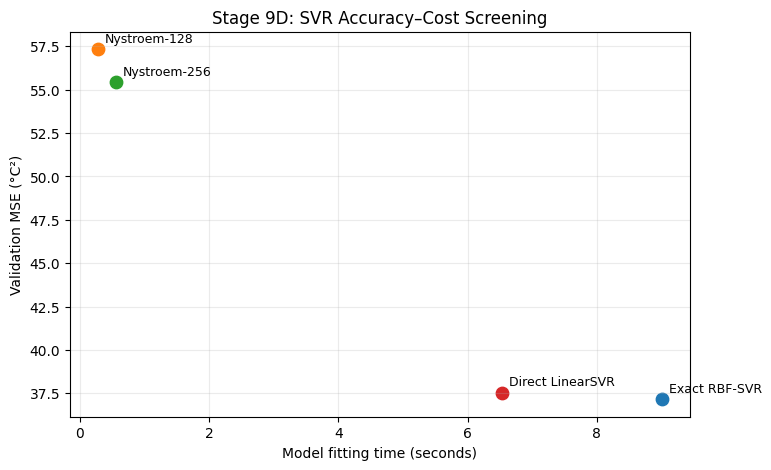

In [49]:

# ============================================================
# STAGE 9D — Accuracy and computational-cost summary
# ============================================================

assert "stage9d_results" in globals(), (
    "Run the Stage 9D screening experiment first."
)

summary_cols = [
    "Method",
    "Status",
    "MSE_C2",
    "RMSE_C",
    "Fit_Seconds",
    "Predict_Seconds",
    "Peak_RSS_GiB",
    "Convergence_Warnings"
]

stage9d_summary = stage9d_results[
    summary_cols
].copy()

display(
    stage9d_summary.sort_values(
        "MSE_C2",
        na_position="last"
    ).round(4)
)

# Plot observed accuracy versus fitting time
import matplotlib.pyplot as plt

valid = stage9d_summary[
    stage9d_summary["MSE_C2"].notna()
]

fig, ax = plt.subplots(figsize=(8, 5))

for _, row in valid.iterrows():
    ax.scatter(
        row["Fit_Seconds"],
        row["MSE_C2"],
        s=80
    )

    ax.annotate(
        row["Method"],
        (row["Fit_Seconds"], row["MSE_C2"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

ax.set_xlabel("Model fitting time (seconds)")
ax.set_ylabel("Validation MSE (°C²)")
ax.set_title("Stage 9D: SVR Accuracy–Cost Screening")
ax.grid(alpha=0.25)

plt.show()



## 9E — Regularisation Sensitivity and Convergence

### Motivation

Stage 9D demonstrated that Nyström approximation greatly reduced
computational cost, but its validation MSE was substantially
higher than that of exact RBF-SVR.

Direct LinearSVR achieved comparable accuracy to exact RBF-SVR,
but produced a convergence warning.

These observations motivate a controlled investigation of
regularisation before increasing the kernel approximation size.

### Method

An inner profile-grouped training-validation split is constructed
using only the 36 training profiles from Stage 9D.

The input and target scalers are fitted again using only
the inner training observations.

Three C values are compared, spanning one order of magnitude
below and above the historical reference C.

The epsilon-insensitive margin, sampling strategy, temporal
features, Nyström component counts and random seed are fixed.

### Limitations

The inner validation results are diagnostic and will be used
to select promising regularisation configurations.

They are not directly comparable with Stage 9D's MSE values
because the validation motor profiles differ.

A later experiment will evaluate the selected approaches
using the original grouped validation framework.

No held-out test profiles are accessed.


In [50]:

# ============================================================
# STAGE 9E.1 — Inner development-only grouped split
# ============================================================

import numpy as np
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

# These are the same 23,040 unscaled training rows
# previously used in Stage 9D.
inner_groups = stage9_train["profile_id"].to_numpy()

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=STAGE9_SEED
)

fit_idx, check_idx = next(
    splitter.split(
        X9_train,
        y9_train,
        groups=inner_groups
    )
)

# Verify group isolation
fit_groups = set(inner_groups[fit_idx])
check_groups = set(inner_groups[check_idx])

assert fit_groups.isdisjoint(check_groups)
assert len(fit_groups) == 27
assert len(check_groups) == 9

# Refit both scalers on inner-training rows ONLY
x_scaler_9e = StandardScaler()
y_scaler_9e = StandardScaler()

X9e_fit = x_scaler_9e.fit_transform(
    X9_train[fit_idx]
)

X9e_check = x_scaler_9e.transform(
    X9_train[check_idx]
)

y9e_fit = y_scaler_9e.fit_transform(
    y9_train[fit_idx].reshape(-1, 1)
).ravel()

y9e_check_celsius = y9_train[check_idx]

# Compute gamma from inner-training features
GAMMA_9E = 1.0 / (
    X9e_fit.shape[1] * X9e_fit.var()
)

assert X9e_fit.shape == (17280, 108)
assert X9e_check.shape == (5760, 108)

assert np.isfinite(X9e_fit).all()
assert np.isfinite(X9e_check).all()
assert np.isfinite(y9e_fit).all()

print("STAGE 9E — INNER SPLIT")
print("Inner training:", X9e_fit.shape)
print("Inner validation:", X9e_check.shape)
print("Training profiles:", len(fit_groups))
print("Validation profiles:", len(check_groups))
print("RBF gamma:", GAMMA_9E)
print("PASS: Grouped split and scaling verified.")


STAGE 9E — INNER SPLIT
Inner training: (17280, 108)
Inner validation: (5760, 108)
Training profiles: 27
Validation profiles: 9
RBF gamma: 0.009259259259259262
PASS: Grouped split and scaling verified.


In [51]:

# ============================================================
# STAGE 9E.2 — C sensitivity screening
# ============================================================

import time
import warnings
import pandas as pd

from sklearn.svm import LinearSVR
from sklearn.kernel_approximation import Nystroem
from sklearn.pipeline import Pipeline
from sklearn.exceptions import ConvergenceWarning

RUN_STAGE9E = True  # Set True to execute

C_GRID_9E = [
    STAGE9_SVR_HP["C"] / 10,
    STAGE9_SVR_HP["C"],
    STAGE9_SVR_HP["C"] * 10
]

METHODS_9E = {
    "Nystroem-128": 128,
    "Nystroem-256": 256,
    "Direct LinearSVR": None
}

def build_stage9e_model(method, components, C):

    linear_model = LinearSVR(
        C=float(C),
        epsilon=STAGE9_SVR_HP["epsilon"],
        loss="epsilon_insensitive",
        dual=True,
        tol=1e-4,
        max_iter=10000,
        random_state=STAGE9_SEED
    )

    if components is None:
        return linear_model

    return Pipeline([
        ("nystroem", Nystroem(
            kernel="rbf",
            gamma=GAMMA_9E,
            n_components=components,
            random_state=STAGE9_SEED,
            n_jobs=1
        )),
        ("linear_svr", linear_model)
    ])

if RUN_STAGE9E:

    stage9e_records = []

    for method, components in METHODS_9E.items():
        for C in C_GRID_9E:

            model = build_stage9e_model(
                method, components, C
            )

            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")

                fit_start = time.perf_counter()
                model.fit(X9e_fit, y9e_fit)
                fit_time = time.perf_counter() - fit_start

            convergence_warnings = sum(
                issubclass(w.category, ConvergenceWarning)
                for w in caught
            )

            prediction_start = time.perf_counter()

            predictions_scaled = model.predict(X9e_check)

            predictions_celsius = (
                y_scaler_9e.inverse_transform(
                    predictions_scaled.reshape(-1, 1)
                ).ravel()
            )

            prediction_time = (
                time.perf_counter() - prediction_start
            )

            mse = float(np.mean(
                (y9e_check_celsius - predictions_celsius) ** 2
            ))

            record = {
                "Method": method,
                "C": float(C),
                "Components": components,
                "MSE_C2": mse,
                "RMSE_C": float(np.sqrt(mse)),
                "Fit_Seconds": fit_time,
                "Predict_Seconds": prediction_time,
                "Convergence_Warnings": convergence_warnings,
                "Status": (
                    "convergence_warning"
                    if convergence_warnings else "success"
                )
            }

            stage9e_records.append(record)

            print(
                f"{method:18s} "
                f"C={C:.5g} "
                f"MSE={mse:.3f} "
                f"Fit={fit_time:.2f}s "
                f"Warnings={convergence_warnings}"
            )

            pd.DataFrame(stage9e_records).to_csv(
                STAGE9_DIR / "stage9e_C_sensitivity.csv",
                index=False
            )

    stage9e_results = pd.DataFrame(stage9e_records)

    print("\nSTAGE 9E RESULTS")
    display(stage9e_results.round(4))

else:
    print("Set RUN_STAGE9E = True to run the experiment.")


Nystroem-128       C=0.015617 MSE=87.176 Fit=0.11s Warnings=0
Nystroem-128       C=0.15617 MSE=62.265 Fit=0.19s Warnings=0
Nystroem-128       C=1.5617 MSE=66.018 Fit=0.78s Warnings=0
Nystroem-256       C=0.015617 MSE=82.604 Fit=0.22s Warnings=0
Nystroem-256       C=0.15617 MSE=55.894 Fit=0.40s Warnings=0
Nystroem-256       C=1.5617 MSE=54.481 Fit=2.04s Warnings=0
Direct LinearSVR   C=0.015617 MSE=33.821 Fit=0.52s Warnings=0
Direct LinearSVR   C=0.15617 MSE=43.836 Fit=3.67s Warnings=0
Direct LinearSVR   C=1.5617 MSE=94.782 Fit=24.28s Warnings=1

STAGE 9E RESULTS


,Method,C,Components,MSE_C2,RMSE_C,Fit_Seconds,Predict_Seconds,Convergence_Warnings,Status
0,Nystroem-128,0.0156,128.0,87.1756,9.3368,0.1106,0.0120,0,success
1,Nystroem-128,0.1562,128.0,62.2646,7.8908,0.1854,0.0089,0,success
2,Nystroem-128,1.5617,128.0,66.0183,8.1252,0.7784,0.0101,0,success
3,Nystroem-256,0.0156,256.0,82.6044,9.0887,0.2240,0.0221,0,success
4,Nystroem-256,0.1562,256.0,55.8937,7.4762,0.3987,0.0291,0,success
5,Nystroem-256,1.5617,256.0,54.4810,7.3811,2.0387,0.0224,0,success
6,Direct LinearSVR,0.0156,NaN,33.8208,5.8156,0.5223,0.0010,0,success
7,Direct LinearSVR,0.1562,NaN,43.8361,6.6209,3.6677,0.0008,0,success
8,Direct LinearSVR,1.5617,NaN,94.7822,9.7356,24.2791,0.0008,1,convergence_warning



## 9F — Nyström Approximation Capacity

### Motivation

Stage 9E showed that direct LinearSVR achieved the lowest
inner-validation MSE, while Nyström-based approaches remained
substantially less accurate.

Two possible explanations for Nyström's behaviour are:

1. The approximate RBF feature representation lacks sufficient
   capacity to represent important nonlinear relationships.
2. The selected regularisation parameters are unsuitable
   for the approximate representation.

### Experiment

Increase the Nyström basis size from 256 to 512 components.

Compare two C values using exactly the same 17,280
inner-training observations and 5,760 inner-validation
observations from Stage 9E.

Retain the same temporal spans, training-only scaling,
epsilon, RBF gamma and random seed.

Measure validation MSE/RMSE, fitting time, prediction
time, convergence warnings and observed process memory.

### Interpretation

An improvement in validation MSE would provide evidence
that approximation capacity matters.

A substantial remaining accuracy gap would support
prioritising direct LinearSVR or computationally
bounded exact RBF-SVR.

These results are diagnostic and will not be treated as
final generalisation estimates.

No held-out test profiles are accessed.


In [52]:

# ============================================================
# STAGE 9F — Nyström-512 capacity investigation
# ============================================================

import time
import warnings
import gc
import os
import threading

import numpy as np
import pandas as pd
import psutil

from sklearn.exceptions import ConvergenceWarning

RUN_STAGE9F = True  # Change to True to run

C_GRID_9F = [
    STAGE9_SVR_HP["C"],
    STAGE9_SVR_HP["C"] * 10
]

def stage9f_memory_monitor(stop_event, samples):
    process = psutil.Process(os.getpid())

    while not stop_event.is_set():
        try:
            samples.append(process.memory_info().rss)
        except psutil.Error:
            break
        stop_event.wait(0.05)

if RUN_STAGE9F:

    assert X9e_fit.shape == (17280, 108)
    assert X9e_check.shape == (5760, 108)

    stage9f_records = []

    for C in C_GRID_9F:

        model = build_stage9e_model(
            method="Nystroem-512",
            components=512,
            C=C
        )

        gc.collect()

        process = psutil.Process(os.getpid())
        baseline_rss = process.memory_info().rss

        memory_samples = [baseline_rss]
        stop_event = threading.Event()

        monitor = threading.Thread(
            target=stage9f_memory_monitor,
            args=(stop_event, memory_samples),
            daemon=True
        )

        monitor.start()

        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")

                t0 = time.perf_counter()
                model.fit(X9e_fit, y9e_fit)
                fit_seconds = time.perf_counter() - t0

            warning_count = sum(
                issubclass(w.category, ConvergenceWarning)
                for w in caught
            )

            t1 = time.perf_counter()
            predictions_scaled = model.predict(X9e_check)

            predictions_celsius = (
                y_scaler_9e.inverse_transform(
                    predictions_scaled.reshape(-1, 1)
                ).ravel()
            )
            predict_seconds = time.perf_counter() - t1

            mse = float(np.mean(
                (y9e_check_celsius - predictions_celsius) ** 2
            ))

            record = {
                "Method": "Nystroem-512",
                "Components": 512,
                "C": float(C),
                "MSE_C2": mse,
                "RMSE_C": float(np.sqrt(mse)),
                "Fit_Seconds": fit_seconds,
                "Predict_Seconds": predict_seconds,
                "Convergence_Warnings": warning_count,
                "Status": (
                    "convergence_warning"
                    if warning_count else "success"
                )
            }

        except Exception as exc:
            record = {
                "Method": "Nystroem-512",
                "Components": 512,
                "C": float(C),
                "MSE_C2": np.nan,
                "RMSE_C": np.nan,
                "Fit_Seconds": np.nan,
                "Predict_Seconds": np.nan,
                "Convergence_Warnings": np.nan,
                "Status": "failed",
                "Error": repr(exc)
            }

        finally:
            stop_event.set()
            monitor.join(timeout=2)

            memory_samples.append(process.memory_info().rss)

            peak_rss = max(memory_samples)

            record["Peak_Process_RSS_GiB"] = (
                peak_rss / 1024**3
            )

            record["RSS_Increase_GiB"] = (
                max(0, peak_rss - baseline_rss) / 1024**3
            )

        stage9f_records.append(record)

        pd.DataFrame(stage9f_records).to_csv(
            STAGE9_DIR / "stage9f_nystroem_512.csv",
            index=False
        )

        print(
            f"C={C:.6f}, "
            f"MSE={record['MSE_C2']:.4f}, "
            f"Fit={record['Fit_Seconds']:.2f}s, "
            f"Status={record['Status']}"
        )

        del model
        gc.collect()

    stage9f_results = pd.DataFrame(stage9f_records)

    # Compare against existing Stage 9E results
    comparison_columns = [
        "Method", "Components", "C",
        "MSE_C2", "RMSE_C",
        "Fit_Seconds", "Predict_Seconds",
        "Convergence_Warnings", "Status"
    ]

    stage9f_comparison = pd.concat(
        [
            stage9e_results[comparison_columns],
            stage9f_results[comparison_columns]
        ],
        ignore_index=True
    )

    print("\nSTAGE 9F — COMBINED INNER-VALIDATION RESULTS")

    display(
        stage9f_comparison.sort_values(
            "MSE_C2",
            na_position="last"
        ).round(4)
    )

else:
    print("Set RUN_STAGE9F = True to execute.")


C=0.156175, MSE=57.2847, Fit=0.93s, Status=success
C=1.561750, MSE=65.6309, Fit=4.56s, Status=success

STAGE 9F — COMBINED INNER-VALIDATION RESULTS


,Method,Components,C,MSE_C2,RMSE_C,Fit_Seconds,Predict_Seconds,Convergence_Warnings,Status
6,Direct LinearSVR,NaN,0.0156,33.8208,5.8156,0.5223,0.0010,0,success
7,Direct LinearSVR,NaN,0.1562,43.8361,6.6209,3.6677,0.0008,0,success
5,Nystroem-256,256.0,1.5617,54.4810,7.3811,2.0387,0.0224,0,success
4,Nystroem-256,256.0,0.1562,55.8937,7.4762,0.3987,0.0291,0,success
9,Nystroem-512,512.0,0.1562,57.2847,7.5687,0.9270,0.0558,0,success
1,Nystroem-128,128.0,0.1562,62.2646,7.8908,0.1854,0.0089,0,success
10,Nystroem-512,512.0,1.5617,65.6309,8.1013,4.5605,0.0581,0,success
2,Nystroem-128,128.0,1.5617,66.0183,8.1252,0.7784,0.0101,0,success
3,Nystroem-256,256.0,0.0156,82.6044,9.0887,0.2240,0.0221,0,success
0,Nystroem-128,128.0,0.0156,87.1756,9.3368,0.1106,0.0120,0,success



## 9G — Confirmation on the Original Grouped Validation Fold

### Objective

Confirm whether the promising configurations identified in the
inner development experiment retain their performance when
evaluated on the original Fold 1 validation profiles.

### Motivation

Stages 9E–9F indicated that:

- Direct LinearSVR achieved substantially lower validation
  MSE than the tested Nyström approximations.
- Its best tested penalty was C = 0.0156175.
- Increasing the Nyström basis to 512 components did not
  improve predictive accuracy in the tested configurations.
- Nyström-256 with C = 1.56175 was the strongest Nyström
  configuration in the inner-validation experiment.

### Experimental procedure

Train the selected LinearSVR and Nyström configurations
using the original 23,040 Fold 1 training observations.

Use the 12,160 original Fold 1 validation observations
for evaluation.

Compare these results against the existing exact RBF-SVR
reference from Stage 9D.

All configurations use the same:

- 108 engineered predictors.
- Training-only standardisation.
- Grouped training and validation profiles.
- Causal temporal features.
- Validation targets in degrees Celsius.

### Evaluation

Measure validation MSE, RMSE, fitting time,
prediction time, convergence and observed process memory.

### Limitation

This is a confirmation on one development-validation fold.
It is not sufficient to establish generalisation across
the full 55-profile development dataset.

Full grouped cross-validation will follow if the
results justify continuing.

The 14 final-test profiles remain untouched.


In [53]:

# ============================================================
# STAGE 9G — Confirm selected approaches on Fold 1
# ============================================================

import gc
import os
import time
import warnings
import threading

import numpy as np
import pandas as pd
import psutil

from sklearn.svm import LinearSVR
from sklearn.pipeline import Pipeline
from sklearn.kernel_approximation import Nystroem
from sklearn.exceptions import ConvergenceWarning

RUN_STAGE9G = True  # Set True to execute

# ------------------------------------------------------------
# 1. Selected configurations from Stage 9E
# ------------------------------------------------------------

C_LINEAR = STAGE9_SVR_HP["C"] / 10
C_NYSTROEM = STAGE9_SVR_HP["C"] * 10

def stage9g_linear_model(C):
    return LinearSVR(
        C=float(C),
        epsilon=STAGE9_SVR_HP["epsilon"],
        loss="epsilon_insensitive",
        dual=True,
        tol=1e-4,
        max_iter=10000,
        random_state=STAGE9_SEED
    )

models_9g = {
    "Direct LinearSVR (selected)": stage9g_linear_model(
        C_LINEAR
    ),

    "Nystroem-256 (selected)": Pipeline([
        ("nystroem", Nystroem(
            kernel="rbf",
            gamma=STAGE9_GAMMA,
            n_components=256,
            random_state=STAGE9_SEED,
            n_jobs=1
        )),
        ("linear_svr", stage9g_linear_model(C_NYSTROEM))
    ])
}

# ------------------------------------------------------------
# 2. Process-memory monitor
# ------------------------------------------------------------

def stage9g_memory_monitor(stop_event, samples):
    process = psutil.Process(os.getpid())

    while not stop_event.is_set():
        try:
            samples.append(process.memory_info().rss)
        except psutil.Error:
            break

        stop_event.wait(0.05)

# ------------------------------------------------------------
# 3. Train, predict and evaluate
# ------------------------------------------------------------

if RUN_STAGE9G:

    assert X9_train_scaled.shape == (23040, 108)
    assert X9_val_scaled.shape == (12160, 108)

    stage9g_records = []

    for name, model in models_9g.items():

        print("\nTraining:", name)

        gc.collect()

        process = psutil.Process(os.getpid())
        initial_rss = process.memory_info().rss

        samples = [initial_rss]
        stop_event = threading.Event()

        monitor = threading.Thread(
            target=stage9g_memory_monitor,
            args=(stop_event, samples),
            daemon=True
        )
        monitor.start()

        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")

                t0 = time.perf_counter()

                model.fit(
                    X9_train_scaled,
                    y9_train_scaled
                )

                fit_seconds = time.perf_counter() - t0

            warning_count = sum(
                issubclass(w.category, ConvergenceWarning)
                for w in caught
            )

            t1 = time.perf_counter()

            pred_scaled = model.predict(X9_val_scaled)

            pred_celsius = (
                stage9_y_scaler.inverse_transform(
                    pred_scaled.reshape(-1, 1)
                ).ravel()
            )

            predict_seconds = time.perf_counter() - t1

            assert np.isfinite(pred_celsius).all()

            mse = float(np.mean(
                (y9_val - pred_celsius) ** 2
            ))

            record = {
                "Method": name,
                "C": (
                    C_LINEAR if "Direct" in name
                    else C_NYSTROEM
                ),
                "Training_Rows": len(X9_train_scaled),
                "Validation_Rows": len(X9_val_scaled),
                "MSE_C2": mse,
                "RMSE_C": float(np.sqrt(mse)),
                "Fit_Seconds": fit_seconds,
                "Predict_Seconds": predict_seconds,
                "Convergence_Warnings": warning_count,
                "Status": (
                    "convergence_warning"
                    if warning_count else "success"
                )
            }

        except Exception as exc:
            record = {
                "Method": name,
                "MSE_C2": np.nan,
                "RMSE_C": np.nan,
                "Fit_Seconds": np.nan,
                "Predict_Seconds": np.nan,
                "Convergence_Warnings": np.nan,
                "Status": "failed",
                "Error": repr(exc)
            }

        finally:
            stop_event.set()
            monitor.join(timeout=2)

            samples.append(process.memory_info().rss)

            peak_rss = max(samples)

            record["Peak_RSS_GiB"] = peak_rss / 1024**3
            record["RSS_Increase_GiB"] = (
                max(0, peak_rss - initial_rss) / 1024**3
            )

        stage9g_records.append(record)

        pd.DataFrame(stage9g_records).to_csv(
            STAGE9_DIR / "stage9g_fold1_confirmation.csv",
            index=False
        )

        print(
            f"MSE={record['MSE_C2']:.4f}, "
            f"Fit={record['Fit_Seconds']:.3f}s, "
            f"Status={record['Status']}"
        )

        del model
        gc.collect()

    stage9g_results = pd.DataFrame(stage9g_records)

    display(stage9g_results.round(4))

else:
    print("Set RUN_STAGE9G = True to run confirmation.")



Training: Direct LinearSVR (selected)
MSE=36.5782, Fit=0.876s, Status=success

Training: Nystroem-256 (selected)
MSE=56.7108, Fit=3.014s, Status=success


,Method,C,Training_Rows,Validation_Rows,MSE_C2,RMSE_C,Fit_Seconds,Predict_Seconds,Convergence_Warnings,Status,Peak_RSS_GiB,RSS_Increase_GiB
0,Direct LinearSVR (selected),0.0156,23040,12160,36.5782,6.0480,0.8758,0.0010,0,success,0.0003,0.0
1,Nystroem-256 (selected),1.5617,23040,12160,56.7108,7.5307,3.0140,0.0686,0,success,0.0003,0.0


In [54]:

# ============================================================
# STAGE 9G — Same-fold comparison
# ============================================================

assert "stage9g_results" in globals()
assert "stage9d_results" in globals()

reference = stage9d_results.loc[
    stage9d_results["Method"].eq("Exact RBF-SVR")
].copy()

assert len(reference) == 1
assert reference.iloc[0]["Status"] == "success"

comparison_columns = [
    "Method",
    "Status",
    "MSE_C2",
    "RMSE_C",
    "Fit_Seconds",
    "Predict_Seconds",
    "Peak_RSS_GiB"
]

stage9g_comparison = pd.concat([
    reference[comparison_columns],
    stage9g_results[comparison_columns]
], ignore_index=True)

stage9g_comparison = stage9g_comparison.sort_values(
    "MSE_C2",
    na_position="last"
)

print("STAGE 9G — ORIGINAL FOLD 1 COMPARISON")
print("=" * 55)

display(stage9g_comparison.round(4))

stage9g_comparison.to_csv(
    STAGE9_DIR / "stage9g_final_comparison.csv",
    index=False
)


STAGE 9G — ORIGINAL FOLD 1 COMPARISON


,Method,Status,MSE_C2,RMSE_C,Fit_Seconds,Predict_Seconds,Peak_RSS_GiB
1,Direct LinearSVR (selected),success,36.5782,6.0480,0.8758,0.0010,0.0003
0,Exact RBF-SVR,success,37.1629,6.0961,9.0041,6.7217,0.0003
2,Nystroem-256 (selected),success,56.7108,7.5307,3.0140,0.0686,0.0003



## 9H — Three-Fold Grouped Validation of Efficient SVR

### Objective

Determine whether direct LinearSVR retains competitive predictive
accuracy and computational efficiency across all three original
development-validation folds.

### Methods

1. Exact RBF-SVR with the historical Bayesian-optimised
   configuration.
2. Direct LinearSVR with C selected separately inside each
   outer training partition.

Nyström is not advanced because Stages 9D–9G demonstrated a
substantial accuracy deficit for the tested configurations.

### Nested regularisation selection

For each outer fold:

1. Exclude the outer validation profiles.
2. Divide the remaining training profiles into two
   inner grouped folds.
3. Evaluate three candidate LinearSVR penalties.
4. Select the candidate with the lowest mean inner MSE
   among converged fits.
5. Refit LinearSVR on all outer training observations.
6. Evaluate it on the outer validation profiles.

Candidate C values:

- Historical C / 100
- Historical C / 10
- Historical C

The smaller candidate extends Stage 9E's search because the
previous best LinearSVR C was the lowest value tested.

### Computational controls

All methods use the same 640 sampled observations per profile,
108 predictors and causal temporal feature definitions.

Feature and target scaling are fitted independently within
each training partition.

### Evaluation

Record outer-fold MSE, RMSE, fitting time, prediction time,
sampled process memory, convergence warnings and selected C.

These are development-stage validation results, not an
independent final-test assessment.

No held-out test profiles are accessed.


In [55]:

# ============================================================
# STAGE 9H — Nested grouped validation
# ============================================================

import os
import gc
import time
import warnings
import threading
import psutil
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR, LinearSVR
from sklearn.exceptions import ConvergenceWarning

RUN_STAGE9H = True  # Set True to execute

C_REF = STAGE9_SVR_HP["C"]
EPS_REF = STAGE9_SVR_HP["epsilon"]

C_GRID_9H = [
    C_REF / 100,
    C_REF / 10,
    C_REF
]

def build_linear_9h(C):
    return LinearSVR(
        C=float(C),
        epsilon=EPS_REF,
        loss="epsilon_insensitive",
        dual=True,
        tol=1e-4,
        max_iter=10000,
        random_state=STAGE9_SEED
    )

def scale_partition(X_fit, y_fit, X_check):
    xs = StandardScaler()
    ys = StandardScaler()

    X_fit_s = xs.fit_transform(X_fit)
    X_check_s = xs.transform(X_check)
    y_fit_s = ys.fit_transform(
        y_fit.reshape(-1, 1)
    ).ravel()

    return X_fit_s, X_check_s, y_fit_s, ys

def monitor_memory_9h(stop, values):
    process = psutil.Process(os.getpid())
    while not stop.wait(0.05):
        try:
            values.append(process.memory_info().rss)
        except psutil.Error:
            break

def evaluate_outer_9h(
    model, X_fit, y_fit, X_check, y_check, y_scaler
):
    gc.collect()

    process = psutil.Process(os.getpid())
    initial_rss = process.memory_info().rss
    memory_values = [initial_rss]
    stop = threading.Event()

    monitor = threading.Thread(
        target=monitor_memory_9h,
        args=(stop, memory_values),
        daemon=True
    )
    monitor.start()

    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")

            start = time.perf_counter()
            model.fit(X_fit, y_fit)
            fit_seconds = time.perf_counter() - start

        warning_count = sum(
            issubclass(w.category, ConvergenceWarning)
            for w in caught
        )

        start = time.perf_counter()

        prediction_scaled = model.predict(X_check)

        prediction_celsius = (
            y_scaler.inverse_transform(
                prediction_scaled.reshape(-1, 1)
            ).ravel()
        )

        predict_seconds = time.perf_counter() - start

        assert np.isfinite(prediction_celsius).all()

        squared_errors = (
            y_check - prediction_celsius
        ) ** 2

    finally:
        stop.set()
        monitor.join(timeout=2)
        memory_values.append(process.memory_info().rss)

    mse = float(np.mean(squared_errors))

    return {
        "MSE_C2": mse,
        "RMSE_C": float(np.sqrt(mse)),
        "SSE_C2": float(np.sum(squared_errors)),
        "Validation_Rows": len(y_check),
        "Fit_Seconds": fit_seconds,
        "Predict_Seconds": predict_seconds,
        "Peak_RSS_GiB": max(memory_values) / 1024**3,
        "Convergence_Warnings": warning_count,
        "Status": (
            "convergence_warning"
            if warning_count else "success"
        )
    }

if RUN_STAGE9H:

    stage9h_inner_records = []
    stage9h_outer_records = []

    for outer_fold in (1, 2, 3):

        print(f"\n{'=' * 55}")
        print(f"OUTER FOLD {outer_fold}")

        outer_fit_df = stage9_data.loc[
            stage9_data.cv_fold.ne(outer_fold)
        ]
        outer_val_df = stage9_data.loc[
            stage9_data.cv_fold.eq(outer_fold)
        ]

        assert set(outer_fit_df.profile_id).isdisjoint(
            set(outer_val_df.profile_id)
        )
        assert set(outer_fit_df.profile_id).isdisjoint(
            test_ids
        )
        assert set(outer_val_df.profile_id).isdisjoint(
            test_ids
        )

        X_fit_raw = outer_fit_df[
            stage9_feature_cols
        ].to_numpy(dtype=np.float64)

        y_fit_raw = outer_fit_df[
            "pm_target"
        ].to_numpy(dtype=np.float64)

        X_val_raw = outer_val_df[
            stage9_feature_cols
        ].to_numpy(dtype=np.float64)

        y_val_raw = outer_val_df[
            "pm_target"
        ].to_numpy(dtype=np.float64)

        groups = outer_fit_df.profile_id.to_numpy()

        # -----------------------------------------------
        # Inner grouped CV for LinearSVR regularisation
        # -----------------------------------------------

        inner_cv = GroupKFold(n_splits=2)
        inner_scores = []

        for C in C_GRID_9H:

            C_errors = []
            C_warning_counts = []

            for inner_fold, (idx_fit, idx_check) in enumerate(
                inner_cv.split(X_fit_raw, y_fit_raw, groups),
                start=1
            ):

                assert set(groups[idx_fit]).isdisjoint(
                    set(groups[idx_check])
                )

                Xi_fit, Xi_check, yi_fit, yi_scaler = (
                    scale_partition(
                        X_fit_raw[idx_fit],
                        y_fit_raw[idx_fit],
                        X_fit_raw[idx_check]
                    )
                )

                inner_model = build_linear_9h(C)

                with warnings.catch_warnings(
                    record=True
                ) as caught:
                    warnings.simplefilter("always")

                    start = time.perf_counter()
                    inner_model.fit(Xi_fit, yi_fit)
                    inner_fit_seconds = (
                        time.perf_counter() - start
                    )

                count = sum(
                    issubclass(w.category, ConvergenceWarning)
                    for w in caught
                )

                predicted = (
                    yi_scaler.inverse_transform(
                        inner_model.predict(
                            Xi_check
                        ).reshape(-1, 1)
                    ).ravel()
                )

                inner_mse = float(np.mean(
                    (
                        y_fit_raw[idx_check] - predicted
                    ) ** 2
                ))

                stage9h_inner_records.append({
                    "Outer_Fold": outer_fold,
                    "Inner_Fold": inner_fold,
                    "C": C,
                    "MSE_C2": inner_mse,
                    "Fit_Seconds": inner_fit_seconds,
                    "Convergence_Warnings": count
                })

                C_errors.append(inner_mse)
                C_warning_counts.append(count)

                del inner_model

            inner_scores.append({
                "C": C,
                "Mean_MSE": np.mean(C_errors),
                "Warnings": sum(C_warning_counts)
            })

        # Select only converged configurations
        eligible = [
            score for score in inner_scores
            if score["Warnings"] == 0
        ]

        if not eligible:
            raise RuntimeError(
                "No converged LinearSVR candidate."
            )

        best = min(
            eligible,
            key=lambda row: row["Mean_MSE"]
        )

        selected_C = float(best["C"])

        print("Selected LinearSVR C:", selected_C)
        print("Inner CV MSE:", round(best["Mean_MSE"], 4))

        # -----------------------------------------------
        # Refit common outer-fold preprocessing
        # -----------------------------------------------

        Xo_fit, Xo_val, yo_fit, yo_scaler = (
            scale_partition(
                X_fit_raw,
                y_fit_raw,
                X_val_raw
            )
        )

        outer_gamma = 1.0 / (
            Xo_fit.shape[1] * Xo_fit.var()
        )

        assert Xo_fit.shape[1] == 108

        models = {
            "Exact RBF-SVR": SVR(
                kernel="rbf",
                C=C_REF,
                epsilon=EPS_REF,
                gamma=outer_gamma,
                cache_size=512
            ),
            "Direct LinearSVR": build_linear_9h(
                selected_C
            )
        }

        # -----------------------------------------------
        # Common outer-fold evaluation
        # -----------------------------------------------

        for method, model in models.items():

            result = evaluate_outer_9h(
                model,
                Xo_fit,
                yo_fit,
                Xo_val,
                y_val_raw,
                yo_scaler
            )

            result.update({
                "Outer_Fold": outer_fold,
                "Method": method,
                "C": (
                    C_REF if method == "Exact RBF-SVR"
                    else selected_C
                ),
                "Training_Rows": len(Xo_fit),
                "Training_Profiles":
                    outer_fit_df.profile_id.nunique(),
                "Validation_Profiles":
                    outer_val_df.profile_id.nunique()
            })

            stage9h_outer_records.append(result)

            print(
                f"{method}: "
                f"MSE={result['MSE_C2']:.3f}, "
                f"fit={result['Fit_Seconds']:.2f}s, "
                f"status={result['Status']}"
            )

            del model

        # Save after every completed outer fold
        pd.DataFrame(
            stage9h_inner_records
        ).to_csv(
            STAGE9_DIR / "stage9h_inner_cv.csv",
            index=False
        )

        pd.DataFrame(
            stage9h_outer_records
        ).to_csv(
            STAGE9_DIR / "stage9h_outer_cv.csv",
            index=False
        )

    stage9h_results = pd.DataFrame(
        stage9h_outer_records
    )

    print("\nSTAGE 9H — OUTER CV RESULTS")
    display(stage9h_results.round(4))

else:
    print("Set RUN_STAGE9H = True to execute.")



OUTER FOLD 1
Selected LinearSVR C: 0.0015617495745790088
Inner CV MSE: 49.7516
Exact RBF-SVR: MSE=37.163, fit=8.94s, status=success
Direct LinearSVR: MSE=41.886, fit=0.18s, status=success

OUTER FOLD 2
Selected LinearSVR C: 0.015617495745790088
Inner CV MSE: 44.4525
Exact RBF-SVR: MSE=28.682, fit=8.45s, status=success
Direct LinearSVR: MSE=47.612, fit=0.96s, status=success

OUTER FOLD 3
Selected LinearSVR C: 0.1561749574579009
Inner CV MSE: 47.6326
Exact RBF-SVR: MSE=37.639, fit=8.85s, status=success
Direct LinearSVR: MSE=45.141, fit=7.67s, status=success

STAGE 9H — OUTER CV RESULTS


,MSE_C2,RMSE_C,SSE_C2,Validation_Rows,Fit_Seconds,Predict_Seconds,Peak_RSS_GiB,Convergence_Warnings,Status,Outer_Fold,Method,C,Training_Rows,Training_Profiles,Validation_Profiles
0,37.1629,6.0961,451900.2627,12160,8.9429,6.9523,0.0003,0,success,1,Exact RBF-SVR,0.1562,23040,36,19
1,41.8858,6.4719,509331.8435,12160,0.1820,0.0012,0.0003,0,success,1,Direct LinearSVR,0.0016,23040,36,19
2,28.6819,5.3555,330415.4478,11520,8.4545,5.8088,0.0003,0,success,2,Exact RBF-SVR,0.1562,23680,37,18
3,47.6117,6.9001,548486.4819,11520,0.9641,0.0011,0.0003,0,success,2,Direct LinearSVR,0.0156,23680,37,18
4,37.6394,6.1351,433606.0300,11520,8.8524,6.1557,0.0003,0,success,3,Exact RBF-SVR,0.1562,23680,37,18
5,45.1415,6.7187,520029.6552,11520,7.6690,0.0012,0.0003,0,success,3,Direct LinearSVR,0.1562,23680,37,18


In [56]:

# ============================================================
# STAGE 9H — Three-fold performance summary
# ============================================================

assert "stage9h_results" in globals()

# Do not silently include failed or nonconverged fits.
assert (
    stage9h_results["Status"].eq("success")
).all(), "Investigate convergence before summarising."

assert (
    stage9h_results.groupby("Method")
    .Outer_Fold.nunique().eq(3)
).all()

summary = (
    stage9h_results.groupby("Method")
    .agg(
        Mean_MSE_C2=("MSE_C2", "mean"),
        Std_MSE_C2=("MSE_C2", "std"),
        Mean_RMSE_C=("RMSE_C", "mean"),
        Total_Fit_S=("Fit_Seconds", "sum"),
        Total_Predict_S=("Predict_Seconds", "sum"),
        Max_Observed_RSS_GiB=("Peak_RSS_GiB", "max"),
        Total_SSE_C2=("SSE_C2", "sum"),
        Total_Validation_Rows=("Validation_Rows", "sum")
    )
)

# Pooled out-of-fold error, weighted by observations
summary["Pooled_MSE_C2"] = (
    summary["Total_SSE_C2"]
    / summary["Total_Validation_Rows"]
)

summary["Pooled_RMSE_C"] = np.sqrt(
    summary["Pooled_MSE_C2"]
)

print("STAGE 9H — THREE-FOLD SUMMARY")
display(
    summary.sort_values("Mean_MSE_C2").round(4)
)

summary.to_csv(
    STAGE9_DIR / "stage9h_three_fold_summary.csv"
)

print("\nSelected LinearSVR penalties by fold:")
display(
    stage9h_results.loc[
        stage9h_results.Method.eq("Direct LinearSVR"),
        ["Outer_Fold", "C", "MSE_C2", "Fit_Seconds"]
    ].round(5)
)


STAGE 9H — THREE-FOLD SUMMARY

Selected LinearSVR penalties by fold:


,Mean_MSE_C2,Std_MSE_C2,Mean_RMSE_C,Total_Fit_S,Total_Predict_S,Max_Observed_RSS_GiB,Total_SSE_C2,Total_Validation_Rows,Pooled_MSE_C2,Pooled_RMSE_C
Method,,,,,,,,,,
Exact RBF-SVR,34.4947,5.0397,5.8623,26.2497,18.9168,0.0003,1.215922e+06,35200,34.5432,5.8773
Direct LinearSVR,44.8797,2.8719,6.6969,8.8151,0.0035,0.0003,1.577848e+06,35200,44.8252,6.6952


,Outer_Fold,C,MSE_C2,Fit_Seconds
1,1,0.00156,41.88584,0.18202
3,2,0.01562,47.61167,0.96407
5,3,0.15617,45.14146,7.66898



## 9I — Final Hyperparameter Selection for LinearSVR

### Objective

Select a fixed regularisation parameter for the computationally
efficient LinearSVR formulation, using grouped cross-validation
on development data only.

### Motivation

Stage 9H established that exact RBF-SVR achieved lower mean
validation MSE than LinearSVR, but LinearSVR required
substantially less fitting and prediction time.

LinearSVR has therefore been selected as the practical
computational alternative, accepting the documented
accuracy-efficiency trade-off.

However, the preferred regularisation parameter varied
between the three development folds.

### Methodology

Five candidate C values are evaluated using the original
three profile-grouped development folds.

For each fold:

1. Select the training and validation motor profiles.
2. Fit feature and target scalers using training rows only.
3. Fit LinearSVR for each candidate C.
4. Predict permanent-magnet temperature on validation profiles.
5. Inverse-transform predictions into degrees Celsius.
6. Calculate validation MSE and RMSE.
7. Record fitting time, prediction time, convergence diagnostics
   and sampled process-memory consumption.

All candidates use identical observations within each fold.

The epsilon, loss function, temporal spans, sampling strategy
and solver settings remain fixed.

### Hyperparameter selection

Select the converged candidate with the lowest mean MSE
across the three validation folds.

The pooled MSE, variation between folds and computational
costs are also reported.

### Methodological limitation

The development CV scores are used for hyperparameter
selection and should not be treated as an independent
generalisation estimate.

The 14 held-out test profiles remain untouched.

The selected hyperparameter will subsequently be checked
for computational feasibility at larger training sizes.


In [57]:

# ============================================================
# STAGE 9I — LinearSVR hyperparameter selection
# ============================================================

import gc
import json
import os
import time
import warnings
import threading

import numpy as np
import pandas as pd
import psutil

from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVR
from sklearn.exceptions import ConvergenceWarning

RUN_STAGE9I = True  # Change to True to execute

C_REF = STAGE9_SVR_HP["C"]
EPS_REF = STAGE9_SVR_HP["epsilon"]

# Logarithmically spaced C values.
C_GRID_9I = C_REF * np.array([
    0.01,
    0.0316227766,
    0.1,
    0.3162277660,
    1.0
])

def make_stage9i_model(C):
    return LinearSVR(
        C=float(C),
        epsilon=EPS_REF,
        loss="epsilon_insensitive",
        dual=True,
        tol=1e-4,
        max_iter=10000,
        random_state=STAGE9_SEED
    )

# Sample process RSS during model fitting and prediction.
def stage9i_monitor(stop_event, samples):
    process = psutil.Process(os.getpid())

    while not stop_event.wait(0.05):
        try:
            samples.append(process.memory_info().rss)
        except psutil.Error:
            break

if RUN_STAGE9I:

    assert len(stage9_data) == 55 * 640
    assert stage9_data.profile_id.nunique() == 55

    assert set(stage9_data.profile_id).isdisjoint(test_ids)
    assert set(stage9_data.cv_fold.unique()) == {1, 2, 3}

    stage9i_records = []

    for fold in (1, 2, 3):

        print("\n" + "=" * 60)
        print(f"OUTER DEVELOPMENT FOLD {fold}")

        # ------------------------------------------------
        # 1. Select original grouped development fold
        # ------------------------------------------------

        train_df = stage9_data.loc[
            stage9_data.cv_fold.ne(fold)
        ]

        val_df = stage9_data.loc[
            stage9_data.cv_fold.eq(fold)
        ]

        assert set(train_df.profile_id).isdisjoint(
            set(val_df.profile_id)
        )

        assert set(train_df.profile_id).isdisjoint(test_ids)
        assert set(val_df.profile_id).isdisjoint(test_ids)

        X_train_raw = train_df[
            stage9_feature_cols
        ].to_numpy(dtype=np.float64)

        X_val_raw = val_df[
            stage9_feature_cols
        ].to_numpy(dtype=np.float64)

        y_train_raw = train_df[
            "pm_target"
        ].to_numpy(dtype=np.float64)

        y_val_raw = val_df[
            "pm_target"
        ].to_numpy(dtype=np.float64)

        # ------------------------------------------------
        # 2. Fit scalers on training observations ONLY
        # ------------------------------------------------

        x_scaler = StandardScaler()
        y_scaler = StandardScaler()

        X_train = x_scaler.fit_transform(X_train_raw)
        X_val = x_scaler.transform(X_val_raw)

        y_train = y_scaler.fit_transform(
            y_train_raw.reshape(-1, 1)
        ).ravel()

        assert X_train.shape[1] == 108
        assert X_val.shape[1] == 108

        print("Training observations:", len(X_train))
        print("Validation observations:", len(X_val))

        # ------------------------------------------------
        # 3. Compare each regularisation candidate
        # ------------------------------------------------

        for C in C_GRID_9I:

            gc.collect()

            model = make_stage9i_model(C)

            process = psutil.Process(os.getpid())
            rss_initial = process.memory_info().rss

            memory_samples = [rss_initial]
            stop_event = threading.Event()

            monitor = threading.Thread(
                target=stage9i_monitor,
                args=(stop_event, memory_samples),
                daemon=True
            )

            monitor.start()

            try:
                with warnings.catch_warnings(
                    record=True
                ) as caught:

                    warnings.simplefilter(
                        "always",
                        ConvergenceWarning
                    )

                    t0 = time.perf_counter()

                    model.fit(X_train, y_train)

                    fit_seconds = (
                        time.perf_counter() - t0
                    )

                warning_count = sum(
                    issubclass(
                        w.category,
                        ConvergenceWarning
                    )
                    for w in caught
                )

                # ----------------------------------------
                # 4. Validation prediction
                # ----------------------------------------

                t1 = time.perf_counter()

                predictions_scaled = model.predict(X_val)

                predictions_celsius = (
                    y_scaler.inverse_transform(
                        predictions_scaled.reshape(-1, 1)
                    ).ravel()
                )

                predict_seconds = (
                    time.perf_counter() - t1
                )

                assert np.isfinite(predictions_celsius).all()

                squared_errors = (
                    y_val_raw - predictions_celsius
                ) ** 2

                mse = float(np.mean(squared_errors))

                record = {
                    "Fold": fold,
                    "C": float(C),
                    "Training_Rows": len(X_train),
                    "Validation_Rows": len(X_val),
                    "MSE_C2": mse,
                    "RMSE_C": float(np.sqrt(mse)),
                    "SSE_C2": float(np.sum(squared_errors)),
                    "Fit_Seconds": fit_seconds,
                    "Predict_Seconds": predict_seconds,
                    "Iterations": int(
                        np.max(np.atleast_1d(model.n_iter_))
                    ),
                    "Convergence_Warnings": warning_count,
                    "Status": (
                        "convergence_warning"
                        if warning_count else "success"
                    )
                }

            except Exception as exc:
                # Unexpected errors must not be treated
                # as legitimate validation results.
                print(f"FAILED: Fold={fold}, C={C}")
                raise

            finally:
                stop_event.set()
                monitor.join(timeout=2)

                memory_samples.append(
                    process.memory_info().rss
                )

            peak_rss = max(memory_samples)

            record["Peak_Process_RSS_GiB"] = (
                peak_rss / 1024**3
            )

            record["RSS_Increase_GiB"] = (
                max(0, peak_rss-rss_initial) / 1024**3
            )

            stage9i_records.append(record)

            print(
                f"C={C:.6f} | "
                f"MSE={record['MSE_C2']:.4f} | "
                f"Fit={fit_seconds:.3f}s | "
                f"Warnings={warning_count}"
            )

            # Save each successful trial immediately.
            pd.DataFrame(stage9i_records).to_csv(
                STAGE9_DIR / "stage9i_linear_C_trials.csv",
                index=False
            )

            del model
            gc.collect()

    stage9i_trials = pd.DataFrame(stage9i_records)

    assert len(stage9i_trials) == 15

    print("\nSTAGE 9I — ALL TRIAL RESULTS")
    display(stage9i_trials.round(5))

else:
    print("Set RUN_STAGE9I = True to run the C search.")



OUTER DEVELOPMENT FOLD 1
Training observations: 23040
Validation observations: 12160
C=0.001562 | MSE=41.8858 | Fit=0.193s | Warnings=0
C=0.004939 | MSE=38.9669 | Fit=0.370s | Warnings=0
C=0.015617 | MSE=36.5782 | Fit=0.976s | Warnings=0
C=0.049387 | MSE=36.1402 | Fit=3.079s | Warnings=0
C=0.156175 | MSE=37.5221 | Fit=8.821s | Warnings=0

OUTER DEVELOPMENT FOLD 2
Training observations: 23680
Validation observations: 11520
C=0.001562 | MSE=48.9613 | Fit=0.159s | Warnings=0
C=0.004939 | MSE=48.8203 | Fit=0.358s | Warnings=0
C=0.015617 | MSE=47.6117 | Fit=1.100s | Warnings=0
C=0.049387 | MSE=45.5363 | Fit=2.563s | Warnings=0
C=0.156175 | MSE=44.4400 | Fit=7.673s | Warnings=0

OUTER DEVELOPMENT FOLD 3
Training observations: 23680
Validation observations: 11520
C=0.001562 | MSE=45.6575 | Fit=0.171s | Warnings=0
C=0.004939 | MSE=45.6480 | Fit=0.325s | Warnings=0
C=0.015617 | MSE=45.8339 | Fit=0.905s | Warnings=0
C=0.049387 | MSE=45.9131 | Fit=2.497s | Warnings=0
C=0.156175 | MSE=45.1415 | F

,Fold,C,Training_Rows,Validation_Rows,MSE_C2,RMSE_C,SSE_C2,Fit_Seconds,Predict_Seconds,Iterations,Convergence_Warnings,Status,Peak_Process_RSS_GiB,RSS_Increase_GiB
0,1,0.00156,23040,12160,41.88584,6.47193,509331.84349,0.19277,0.00093,68,0,success,0.00029,0.0
1,1,0.00494,23040,12160,38.96686,6.24234,473836.99896,0.36971,0.00112,214,0,success,0.00029,0.0
2,1,0.01562,23040,12160,36.57820,6.04799,444790.94829,0.97562,0.00329,588,0,success,0.00029,0.0
3,1,0.04939,23040,12160,36.14024,6.01168,439465.34927,3.07918,0.00123,1796,0,success,0.00029,0.0
4,1,0.15617,23040,12160,37.52205,6.12552,456268.12934,8.82127,0.00100,5595,0,success,0.00029,0.0
5,2,0.00156,23680,11520,48.96127,6.99723,564033.84552,0.15890,0.00103,83,0,success,0.00029,0.0
6,2,0.00494,23680,11520,48.82034,6.98716,562410.33133,0.35830,0.00107,231,0,success,0.00029,0.0
7,2,0.01562,23680,11520,47.61167,6.90012,548486.48193,1.10032,0.00125,705,0,success,0.00029,0.0
8,2,0.04939,23680,11520,45.53633,6.74806,524578.54622,2.56252,0.00090,2118,0,success,0.00029,0.0
9,2,0.15617,23680,11520,44.44004,6.66634,511949.23986,7.67275,0.00097,6648,0,success,0.00029,0.0


In [58]:

# ============================================================
# STAGE 9I — Hyperparameter selection and summary
# ============================================================

assert "stage9i_trials" in globals()
assert len(stage9i_trials) == 15

# ------------------------------------------------------------
# 1. Aggregate across three development folds
# ------------------------------------------------------------

stage9i_summary = (
    stage9i_trials
    .groupby("C", as_index=False)
    .agg(
        Mean_MSE_C2=("MSE_C2", "mean"),
        Std_MSE_C2=("MSE_C2", "std"),
        Mean_RMSE_C=("RMSE_C", "mean"),
        Total_Fit_Seconds=("Fit_Seconds", "sum"),
        Total_Predict_Seconds=("Predict_Seconds", "sum"),
        Total_SSE_C2=("SSE_C2", "sum"),
        Total_Validation_Rows=("Validation_Rows", "sum"),
        Convergence_Warnings=(
            "Convergence_Warnings", "sum"
        ),
        Completed_Folds=("Fold", "nunique"),
        Max_Process_RSS_GiB=(
            "Peak_Process_RSS_GiB", "max"
        )
    )
)

stage9i_summary["Pooled_MSE_C2"] = (
    stage9i_summary["Total_SSE_C2"]
    / stage9i_summary["Total_Validation_Rows"]
)

stage9i_summary["Pooled_RMSE_C"] = np.sqrt(
    stage9i_summary["Pooled_MSE_C2"]
)

# ------------------------------------------------------------
# 2. Select only completed, converged configurations
# ------------------------------------------------------------

eligible = stage9i_summary.loc[
    stage9i_summary.Completed_Folds.eq(3)
    & stage9i_summary.Convergence_Warnings.eq(0)
].copy()

assert len(eligible) > 0, (
    "No fully converged configuration. "
    "Investigate solver convergence before selection."
)

eligible = eligible.sort_values(
    ["Mean_MSE_C2", "Total_Fit_Seconds", "C"]
)

STAGE9I_SELECTED_C = float(eligible.iloc[0]["C"])

# ------------------------------------------------------------
# 3. Report results
# ------------------------------------------------------------

print("STAGE 9I — LINEARSVR HYPERPARAMETER SUMMARY")
print("=" * 60)

display(
    stage9i_summary.sort_values("Mean_MSE_C2").round(5)
)

print("\nSELECTED REGULARISATION")
print("C =", STAGE9I_SELECTED_C)
print(
    "Mean development CV MSE =",
    round(float(eligible.iloc[0]["Mean_MSE_C2"]), 4),
    "°C²"
)

print(
    "Pooled development CV MSE =",
    round(float(eligible.iloc[0]["Pooled_MSE_C2"]), 4),
    "°C²"
)

print("\nPer-fold performance of selected C:")

display(
    stage9i_trials.loc[
        stage9i_trials.C.eq(STAGE9I_SELECTED_C),
        [
            "Fold",
            "C",
            "MSE_C2",
            "RMSE_C",
            "Fit_Seconds",
            "Convergence_Warnings"
        ]
    ].round(5)
)

# ------------------------------------------------------------
# 4. Save the selection and experimental record
# ------------------------------------------------------------

stage9i_summary.to_csv(
    STAGE9_DIR / "stage9i_linear_C_summary.csv",
    index=False
)

selection_manifest = {
    "stage": "9I",
    "method": "LinearSVR",
    "selected_C": STAGE9I_SELECTED_C,
    "epsilon": float(EPS_REF),
    "loss": "epsilon_insensitive",
    "dual": True,
    "max_iter": 10000,
    "tol": 1e-4,
    "temporal_spans": list(STAGE9_SPANS),
    "features": 108,
    "observations_per_profile": 640,
    "cv_folds": 3,
    "selection_metric": "mean_fold_MSE_C2",
    "test_profiles_accessed": False
}

with open(
    STAGE9_DIR / "stage9i_selection_manifest.json",
    "w"
) as f:
    json.dump(selection_manifest, f, indent=2)

print("\nPASS: Stage 9I completed.")
print("Selected C saved with reproducibility metadata.")


STAGE 9I — LINEARSVR HYPERPARAMETER SUMMARY

SELECTED REGULARISATION
C = 0.1561749574579009
Mean development CV MSE = 42.3679 °C²
Pooled development CV MSE = 42.2797 °C²

Per-fold performance of selected C:

PASS: Stage 9I completed.
Selected C saved with reproducibility metadata.


,C,Mean_MSE_C2,Std_MSE_C2,Mean_RMSE_C,Total_Fit_Seconds,Total_Predict_Seconds,Total_SSE_C2,Total_Validation_Rows,Convergence_Warnings,Completed_Folds,Max_Process_RSS_GiB,Pooled_MSE_C2,Pooled_RMSE_C
4,0.15617,42.36785,4.21122,6.50353,23.83826,0.00286,1.488247e+06,35200,0,3,0.00029,42.27975,6.50229
3,0.04939,42.52988,5.53679,6.51188,8.13856,0.00304,1.492962e+06,35200,0,3,0.00029,42.41370,6.51258
2,0.01562,43.34126,5.92405,6.57273,2.98077,0.00654,1.521284e+06,35200,0,3,0.00029,43.21830,6.57406
1,0.00494,44.47839,5.02978,6.66194,1.05258,0.00308,1.562112e+06,35200,0,3,0.00029,44.37818,6.66170
0,0.00156,45.50155,3.54029,6.74207,0.52293,0.00285,1.599341e+06,35200,0,3,0.00029,45.43581,6.74061


,Fold,C,MSE_C2,RMSE_C,Fit_Seconds,Convergence_Warnings
4,1,0.15617,37.52205,6.12552,8.82127,0
9,2,0.15617,44.44004,6.66634,7.67275,0
14,3,0.15617,45.14146,6.71874,7.34423,0



## 9J — LinearSVR Training-Size Scalability

### Objective

Investigate how doubling the training observations affects
LinearSVR prediction accuracy, fitting time, inference time,
memory consumption and numerical convergence.

### Motivation

Stage 9I identified C = 0.156175 as the lowest-MSE
configuration among the tested candidates.

However, C = 0.049393 achieved nearly the same accuracy
at substantially lower computational cost.

Both are therefore retained for the initial scalability study.

### Method

1. Increase training samples from 640 to 1280 per profile.
2. Preserve the original 640 validation samples per profile.
3. Maintain the same three grouped development folds.
4. Generate temporal features from full chronological histories.
5. Fit scalers on each training partition only.
6. Compare the two candidate C values.

### Evaluation

Record mean validation MSE/RMSE, fitting time,
prediction time, convergence status, iterations and
sampled process memory.

Compare the results with the existing Stage 9I
640-observation training baseline.

### Limitation

The preferred C may change as the training dataset grows.
Consequently, the present comparison is a scalability
investigation, not final proof of optimal full-data
regularisation.

The 14 held-out test profiles remain untouched.


In [59]:

# ============================================================
# STAGE 9J.1 — Expand training sampling to 1280/profile
# ============================================================

import time
import numpy as np
import pandas as pd

STAGE9J_BUDGET = 1280

t0 = time.perf_counter()
stage9j_parts = []

fold_lookup = (
    profile_cv.set_index("profile_id")["cv_fold"]
    .astype(int).to_dict()
)

for pid, profile in development_df.groupby(
    "profile_id", sort=False
):
    order = nested_sample_order(
        len(profile), STAGE9J_BUDGET
    )

    assert len(order) == STAGE9J_BUDGET
    assert len(set(order)) == STAGE9J_BUDGET

    positions = np.sort(np.asarray(order, dtype=int))

    rank_lookup = {
        int(pos): rank
        for rank, pos in enumerate(order)
    }

    base = make_paper_inputs(profile)

    sample = vectorised_temporal_sample(
        base, positions, STAGE9_SPANS
    )

    sample = sample.loc[
        :, stage9_feature_cols
    ].copy()

    sample["pm_target"] = (
        profile["pm"].iloc[positions].to_numpy()
    )
    sample["profile_id"] = int(pid)
    sample["source_row"] = sample.index.to_numpy()
    sample["nest_rank"] = [
        rank_lookup[int(p)] for p in positions
    ]
    sample["cv_fold"] = fold_lookup[int(pid)]

    stage9j_parts.append(sample)

stage9j_data = pd.concat(
    stage9j_parts, ignore_index=True
)

assert len(stage9j_data) == 55 * 1280
assert stage9j_data.profile_id.nunique() == 55
assert set(stage9j_data.profile_id).isdisjoint(test_ids)

assert np.isfinite(
    stage9j_data[
        stage9_feature_cols + ["pm_target"]
    ].to_numpy(dtype=np.float64)
).all()

# Verify that the original Stage 9B training/validation
# sample is exactly preserved by the larger nested sample.
cols = [
    "profile_id", "source_row",
    "nest_rank", "pm_target"
]

old = (
    stage9_data
    .sort_values(["profile_id", "nest_rank"])
    .reset_index(drop=True)
)

new = (
    stage9j_data.loc[stage9j_data.nest_rank.lt(640)]
    .sort_values(["profile_id", "nest_rank"])
    .reset_index(drop=True)
)

pd.testing.assert_frame_equal(
    old[cols],
    new[cols],
    check_exact=True
)

np.testing.assert_allclose(
    old[stage9_feature_cols].to_numpy(),
    new[stage9_feature_cols].to_numpy(),
    rtol=0,
    atol=1e-10
)

print("PASS: Original 640 observations/profile preserved.")
print("Expanded observations:", len(stage9j_data))
print("Features:", len(stage9_feature_cols))
print("Preparation time:", round(time.perf_counter()-t0, 2), "s")
print("Held-out test profiles untouched.")


PASS: Original 640 observations/profile preserved.
Expanded observations: 70400
Features: 108
Preparation time: 1.74 s
Held-out test profiles untouched.


In [60]:

# ============================================================
# STAGE 9J.2 — LinearSVR scaling comparison
# ============================================================

import gc
import os
import time
import threading
import warnings
import psutil
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVR
from sklearn.exceptions import ConvergenceWarning

RUN_STAGE9J = True  # Change to True to execute

# Reuse the EXACT two C values from Stage 9I.
C_GRID_9J = [
    float(C_GRID_9I[3]),
    float(C_GRID_9I[4])
]

def stage9j_memory_monitor(stop, samples):
    process = psutil.Process(os.getpid())

    while not stop.wait(0.05):
        try:
            samples.append(process.memory_info().rss)
        except psutil.Error:
            break

if RUN_STAGE9J:

    stage9j_records = []

    for fold in (1, 2, 3):

        train_df = stage9j_data.loc[
            stage9j_data.cv_fold.ne(fold)
        ]

        val_df = stage9j_data.loc[
            stage9j_data.cv_fold.eq(fold)
            & stage9j_data.nest_rank.lt(640)
        ]

        assert set(train_df.profile_id).isdisjoint(
            set(val_df.profile_id)
        )

        X_train_raw = train_df[
            stage9_feature_cols
        ].to_numpy(dtype=np.float64)

        X_val_raw = val_df[
            stage9_feature_cols
        ].to_numpy(dtype=np.float64)

        y_train_raw = train_df[
            "pm_target"
        ].to_numpy(dtype=np.float64)

        y_val_raw = val_df[
            "pm_target"
        ].to_numpy(dtype=np.float64)

        x_scaler = StandardScaler()
        y_scaler = StandardScaler()

        X_train = x_scaler.fit_transform(X_train_raw)
        X_val = x_scaler.transform(X_val_raw)

        y_train = y_scaler.fit_transform(
            y_train_raw.reshape(-1, 1)
        ).ravel()

        print(f"\nFOLD {fold}")
        print("Training rows:", len(X_train))
        print("Validation rows:", len(X_val))

        for C in C_GRID_9J:

            gc.collect()

            model = LinearSVR(
                C=float(C),
                epsilon=STAGE9_SVR_HP["epsilon"],
                loss="epsilon_insensitive",
                dual=True,
                tol=1e-4,
                max_iter=10000,
                random_state=STAGE9_SEED
            )

            process = psutil.Process(os.getpid())
            baseline = process.memory_info().rss

            memory_samples = [baseline]
            stop = threading.Event()

            monitor = threading.Thread(
                target=stage9j_memory_monitor,
                args=(stop, memory_samples),
                daemon=True
            )
            monitor.start()

            try:
                with warnings.catch_warnings(
                    record=True
                ) as caught:
                    warnings.simplefilter(
                        "always", ConvergenceWarning
                    )

                    fit_start = time.perf_counter()
                    model.fit(X_train, y_train)
                    fit_seconds = (
                        time.perf_counter() - fit_start
                    )

                warning_count = sum(
                    issubclass(w.category, ConvergenceWarning)
                    for w in caught
                )

                predict_start = time.perf_counter()

                prediction = (
                    y_scaler.inverse_transform(
                        model.predict(X_val).reshape(-1, 1)
                    ).ravel()
                )

                predict_seconds = (
                    time.perf_counter() - predict_start
                )

                assert np.isfinite(prediction).all()

                squared_errors = (y_val_raw-prediction)**2
                mse = float(np.mean(squared_errors))

                record = {
                    "Fold": fold,
                    "C": float(C),
                    "Training_Rows": len(X_train),
                    "Validation_Rows": len(X_val),
                    "MSE_C2": mse,
                    "RMSE_C": float(np.sqrt(mse)),
                    "SSE_C2": float(np.sum(squared_errors)),
                    "Fit_Seconds": fit_seconds,
                    "Predict_Seconds": predict_seconds,
                    "Iterations": int(model.n_iter_),
                    "Convergence_Warnings": warning_count,
                    "Status": (
                        "success" if warning_count == 0
                        else "convergence_warning"
                    )
                }

            finally:
                stop.set()
                monitor.join(timeout=2)
                memory_samples.append(
                    process.memory_info().rss
                )

            record["Peak_Process_RSS_GiB"] = (
                max(memory_samples) / 1024**3
            )

            stage9j_records.append(record)

            print(
                f"C={C:.6f}, "
                f"MSE={mse:.4f}, "
                f"Fit={fit_seconds:.2f}s, "
                f"Warnings={warning_count}"
            )

            # Save after every completed fit.
            pd.DataFrame(stage9j_records).to_csv(
                STAGE9_DIR / "stage9j_scalability_trials.csv",
                index=False
            )

            del model
            gc.collect()

    stage9j_results = pd.DataFrame(stage9j_records)

    print("\nSTAGE 9J — EXPANDED TRAINING RESULTS")
    display(stage9j_results.round(4))

else:
    print("Set RUN_STAGE9J = True to execute.")



FOLD 1
Training rows: 46080
Validation rows: 12160
C=0.049387, MSE=38.5255, Fit=7.14s, Warnings=0
C=0.156175, MSE=41.0444, Fit=19.62s, Warnings=0

FOLD 2
Training rows: 47360
Validation rows: 11520
C=0.049387, MSE=45.2532, Fit=6.79s, Warnings=0
C=0.156175, MSE=44.9202, Fit=20.37s, Warnings=0

FOLD 3
Training rows: 47360
Validation rows: 11520
C=0.049387, MSE=44.8790, Fit=7.26s, Warnings=0
C=0.156175, MSE=44.1116, Fit=19.61s, Warnings=0

STAGE 9J — EXPANDED TRAINING RESULTS


,Fold,C,Training_Rows,Validation_Rows,MSE_C2,RMSE_C,SSE_C2,Fit_Seconds,Predict_Seconds,Iterations,Convergence_Warnings,Status,Peak_Process_RSS_GiB
0,1,0.0494,46080,12160,38.5255,6.2069,468469.9718,7.1357,0.0010,1764,0,success,0.0003
1,1,0.1562,46080,12160,41.0444,6.4066,499100.0127,19.6242,0.0012,5391,0,success,0.0003
2,2,0.0494,47360,11520,45.2532,6.7270,521316.8638,6.7910,0.0011,2002,0,success,0.0003
3,2,0.1562,47360,11520,44.9202,6.7023,517481.2040,20.3666,0.0016,6773,0,success,0.0003
4,3,0.0494,47360,11520,44.8790,6.6992,517006.1724,7.2561,0.0010,2086,0,success,0.0003
5,3,0.1562,47360,11520,44.1116,6.6417,508165.4915,19.6056,0.0012,6291,0,success,0.0003


In [61]:

# ============================================================
# STAGE 9J — Accuracy and scalability summary
# ============================================================

assert "stage9j_results" in globals()
assert len(stage9j_results) == 6

stage9j_summary = (
    stage9j_results.groupby("C", as_index=False)
    .agg(
        Mean_MSE_C2=("MSE_C2", "mean"),
        Mean_RMSE_C=("RMSE_C", "mean"),
        Total_Fit_S=("Fit_Seconds", "sum"),
        Total_Predict_S=("Predict_Seconds", "sum"),
        Warnings=("Convergence_Warnings", "sum"),
        Max_RSS_GiB=("Peak_Process_RSS_GiB", "max")
    )
)

baseline = stage9i_summary[
    ["C", "Mean_MSE_C2", "Total_Fit_Seconds"]
].rename(columns={
    "Mean_MSE_C2": "MSE_640",
    "Total_Fit_Seconds": "Fit_640_S"
})

stage9j_summary = stage9j_summary.merge(
    baseline, on="C", validate="one_to_one"
)

stage9j_summary["MSE_Change_C2"] = (
    stage9j_summary.Mean_MSE_C2
    - stage9j_summary.MSE_640
)

stage9j_summary["Fit_Time_Ratio"] = (
    stage9j_summary.Total_Fit_S
    / stage9j_summary.Fit_640_S
)

print("STAGE 9J — SCALABILITY COMPARISON")
display(stage9j_summary.round(4))

stage9j_summary.to_csv(
    STAGE9_DIR / "stage9j_scalability_summary.csv",
    index=False
)


STAGE 9J — SCALABILITY COMPARISON


,C,Mean_MSE_C2,Mean_RMSE_C,Total_Fit_S,Total_Predict_S,Warnings,Max_RSS_GiB,MSE_640,Fit_640_S,MSE_Change_C2,Fit_Time_Ratio
0,0.0494,42.8859,6.5444,21.1829,0.0031,0,0.0003,42.5299,8.1386,0.3560,2.6028
1,0.1562,43.3587,6.5835,59.5964,0.0040,0,0.0003,42.3679,23.8383,0.9909,2.5000



## 9K — Sample-Size-Aware Regularisation

### Motivation

Stage 9J demonstrated that increasing LinearSVR's training
budget from 640 to 1280 observations per profile did not
reduce grouped-validation MSE under fixed C values.

For epsilon-insensitive LinearSVR, the relative strength
of regularisation depends on the product C × N.

Consequently, increasing N while keeping C fixed changes
the balance between regularisation and empirical loss.

### Hypothesis

The absence of an accuracy improvement may partly reflect
a change in effective regularisation rather than an
inherent disadvantage of additional training observations.

### Method

Retain the 1280-observation training budget and 640-observation
validation budget from Stage 9J.

Test two additional regularisation parameters:

- C = 0.0493867 / 2
- C = 0.156175 / 2

These are motivated by preserving approximately the same
regularisation-to-average-loss balance as the earlier
640-observation experiments.

All three original grouped validation folds, temporal features,
epsilon, preprocessing and solver settings remain unchanged.

### Evaluation

Compare the new configurations with the existing Stage 9J
results using validation MSE/RMSE, fitting time, prediction
time, convergence and observed process memory.

These are development-only model-selection experiments.
No final-test motor profiles are accessed.


In [62]:

# ============================================================
# STAGE 9K — Sample-size-aware C sensitivity
# ============================================================

import gc
import os
import time
import warnings
import threading

import numpy as np
import pandas as pd
import psutil

from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVR
from sklearn.exceptions import ConvergenceWarning

RUN_STAGE9K = True  # Change to True when ready

# Reference: 640 -> 1280 training observations/profile
SAMPLE_RATIO_9K = 640 / 1280

C_GRID_9K = [
    float(C_GRID_9I[3] * SAMPLE_RATIO_9K),
    float(C_GRID_9I[4] * SAMPLE_RATIO_9K)
]

print("New C candidates:", C_GRID_9K)

if RUN_STAGE9K:

    assert len(stage9j_data) == 55 * 1280
    assert set(stage9j_data.profile_id).isdisjoint(test_ids)

    stage9k_records = []

    for fold in (1, 2, 3):

        train_df = stage9j_data.loc[
            stage9j_data.cv_fold.ne(fold)
        ]

        val_df = stage9j_data.loc[
            stage9j_data.cv_fold.eq(fold)
            & stage9j_data.nest_rank.lt(640)
        ]

        assert set(train_df.profile_id).isdisjoint(
            set(val_df.profile_id)
        )

        X_train_raw = train_df[
            stage9_feature_cols
        ].to_numpy(dtype=np.float64)

        X_val_raw = val_df[
            stage9_feature_cols
        ].to_numpy(dtype=np.float64)

        y_train_raw = train_df[
            "pm_target"
        ].to_numpy(dtype=np.float64)

        y_val_raw = val_df[
            "pm_target"
        ].to_numpy(dtype=np.float64)

        # Training-fold-only preprocessing
        xs = StandardScaler()
        ys = StandardScaler()

        X_train = xs.fit_transform(X_train_raw)
        X_val = xs.transform(X_val_raw)

        y_train = ys.fit_transform(
            y_train_raw.reshape(-1, 1)
        ).ravel()

        print(f"\nFOLD {fold}")

        for C in C_GRID_9K:

            gc.collect()

            model = LinearSVR(
                C=C,
                epsilon=STAGE9_SVR_HP["epsilon"],
                loss="epsilon_insensitive",
                dual=True,
                tol=1e-4,
                max_iter=10000,
                random_state=STAGE9_SEED
            )

            process = psutil.Process(os.getpid())
            rss_before = process.memory_info().rss

            memory_samples = [rss_before]
            stop = threading.Event()

            monitor = threading.Thread(
                target=stage9j_memory_monitor,
                args=(stop, memory_samples),
                daemon=True
            )

            monitor.start()

            try:
                with warnings.catch_warnings(
                    record=True
                ) as caught:

                    warnings.simplefilter(
                        "always",
                        ConvergenceWarning
                    )

                    t0 = time.perf_counter()
                    model.fit(X_train, y_train)
                    fit_seconds = time.perf_counter() - t0

                warning_count = sum(
                    issubclass(w.category, ConvergenceWarning)
                    for w in caught
                )

                t1 = time.perf_counter()

                y_pred = ys.inverse_transform(
                    model.predict(X_val).reshape(-1, 1)
                ).ravel()

                predict_seconds = time.perf_counter() - t1

                assert np.isfinite(y_pred).all()

                squared_errors = (y_val_raw - y_pred) ** 2
                mse = float(np.mean(squared_errors))

                record = {
                    "Fold": fold,
                    "C": C,
                    "Training_Rows": len(X_train),
                    "Validation_Rows": len(X_val),
                    "MSE_C2": mse,
                    "RMSE_C": float(np.sqrt(mse)),
                    "Fit_Seconds": fit_seconds,
                    "Predict_Seconds": predict_seconds,
                    "Iterations": int(model.n_iter_),
                    "Convergence_Warnings": warning_count,
                    "Status": (
                        "success" if warning_count == 0
                        else "convergence_warning"
                    )
                }

            finally:
                stop.set()
                monitor.join(timeout=2)
                memory_samples.append(
                    process.memory_info().rss
                )

            record["Peak_Process_RSS_GiB"] = (
                max(memory_samples) / 1024**3
            )

            stage9k_records.append(record)

            print(
                f"C={C:.6f} | "
                f"MSE={mse:.4f} | "
                f"Fit={fit_seconds:.2f}s | "
                f"Warnings={warning_count}"
            )

            pd.DataFrame(stage9k_records).to_csv(
                STAGE9_DIR / "stage9k_C_scaling_trials.csv",
                index=False
            )

            del model
            gc.collect()

    stage9k_results = pd.DataFrame(stage9k_records)

    assert len(stage9k_results) == 6

    print("\nSTAGE 9K RESULTS")
    display(stage9k_results.round(5))

else:
    print("Stage 9K disabled. Set RUN_STAGE9K=True.")


New C candidates: [0.02469342895102852, 0.07808747872895044]

FOLD 1
C=0.024693 | MSE=37.3390 | Fit=3.73s | Warnings=0
C=0.078087 | MSE=39.4586 | Fit=10.81s | Warnings=0

FOLD 2
C=0.024693 | MSE=45.5428 | Fit=3.57s | Warnings=0
C=0.078087 | MSE=45.0790 | Fit=10.68s | Warnings=0

FOLD 3
C=0.024693 | MSE=45.1126 | Fit=3.52s | Warnings=0
C=0.078087 | MSE=44.5393 | Fit=10.53s | Warnings=0

STAGE 9K RESULTS


,Fold,C,Training_Rows,Validation_Rows,MSE_C2,RMSE_C,Fit_Seconds,Predict_Seconds,Iterations,Convergence_Warnings,Status,Peak_Process_RSS_GiB
0,1,0.02469,46080,12160,37.33904,6.11057,3.72825,0.00092,921,0,success,0.00029
1,1,0.07809,46080,12160,39.45860,6.28161,10.80991,0.00125,2825,0,success,0.00029
2,2,0.02469,47360,11520,45.54283,6.74854,3.57137,0.00122,1046,0,success,0.00029
3,2,0.07809,47360,11520,45.07900,6.71409,10.67797,0.00121,3231,0,success,0.00029
4,3,0.02469,47360,11520,45.11261,6.71659,3.52103,0.00123,981,0,success,0.00029
5,3,0.07809,47360,11520,44.53933,6.67378,10.53364,0.00091,3253,0,success,0.00029


In [63]:

# ============================================================
# STAGE 9K — Combined regularisation comparison
# ============================================================

assert "stage9k_results" in globals()
assert "stage9j_results" in globals()

combined = pd.concat(
    [stage9j_results, stage9k_results],
    ignore_index=True
)

assert len(combined) == 12

assert (
    combined.groupby("C")["Fold"].nunique().eq(3)
).all()

stage9k_summary = (
    combined.groupby("C", as_index=False)
    .agg(
        Mean_MSE_C2=("MSE_C2", "mean"),
        Mean_RMSE_C=("RMSE_C", "mean"),
        Total_Fit_S=("Fit_Seconds", "sum"),
        Total_Predict_S=("Predict_Seconds", "sum"),
        Warnings=("Convergence_Warnings", "sum"),
        Max_RSS_GiB=("Peak_Process_RSS_GiB", "max")
    )
)

print("STAGE 9K — COMBINED RESULTS")
display(
    stage9k_summary
    .sort_values("Mean_MSE_C2")
    .round(5)
)

stage9k_summary.to_csv(
    STAGE9_DIR / "stage9k_combined_summary.csv",
    index=False
)


STAGE 9K — COMBINED RESULTS


,C,Mean_MSE_C2,Mean_RMSE_C,Total_Fit_S,Total_Predict_S,Warnings,Max_RSS_GiB
0,0.02469,42.66483,6.52523,10.82065,0.00337,0,0.00029
1,0.04939,42.88590,6.54437,21.18291,0.00311,0,0.00029
2,0.07809,43.02564,6.55649,32.02152,0.00337,0,0.00029
3,0.15617,43.35875,6.58350,59.59642,0.00401,0,0.00029



## 9L — Full-Development Feature Reconstruction

### Objective

Prepare the complete 1,055,198-observation development
dataset for final LinearSVR training.

### Motivation

Stages 9I–9K demonstrated that LinearSVR can be trained
efficiently on smaller profile-balanced datasets.

The next objective is to determine whether the scalable
linear formulation can use all available development
observations while preserving the validated preprocessing
and feature engineering.

### Methodology

For each development profile:

1. Preserve the original chronological observation order.
2. Construct the validated 12 instantaneous motor predictors.
3. Calculate EWMA and EWMS using the complete profile.
4. Retain every observation rather than sampling a subset.
5. Assemble the resulting 108-dimensional feature matrix.

### Numerical verification

Verify that:

- The final matrix contains 1,055,198 observations.
- The original 55 development profiles are preserved.
- No held-out test profiles are included.
- Every predictor and target is finite.
- The previously verified Stage 9J sampled features
  match their corresponding full-development observations.

### Computational considerations

The complete float64 feature matrix requires approximately
0.85 GiB of memory, excluding temporary arrays,
the original dataset, scaling and model fitting.

The full feature matrix is not stored in GitHub.

No machine-learning estimator is trained in this stage.
The 14 final-test profiles remain untouched.


In [64]:

# ============================================================
# STAGE 9L — Full-development feature reconstruction
# ============================================================

import gc
import time
import numpy as np
import pandas as pd

start = time.perf_counter()

N_FULL = len(development_df)
P_FULL = len(stage9_feature_cols)

assert N_FULL == 1_055_198
assert P_FULL == 108

# Allocate one feature matrix instead of concatenating
# a large collection of full-profile DataFrames.
X9_full = np.empty(
    (N_FULL, P_FULL),
    dtype=np.float64
)

y9_full = np.empty(N_FULL, dtype=np.float64)

# Metadata for numerical verification
source_rows_full = np.empty(N_FULL, dtype=np.int64)
profile_ids_full = np.empty(N_FULL, dtype=np.int64)

cursor = 0

for count, (pid, profile) in enumerate(
    development_df.groupby("profile_id", sort=False),
    start=1
):

    assert profile.index.is_monotonic_increasing
    assert profile.index.is_unique

    n = len(profile)
    positions = np.arange(n, dtype=np.int64)

    # Use the original validated instantaneous predictors.
    original_inputs = make_paper_inputs(profile)

    # Generate temporal features from full chronological
    # history, retaining EVERY observation.
    features = vectorised_temporal_sample(
        original_inputs,
        positions,
        STAGE9_SPANS
    )

    features = features.loc[
        :, stage9_feature_cols
    ]

    assert features.shape == (n, 108)

    block = slice(cursor, cursor + n)

    X9_full[block] = features.to_numpy(
        dtype=np.float64
    )

    y9_full[block] = profile[
        "pm"
    ].to_numpy(dtype=np.float64)

    source_rows_full[block] = (
        profile.index.to_numpy(dtype=np.int64)
    )

    profile_ids_full[block] = int(pid)

    cursor += n

    del original_inputs, features

    if count % 10 == 0 or count == 55:
        print(
            f"Processed {count}/55 profiles; "
            f"{cursor:,} observations"
        )

assert cursor == N_FULL
assert X9_full.shape == (1_055_198, 108)
assert y9_full.shape == (1_055_198,)

assert np.isfinite(X9_full).all()
assert np.isfinite(y9_full).all()

assert len(np.unique(profile_ids_full)) == 55
assert set(np.unique(profile_ids_full)).isdisjoint(test_ids)
assert len(np.unique(source_rows_full)) == N_FULL

print("\nPASS: Complete development matrix constructed.")

# ------------------------------------------------------------
# Numerical verification against Stage 9J
# ------------------------------------------------------------

# Match each historical sampled observation to its row
# in the complete development feature matrix.
lookup = pd.Index(source_rows_full).get_indexer(
    stage9j_data["source_row"].to_numpy(
        dtype=np.int64
    )
)

assert (lookup >= 0).all()

np.testing.assert_allclose(
    X9_full[lookup],
    stage9j_data[
        stage9_feature_cols
    ].to_numpy(dtype=np.float64),
    rtol=0,
    atol=1e-9
)

np.testing.assert_allclose(
    y9_full[lookup],
    stage9j_data[
        "pm_target"
    ].to_numpy(dtype=np.float64),
    rtol=0,
    atol=0
)

np.testing.assert_array_equal(
    profile_ids_full[lookup],
    stage9j_data[
        "profile_id"
    ].to_numpy(dtype=np.int64)
)

print("PASS: All Stage 9J sampled features match.")

# ------------------------------------------------------------
# Computational report
# ------------------------------------------------------------

feature_gib = X9_full.nbytes / 1024**3

print("\nSTAGE 9L — FINAL VERIFICATION")
print("=" * 55)

print("Development observations:", f"{N_FULL:,}")
print("Development profiles:", len(np.unique(profile_ids_full)))
print("Predictors:", P_FULL)
print("Feature matrix shape:", X9_full.shape)
print("Target vector shape:", y9_full.shape)

print("\nFloat64 feature memory:",
      round(feature_gib, 3), "GiB")

print("Construction time:",
      round(time.perf_counter() - start, 2), "s")

print("\nPASS: Stage 9L complete.")
print("No estimator trained.")
print("Final held-out test profiles untouched.")


Processed 10/55 profiles; 188,065 observations
Processed 20/55 profiles; 419,898 observations
Processed 30/55 profiles; 622,090 observations
Processed 40/55 profiles; 771,508 observations
Processed 50/55 profiles; 970,213 observations
Processed 55/55 profiles; 1,055,198 observations

PASS: Complete development matrix constructed.
PASS: All Stage 9J sampled features match.

STAGE 9L — FINAL VERIFICATION
Development observations: 1,055,198
Development profiles: 55
Predictors: 108
Feature matrix shape: (1055198, 108)
Target vector shape: (1055198,)

Float64 feature memory: 0.849 GiB
Construction time: 2.34 s

PASS: Stage 9L complete.
No estimator trained.
Final held-out test profiles untouched.



## 9M — Full-Development LinearSVR Training and Persistence

### Objective

Fit the selected computationally efficient LinearSVR
formulation on all 1,055,198 development observations.

### Model selection justification

Stages 9A–9K investigated exact RBF-SVR, Nyström kernel
approximations and direct LinearSVR.

Exact RBF-SVR achieved lower grouped-validation error
but demonstrated substantially higher computational cost.

LinearSVR was selected as the practical alternative,
accepting a documented accuracy-efficiency trade-off.

### Full-data regularisation

The final C is estimated by preserving approximately
the C × N product from Stage 9K:

    C_full = C_reference × N_CV_train / N_full

N_CV_train is the mean number of actual fitting
observations across the three grouped folds.

This is an extrapolation based on the numerical
regularisation objective, not a newly cross-validated
full-data optimum.

### Final estimator

- Model: LinearSVR
- Loss: epsilon_insensitive
- Solver: dual
- Epsilon: 0.08676795206949453
- Tolerance: 1e-4
- Maximum iterations: 10000
- Features: 108
- Training observations: 1,055,198
- Temporal spans: (91, 358, 1712, 7591)

Input and target scalers are fitted exclusively
on the complete development partition.

### Verification

1. Verify convergence.
2. Record fitting time and sampled process memory.
3. Save the model and preprocessing pipeline.
4. Reload the saved artifact.
5. Compare predictions before and after saving.
6. Record all configuration details in a manifest.

No held-out test observations are accessed.


In [65]:

# ============================================================
# STAGE 9M.1 — Final LinearSVR configuration
# ============================================================

import numpy as np
import pandas as pd

assert len(X9_full) == 1_055_198
assert X9_full.shape[1] == 108
assert len(y9_full) == len(X9_full)

# Select lowest-MSE converged Stage 9K configuration
eligible_9k = stage9k_summary.loc[
    stage9k_summary["Warnings"].eq(0)
].sort_values("Mean_MSE_C2")

assert len(eligible_9k) > 0

C_REFERENCE_9M = float(
    eligible_9k.iloc[0]["C"]
)

# Actual training rows used within Stage 9K folds
N_REFERENCE_9M = float(
    stage9k_results
    .drop_duplicates("Fold")["Training_Rows"]
    .mean()
)

N_FULL_9M = len(X9_full)

# Preserve approximately the same C*N product
C_FULL_9M = (
    C_REFERENCE_9M
    * N_REFERENCE_9M
    / N_FULL_9M
)

assert C_FULL_9M > 0
assert np.isfinite(C_FULL_9M)

print("STAGE 9M — FINAL CONFIGURATION")
print("=" * 55)

print("Reference C:", C_REFERENCE_9M)
print("Reference fitting rows:", N_REFERENCE_9M)
print("Full-development rows:", N_FULL_9M)

print("\nProposed full-data C:", C_FULL_9M)
print("Epsilon:", STAGE9_SVR_HP["epsilon"])
print("Features:", X9_full.shape[1])

print("\nReference C*N:",
      C_REFERENCE_9M * N_REFERENCE_9M)

print("Final C*N:",
      C_FULL_9M * N_FULL_9M)

print("\nPASS: Full-data configuration established.")


STAGE 9M — FINAL CONFIGURATION
Reference C: 0.02469342895102852
Reference fitting rows: 46933.333333333336
Full-development rows: 1055198

Proposed full-data C: 0.0010983198718170478
Epsilon: 0.08676795206949453
Features: 108

Reference C*N: 1158.9449321016052
Final C*N: 1158.9449321016052

PASS: Full-data configuration established.


In [66]:

# ============================================================
# STAGE 9M.2 — Full-development LinearSVR fit
# ============================================================

import gc
import os
import json
import time
import joblib
import psutil
import sklearn
import warnings
import threading

import numpy as np

from pathlib import Path
from sklearn.svm import LinearSVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.exceptions import ConvergenceWarning

RUN_STAGE9M = True  # Change to True when ready

# ------------------------------------------------------------
# 1. Construct a self-contained regression pipeline
# ------------------------------------------------------------

def build_final_linear_svr():

    input_pipeline = Pipeline([
        ("input_scaler", StandardScaler()),
        ("linear_svr", LinearSVR(
            C=C_FULL_9M,
            epsilon=STAGE9_SVR_HP["epsilon"],
            loss="epsilon_insensitive",
            dual=True,
            tol=1e-4,
            max_iter=10000,
            random_state=STAGE9_SEED
        ))
    ])

    return TransformedTargetRegressor(
        regressor=input_pipeline,
        transformer=StandardScaler()
    )

# ------------------------------------------------------------
# 2. Memory monitor
# ------------------------------------------------------------

def stage9m_monitor(stop, samples):
    process = psutil.Process(os.getpid())

    while not stop.wait(0.1):
        try:
            samples.append(process.memory_info().rss)
        except psutil.Error:
            break

# ------------------------------------------------------------
# 3. Fit, verify and persist
# ------------------------------------------------------------

if RUN_STAGE9M:

    assert X9_full.shape == (1_055_198, 108)
    assert len(y9_full) == 1_055_198
    assert np.isfinite(X9_full).all()
    assert np.isfinite(y9_full).all()

    gc.collect()

    model_9m = build_final_linear_svr()

    process = psutil.Process(os.getpid())
    rss_before = process.memory_info().rss

    rss_samples = [rss_before]
    stop = threading.Event()

    monitor = threading.Thread(
        target=stage9m_monitor,
        args=(stop, rss_samples),
        daemon=True
    )

    monitor.start()

    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter(
                "always", ConvergenceWarning
            )

            t0 = time.perf_counter()

            model_9m.fit(X9_full, y9_full)

            fit_seconds = time.perf_counter() - t0

        warning_count = sum(
            issubclass(w.category, ConvergenceWarning)
            for w in caught
        )

    finally:
        stop.set()
        monitor.join(timeout=2)
        rss_samples.append(
            process.memory_info().rss
        )

    peak_rss_gib = max(rss_samples) / 1024**3

    fitted_svr = (
        model_9m.regressor_
        .named_steps["linear_svr"]
    )

    iterations = int(
        np.max(np.atleast_1d(fitted_svr.n_iter_))
    )

    status = (
        "success" if warning_count == 0
        else "convergence_warning"
    )

    print("\nSTAGE 9M — TRAINING RESULTS")
    print("=" * 55)

    print("Status:", status)
    print("Training observations:", len(X9_full))
    print("C:", C_FULL_9M)
    print("Fit time (s):", round(fit_seconds, 3))
    print("Iterations:", iterations)
    print("Convergence warnings:", warning_count)
    print("Peak process RSS (GiB):",
          round(peak_rss_gib, 3))

    # -----------------------------------------------
    # 4. Prepare a development-only persistence audit
    # -----------------------------------------------

    rng = np.random.default_rng(STAGE9_SEED)

    audit_indices = rng.choice(
        len(X9_full),
        size=128,
        replace=False
    )

    predictions_before = model_9m.predict(
        X9_full[audit_indices]
    )

    assert np.isfinite(predictions_before).all()

    # Do not label a nonconverged model as final.
    suffix = (
        "final" if warning_count == 0
        else "nonconverged_candidate"
    )

    model_path_9m = (
        STAGE9_DIR / f"stage9m_linear_svr_{suffix}.joblib"
    )

    joblib.dump(model_9m, model_path_9m)

    # -----------------------------------------------
    # 5. Reload without retraining
    # -----------------------------------------------

    reloaded_9m = joblib.load(model_path_9m)

    predictions_after = reloaded_9m.predict(
        X9_full[audit_indices]
    )

    max_reload_error = float(np.max(
        np.abs(predictions_before - predictions_after)
    ))

    np.testing.assert_allclose(
        predictions_before,
        predictions_after,
        rtol=1e-12,
        atol=1e-10
    )

    # -----------------------------------------------
    # 6. Reproducibility manifest
    # -----------------------------------------------

    manifest_9m = {
        "stage": "9M",
        "algorithm": "LinearSVR",
        "status": status,
        "training_rows": int(len(X9_full)),
        "features": list(stage9_feature_cols),
        "temporal_spans": list(STAGE9_SPANS),
        "C": float(C_FULL_9M),
        "epsilon": float(STAGE9_SVR_HP["epsilon"]),
        "loss": "epsilon_insensitive",
        "dual": True,
        "tol": 1e-4,
        "max_iter": 10000,
        "random_state": int(STAGE9_SEED),
        "fit_seconds": float(fit_seconds),
        "iterations": iterations,
        "convergence_warnings": int(warning_count),
        "peak_process_rss_gib": float(peak_rss_gib),
        "max_reload_prediction_error_celsius":
            max_reload_error,
        "sklearn_version": sklearn.__version__,
        "model_path": str(model_path_9m),
        "test_profiles_accessed": False
    }

    manifest_path_9m = (
        STAGE9_DIR / "stage9m_training_manifest.json"
    )

    with open(manifest_path_9m, "w") as f:
        json.dump(manifest_9m, f, indent=2)

    print("\nPERSISTENCE VERIFICATION")
    print("Maximum prediction difference (°C):",
          max_reload_error)

    print("\nModel saved:", model_path_9m)
    print("Manifest saved:", manifest_path_9m)

    if warning_count == 0:
        print("\nPASS: Full-data LinearSVR trained and reloaded.")
    else:
        print(
            "\nREVIEW REQUIRED: Model saved as a candidate "
            "because fitting produced a convergence warning."
        )

else:
    print("Set RUN_STAGE9M = True to fit the final model.")



STAGE 9M — TRAINING RESULTS
Status: success
Training observations: 1055198
C: 0.0010983198718170478
Fit time (s): 18.767
Iterations: 78
Convergence warnings: 0
Peak process RSS (GiB): 0.0

PERSISTENCE VERIFICATION
Maximum prediction difference (°C): 0.0

Model saved: /workspace/scratch/0a8876c2681b/deliverables/mma3001_project/results/full/development/stage9_efficient_svr/stage9m_linear_svr_final.joblib
Manifest saved: /workspace/scratch/0a8876c2681b/deliverables/mma3001_project/results/full/development/stage9_efficient_svr/stage9m_training_manifest.json

PASS: Full-data LinearSVR trained and reloaded.


## End-of-development evidence export

This export records new calculations without promoting historical five-model settings to newly optimised results. A Stage 9 derived LinearSVR configuration is compared with the frozen final record. A difference requires investigation; Notebook 2 does not silently adopt a new winner.


In [67]:
from pmsm_project.config import frozen_configurations
selected_configurations = frozen_configurations()
if 'C_FULL_9M' in globals():
    derived = dict(selected_configurations['LinearSVR']['hyperparameters'])
    derived['C'] = float(C_FULL_9M)
    selected_configurations['LinearSVR'] = {'spans': list(STAGE9_SPANS), 'hyperparameters': derived}
selection_export = {
    'historical_baseline_searches_available': False,
    'source_sha256': actual_sha256,
    'models': selected_configurations,
    'linear_svr_derivation_executed': 'C_FULL_9M' in globals(),
    'final_frozen_C': frozen_configurations()['LinearSVR']['hyperparameters']['C'],
    'derived_C': float(C_FULL_9M) if 'C_FULL_9M' in globals() else None,
    'test_used_for_tuning': False,
}
(OUTPUT_DIR / 'development_selected_configurations.json').write_text(json.dumps(selection_export, indent=2))
for name in ['stage9_kernel_results','stage9d_results','stage9e_results','stage9f_results',
             'stage9g_results','stage9h_results','stage9i_trials','stage9i_summary',
             'stage9j_results','stage9k_results','stage9k_summary']:
    value = globals().get(name)
    if isinstance(value, pd.DataFrame): value.to_csv(OUTPUT_DIR / (name + '.csv'), index=False)
print('Selection provenance exported; historical baseline searches remain unavailable.')


Selection provenance exported; historical baseline searches remain unavailable.


# References and citation integrity


Author–year citations refer to these records. Academic sources explain established methods; they are not evidence that an unexecuted project experiment occurred. Software entries identify the actual implementation/version. Access date for web documentation: 25 October 2026.


**kirchgassner2021.** Kirchgässner, Wilhelm; Wallscheid, Oliver; Böcker, Joachim (2021). *Data-Driven Permanent Magnet Temperature Estimation in Synchronous Motors With Supervised Machine Learning: A Benchmark*. IEEE Transactions on Energy Conversion; 36; 3; 2059--2067. DOI: [10.1109/TEC.2021.3052546](https://doi.org/10.1109/TEC.2021.3052546). [Primary source](https://doi.org/10.1109/TEC.2021.3052546). 


**kirgsn_dataset.** Kirgsn (Wilhelm Kirchgässner) (n.d.). *Electric Motor Temperature*. Kaggle, dataset version 3, measures_v2.csv. [Primary source](https://www.kaggle.com/datasets/wkirgsn/electric-motor-temperature). CC BY-SA 4.0; accessed 25 October 2026


**breiman2001.** Breiman, Leo (2001). *Random Forests*. Machine Learning; 45; 5--32. DOI: [10.1023/A:1010933404324](https://doi.org/10.1023/A:1010933404324). [Primary source](https://doi.org/10.1023/A:1010933404324). 


**geurts2006.** Geurts, Pierre; Ernst, Damien; Wehenkel, Louis (2006). *Extremely randomized trees*. Machine Learning; 63; 3--42. DOI: [10.1007/s10994-006-6226-1](https://doi.org/10.1007/s10994-006-6226-1). [Primary source](https://doi.org/10.1007/s10994-006-6226-1). 


**smola2004.** Smola, Alex J.; Schölkopf, Bernhard (2004). *A tutorial on support vector regression*. Statistics and Computing; 14; 199--222. DOI: [10.1023/B:STCO.0000035301.49549.88](https://doi.org/10.1023/B:STCO.0000035301.49549.88). [Primary source](https://doi.org/10.1023/B:STCO.0000035301.49549.88). 


**williams2001.** Williams, Christopher K. I.; Seeger, Matthias (2001). *Using the Nyström Method to Speed Up Kernel Machines*. Advances in Neural Information Processing Systems 13. [Primary source](https://proceedings.neurips.cc/paper_files/paper/2000/hash/19de10adbaa1b2ee13f77f679fa1483a-Abstract.html). 


**snoek2012.** Snoek, Jasper; Larochelle, Hugo; Adams, Ryan P. (2012). *Practical Bayesian Optimization of Machine Learning Algorithms*. Advances in Neural Information Processing Systems 25; 2951--2959. [Primary source](https://papers.nips.cc/paper/4522-practical-bayesian-optimization-of-machine-learning-algorithms). 


**rumelhart1986.** Rumelhart, David E.; Hinton, Geoffrey E.; Williams, Ronald J. (1986). *Learning representations by back-propagating errors*. Nature; 323; 533--536. DOI: [10.1038/323533a0](https://doi.org/10.1038/323533a0). [Primary source](https://doi.org/10.1038/323533a0). 


**kingma2015.** Kingma, Diederik P.; Ba, Jimmy (2015). *Adam: A Method for Stochastic Optimization*. International Conference on Learning Representations. [Primary source](https://arxiv.org/abs/1412.6980). arXiv preprint first posted December 2014


**roberts2017.** Roberts, David R. et al. (2017). *Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure*. Ecography; 40; 913--929. DOI: [10.1111/ecog.02881](https://doi.org/10.1111/ecog.02881). [Primary source](https://doi.org/10.1111/ecog.02881). 


**pandas_ewm.** pandas development team (2024). *pandas.DataFrame.ewm and ExponentialMovingWindow.std*. . [Primary source](https://pandas.pydata.org/pandas-docs/version/2.2.3/reference/api/pandas.DataFrame.ewm.html). pandas 2.2.3; accessed 25 October 2026


**skopt_gp.** scikit-optimize developers (2024). *skopt.gp_minimize*. . [Primary source](https://scikit-optimize.readthedocs.io/en/stable/modules/generated/skopt.gp_minimize.html). scikit-optimize 0.10.2; accessed 25 October 2026


**sklearn16.** scikit-learn developers (2025). *scikit-learn 1.6.1 API documentation*. . [Primary source](https://scikit-learn.org/1.6/). LinearSVR, MLPRegressor, Nystroem, StandardScaler, GroupKFold and neighbours APIs; accessed 25 October 2026


**scipy115.** SciPy developers (2025). *scipy.linalg.qr and scipy.linalg.lstsq*. . [Primary source](https://docs.scipy.org/doc/scipy-1.15.3/reference/generated/scipy.linalg.lstsq.html). SciPy 1.15.3; accessed 25 October 2026


**pdoc15.** pdoc contributors (n.d.). *pdoc API documentation*. . [Primary source](https://pdoc.dev/docs/pdoc.html). Generated deliverable uses pdoc 15.0.4, NumPy docformat; accessed 25 October 2026


**monash2026brief.** Monash University (2026). *MMA3001 Numerical Methods and Machine Learning - Project Brief*. Course assessment document supplied by the student, 15 pages. Institutional requirements are cited by printed page in the compliance audit. No public URL or DOI is invented; the source PDF is not redistributed.
